In [1]:
# Australia Building Footprints -> YOLOv8-seg  (Google Colab pipeline)
# ----------------------------------------------------------------------------
# The Kaggle dataset only contains building FOOTPRINT POLYGONS (GeoJSON,
# EPSG:4326, ~11.3M buildings). It has NO imagery, so we:
#   1. download the polygons with kagglehub
#   2. convert them once to FlatGeobuf (spatially indexed) + build a
#      per-patch building histogram in the same streaming pass
#   3. sample patches across the WHOLE country (stratified by region)
#   4. download ESRI World Imagery tiles for each patch and rasterize the
#      polygons into YOLO segmentation polygon labels
#   5. split train/val/test by CONTIGUOUS SPATIAL BLOCKS with a buffer zone
#      -> no spatial data leakage (adjacent ground never crosses splits)
#   6. train / evaluate yolov8-seg
#   7. export FP32 ONNX, static INT8 quantize, CPU inference + metrics
#
# RESTART-SAFE: everything lives on Google Drive and every stage checks for
# existing valid outputs before running (see pipeline_state.json + manifest).
# Re-running the notebook resumes; it never redownloads/retrains from scratch.
#
# Run this file top-to-bottom on Colab (it is also exported to a .ipynb).

# CELL 1 - install dependencies
import subprocess, sys
def _pip(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs], check=False)

_pip("kagglehub", "ultralytics", "fiona", "shapely", "pyproj", "tqdm",
     "onnx", "onnxruntime", "opencv-python-headless")

In [2]:
# CELL 2 - configuration
import os
# MEMORY FIX: reduce CUDA allocator fragmentation. Must be set before the CUDA
# caching allocator is created (i.e. before the first GPU allocation), so it
# goes here, before torch is used. On dense batches the failure mode is usually
# "cannot find a big enough free block" rather than "truly out of capacity".
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import torch

CONFIG = dict(
    # --- data source / persistence ---
    dataset_handle="joebeachcapital/australia-building-footprints",
    work_dir="/content/drive/MyDrive/aus_seg",  # persistent Google Drive
    mount_drive=True,          # mount Drive at /content/drive (Colab only)
    resume=True,               # skip any stage whose outputs already exist/valid
    keep_tile_cache=False,     # delete per-patch tiles after stitching (Drive space)
    manifest_flush_every=20,   # write download_manifest every N processed patches
    patch_batch=64,            # patches per batch (parallel tile fetch, then label)
    build_limit=None,          # cap patches to BUILD (None = all). Keeps the full
                               # split, processes train/val/test interleaved, so you
                               # can stop anytime with a usable, balanced dataset.

    # --- city scope: work on ONE Australian city, not the whole country ------
    restrict_to_city=True,
    city_name="sydney",
    sub_area="dense",   # isolate this run: scope becomes "sydney_dense"
    # (xmin, ymin, xmax, ymax) in lon/lat -> dense inner Sydney (busy, building-packed)
    city_bbox=(151.07, -34.00, 151.30, -33.76),
    keep_national_index=True,  # keep the national FGB (~2 GB) to reuse for other cities

    # --- tiling ---
    imagery_provider="esri", # "esri" (best) or "eox_s2cloudless" (free fallback)
    zoom=16,                 # ESRI World Imagery zoom (~2.0 m/px at -33 lat)
    patch_tiles=3,           # 3x3 tiles -> 768x768 px patch (~1.5 km at z16)
    yolo_imgsz=640,          # YOLO trains on 640 (patch is resized)

    # --- sampling (city scope: None = keep every valid patch) ---
    max_patches=350,         # cap total patches (target ~200-500, dense area only)
    min_buildings=5,         # keep only DENSE patches (busy, building-packed areas)
    region_patches=128,      # stratification cell size in patches (~50 km)
    seed=42,

    # --- leakage-safe split ---
    block_patches=8,         # spatial block size in patches (auto-reduced for
                             # small/coarse scopes so val/test always exist)
    split_chunk_blocks=40,   # contiguous Morton-ordered blocks per chunk
    buffer_blocks=1,         # drop patches within N blocks of another split
    train_frac=0.80,
    val_frac=0.10,
    test_frac=0.10,

    # --- imagery / io ---
    download_workers=16,
    jpeg_quality=92,
    blank_std_threshold=8.0, # skip near-uniform tiles (no coverage / clouds)
    min_poly_area_px=25.0,   # drop tiny polygons after rasterization

    # --- training ---
    model="yolov8n-seg.pt",
    epochs=20,
    batch=4,                # MEMORY FIX: peak VRAM scales with objects x batch.
                            # Dense patches (hundreds/thousands of buildings)
                            # overflowed a 15 GB T4 at batch=16. Ultralytics
                            # gradient accumulation (nbs) keeps the EFFECTIVE
                            # batch constant, so metrics stay the same. CELL 11
                            # auto-backs off further (4 -> 2 -> 1) on CUDA OOM.
    patience=20,
    device=0,

    # --- ONNX export / INT8 quantization / CPU deployment ---
    quantization_enabled=True,   # master switch for the ONNX+INT8 stage
    quant_bits=8,                # 8-bit integer quantization
    quant_calib_samples=24,      # number of TRAIN images used for calibration
    cpu_inference_enabled=True,  # run the INT8 model with onnxruntime CPU
    onnx_opset=13,               # opset >= 13: QDQ per-channel bias needs the
                                 # DequantizeLinear 'axis' attribute (added in 13)
    quant_per_channel=True,      # per-channel weight scales (better accuracy)
    quant_activation_type="uint8",  # unsigned 8-bit activations (QUInt8)
    quant_weight_type="int8",       # signed 8-bit weights (QInt8)
    onnx_imgsz=None,             # None -> reuse yolo_imgsz
    onnx_compare_samples=16,     # images used for FP32-vs-INT8 comparison
    onnx_bench_runs=10,          # timed runs per model for the CPU benchmark
    onnx_bench_warmup=2,         # warmup runs (not timed)
    # YOLOv8 concatens box coords (up to ~640) with class scores (0..1) into the
    # same output tensor. Quantizing that final Concat with one shared scale
    # crushes the class scores to 0. Excluding the output-producing nodes keeps
    # the head outputs in FP32 while the backbone/neck stay fully INT8.
    quant_exclude_output_nodes=True,
)

# Run profile: "full" = ALL valid patches + long training (the real run).
# "quick" is only for a fast smoke test. Set AUS_PROFILE=quick to try it out.
PROFILE = os.environ.get("AUS_PROFILE", "custom")
_PRESETS = {
    "quick": dict(max_patches=200, epochs=10, model="yolov8n-seg.pt", batch=16),
    "full":  dict(max_patches=None, epochs=500, model="yolov8n-seg.pt", batch=16),
}
CONFIG.update(_PRESETS.get(PROFILE, {}))

# environment overrides (handy for quick local/CPU smoke tests), e.g. AUS_MAX_PATCHES=50
for _k in list(CONFIG):
    _env = os.environ.get("AUS_" + _k.upper())
    if _env is not None:
        _cur = CONFIG[_k]
        if _k in ("max_patches", "build_limit"):
            CONFIG[_k] = None if _env.strip().lower() in ("", "none", "all", "-1") else int(_env)
        elif _k == "device":
            CONFIG[_k] = int(_env) if _env.isdigit() else _env
        elif isinstance(_cur, bool):
            CONFIG[_k] = _env.lower() in ("1", "true", "yes", "on")
        elif isinstance(_cur, int):
            CONFIG[_k] = int(_env)
        elif isinstance(_cur, float):
            CONFIG[_k] = float(_env)
        else:
            CONFIG[_k] = _env

for k, v in CONFIG.items():
    globals()[k] = v

if not torch.cuda.is_available():
    device = "cpu"

assert abs(train_frac + val_frac + test_frac - 1.0) < 1e-9, "split fractions must sum to 1"

DATA_DIR = os.path.join(work_dir, "data")
CACHE_DIR = os.path.join(work_dir, "tile_cache")
ONNX_DIR = os.path.join(work_dir, "onnx")          # FP32 / INT8 exports + metrics
LOGS_DIR = os.path.join(work_dir, "logs")
PRED_DIR = os.path.join(work_dir, "predictions")
CHECKPOINT_DIR = os.path.join(work_dir, "checkpoints")
# per-city scope so different cities never mix images/splits/runs
SCOPE = (city_name + ("_" + sub_area if sub_area else "")) if restrict_to_city else "australia"
YOLO_DIR = os.path.join(work_dir, "yolo", SCOPE)
RUNS_DIR = os.path.join(work_dir, "runs", SCOPE)
SPLITS_DIR = os.path.join(work_dir, "splits", SCOPE)
for d in (work_dir, DATA_DIR, YOLO_DIR, CACHE_DIR, RUNS_DIR, ONNX_DIR,
          SPLITS_DIR, LOGS_DIR, PRED_DIR, CHECKPOINT_DIR):
    os.makedirs(d, exist_ok=True)

# national index (all of Australia) is kept so we can extract any city from it
NATIONAL_FGB = os.path.join(DATA_DIR, "australia_buildings.fgb")
NATIONAL_HIST = os.path.join(DATA_DIR, "patch_histogram.npz")
# the index actually used for this run: city-scoped when restrict_to_city=True.
# The histogram depends on zoom + patch_tiles, so its name includes them (the
# FlatGeobuf itself is zoom-independent).
HIST_TAG = f"z{zoom}_p{patch_tiles}"
if restrict_to_city:
    FGB_PATH = os.path.join(DATA_DIR, f"{SCOPE}_buildings.fgb")
    HIST_PATH = os.path.join(DATA_DIR, f"{SCOPE}_hist_{HIST_TAG}.npz")
else:
    FGB_PATH = NATIONAL_FGB
    HIST_PATH = os.path.join(DATA_DIR, f"australia_hist_{HIST_TAG}.npz")
YAML_PATH = os.path.join(YOLO_DIR, "dataset.yaml")
WEIGHTS_DIR = os.path.join(RUNS_DIR, "aus_buildings_seg", "weights")
LAST_PT = os.path.join(WEIGHTS_DIR, "last.pt")
BEST_PT = os.path.join(WEIGHTS_DIR, "best.pt")
ONNX_FP32 = os.path.join(ONNX_DIR, "best_fp32.onnx")
ONNX_INT8 = os.path.join(ONNX_DIR, "best_int8.onnx")
QUANT_METRICS_PATH = os.path.join(ONNX_DIR, "quantization_metrics.json")
STATE_PATH = os.path.join(work_dir, f"pipeline_state_{SCOPE}.json")
MANIFEST_PATH = os.path.join(work_dir, f"download_manifest_{SCOPE}.jsonl")  # append-only
CALIB_JSON = os.path.join(ONNX_DIR, "calibration_samples.json")
QUANT_META = os.path.join(ONNX_DIR, "quant_meta.json")
SPLIT_META = os.path.join(SPLITS_DIR, "split_meta.json")
SPLIT_FILES = {n: os.path.join(SPLITS_DIR, f"{n}.txt") for n in ("train", "val", "test")}

PATCH_PX = patch_tiles * 256
print("work_dir :", work_dir)
print("profile  :", PROFILE, "| max_patches:", max_patches, "| epochs:", epochs, "| model:", model)
print("patch    :", patch_tiles, "tiles =", PATCH_PX, "px")
print("city     :", (f"{city_name} {city_bbox}" if restrict_to_city else "ALL Australia"))

work_dir : /content/drive/MyDrive/aus_seg
profile  : custom | max_patches: 350 | epochs: 20 | model: yolov8n-seg.pt
patch    : 3 tiles = 768 px
city     : sydney (151.07, -34.0, 151.3, -33.76)


In [3]:
# CELL 2b - Google Drive + logging + pipeline state + download manifest
# ----------------------------------------------------------------------------
# Everything that matters lives on Drive so a Colab disconnect never loses
# progress. This cell is safe to run repeatedly (idempotent).
import csv
import json
import shutil
import time as _time

# --- mount Google Drive (Colab only; ignored when running locally) ----------
if mount_drive:
    try:
        from google.colab import drive
        if not os.path.ismount("/content/drive"):
            drive.mount("/content/drive")
        print("[DRIVE] mounted /content/drive")
    except Exception as e:
        print(f"[DRIVE] not mounted ({e}); continuing with local work_dir")

# --- logging ----------------------------------------------------------------
LOG_PATH = os.path.join(LOGS_DIR, "pipeline.log")


def log(msg):
    """Print with a timestamp and append to logs/pipeline.log (survives restarts)."""
    line = f"{_time.strftime('%Y-%m-%d %H:%M:%S')} {msg}"
    print(msg)
    try:
        with open(LOG_PATH, "a", encoding="utf-8") as f:
            f.write(line + "\n")
    except Exception:
        pass


# --- pipeline state (a hint, never the source of truth) ---------------------
STAGES = ["dataset_download", "index_build", "split_generation",
          "patch_generation", "label_generation", "training",
          "onnx_export", "quantization", "cpu_inference"]


def load_state():
    if os.path.exists(STATE_PATH):
        try:
            return json.load(open(STATE_PATH))
        except Exception:
            pass
    return {s: "pending" for s in STAGES}


def save_state(state):
    tmp = STATE_PATH + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(state, f, indent=2)
    os.replace(tmp, STATE_PATH)          # atomic: never a half-written state file


STATE = load_state()


def set_stage(name, status, **extra):
    STATE[name] = status
    STATE.setdefault("meta", {}).update(extra)
    STATE["updated"] = _time.strftime("%Y-%m-%d %H:%M:%S")
    save_state(STATE)
    log(f"[STATE] {name} = {status}")


def record_batch_state(failed=None, good=None):
    """MEMORY FIX: persist which micro-batch OOM'd / which one worked. Without
    this, a re-run after a hard crash would start the ladder at the configured
    batch again and walk into the SAME OOM. Only metadata; nothing else in the
    pipeline reads or writes this key."""
    mem = STATE.setdefault("mem", {})
    changed = False
    if failed is not None and mem.get("failed_batch") != int(failed):
        mem["failed_batch"] = int(failed)
        changed = True
    if good is not None and mem.get("last_good_batch") != int(good):
        mem["last_good_batch"] = int(good)
        changed = True
    if changed:
        mem["updated"] = _time.strftime("%Y-%m-%d %H:%M:%S")
        save_state(STATE)
        log(f"[MEM] recorded batch history: {json.dumps(mem)}")


# --- download manifest (append-only JSONL: cheap at 100k+ patches) ----------
MANIFEST_FIELDS = ["patch_id", "split", "source", "status", "image_path",
                   "label_path", "file_size", "n_polygons", "validated", "error"]


def load_manifest():
    """Replay the append-only manifest; the last record for a patch wins."""
    rows = {}
    if not os.path.exists(MANIFEST_PATH):
        return rows
    try:
        with open(MANIFEST_PATH, encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                try:
                    r = json.loads(line)
                except Exception:
                    continue
                if r.get("patch_id"):
                    rows[r["patch_id"]] = r
    except Exception as e:
        log(f"[WARN] manifest unreadable ({e}); starting fresh")
    return rows


def append_manifest(records):
    """Append new/updated rows incrementally (called every batch)."""
    if not records:
        return
    with open(MANIFEST_PATH, "a", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps({k: r.get(k, "") for k in MANIFEST_FIELDS}) + "\n")


log(f"[CHECK] work_dir = {work_dir}")
log(f"[CHECK] state = {json.dumps({k: STATE.get(k) for k in STAGES})}")

[DRIVE] not mounted (Mountpoint must not already contain files); continuing with local work_dir
[CHECK] work_dir = /content/drive/MyDrive/aus_seg
[CHECK] state = {"dataset_download": "complete", "index_build": "complete", "split_generation": "complete", "patch_generation": "complete", "label_generation": "complete", "training": "complete", "onnx_export": "complete", "quantization": "complete", "cpu_inference": "complete"}


In [4]:
# CELL 2c - remove artifacts saved by a PREVIOUS run (keep only THIS run's data)
# ----------------------------------------------------------------------------
# The old notebook saved a full-city run under scope "sydney". This cell deletes
# those outputs so Drive ends up with only the new "sydney_dense" run.
#   KEEPS the national index (australia_buildings.fgb, ~2 GB) + its histogram:
#   the new sub-area is extracted from it, so we never re-download Kaggle.
#   Never touches the NEW scope -> safe to re-run; resume still works.
import glob as _glob
import shutil as _shutil

_OLD_SCOPE = "sydney"          # the scope name the previous notebook produced
_removed = []


def _rm(path):
    if os.path.isdir(path):
        _shutil.rmtree(path, ignore_errors=True)
        _removed.append("dir  " + path)
    elif os.path.exists(path):
        os.remove(path)
        _removed.append("file " + path)


# old city-scope outputs (images/labels/split/runs + weights)
for _d in (os.path.join(work_dir, "yolo", _OLD_SCOPE),
           os.path.join(work_dir, "splits", _OLD_SCOPE),
           os.path.join(work_dir, "runs", _OLD_SCOPE)):
    _rm(_d)

# old per-city index + histogram (any naming variant incl. *.tmp leftovers)
for _pat in (f"{_OLD_SCOPE}_*.fgb*", f"{_OLD_SCOPE}_*.npz*"):
    for _p in _glob.glob(os.path.join(DATA_DIR, _pat)):
        _rm(_p)

# old state / manifest / summary / log
for _p in (os.path.join(work_dir, f"pipeline_state_{_OLD_SCOPE}.json"),
           os.path.join(work_dir, f"download_manifest_{_OLD_SCOPE}.jsonl"),
           os.path.join(work_dir, "run_summary.json"),
           os.path.join(LOGS_DIR, "pipeline.log")):
    _rm(_p)

# shared output dirs -> regenerated by this run (stale files removed)
for _d in (CHECKPOINT_DIR, ONNX_DIR, PRED_DIR, CACHE_DIR):
    if os.path.isdir(_d):
        for _f in os.listdir(_d):
            _rm(os.path.join(_d, _f))

if _removed:
    print("[CLEAN] removed old-run artifacts:")
    for _r in _removed:
        print("   " + _r)
else:
    print("[CLEAN] nothing to remove (no old-run artifacts found)")
print("[CLEAN] national index KEPT:",
      "australia_buildings.fgb" if os.path.exists(NATIONAL_FGB) else "(MISSING)")

[CLEAN] removed old-run artifacts:
   dir  /content/drive/MyDrive/aus_seg/data/sydney_dense_buildings.fgb.tmp32148
   file /content/drive/MyDrive/aus_seg/logs/pipeline.log
[CLEAN] national index KEPT: (MISSING)


In [5]:
# CELL 3 - imports, tile math and helpers
import io
import json
import math
import time
import hashlib
import threading
import collections
import concurrent.futures as cf

import numpy as np
import requests
import fiona
try:  # fiona >= 1.9 needs Geometry objects; older versions accept plain dicts
    from fiona.model import Geometry as _FionaGeometry
except Exception:
    _FionaGeometry = None
from shapely.geometry import shape, box, mapping
from PIL import Image
from tqdm.auto import tqdm

# Imagery tile providers (XYZ / Web Mercator). NOTE: ESRI is served through
# CloudFront and blocks some countries (e.g. Iran) -> use a Colab/US IP for the
# default, or switch provider. All providers share the same XYZ scheme, so the
# geometry math is identical.
IMAGERY_PROVIDERS = {
    "esri": {
        "url": ("https://server.arcgisonline.com/ArcGIS/rest/services/"
                "World_Imagery/MapServer/tile/{z}/{y}/{x}"),
        "referer": "https://www.arcgis.com/",
    },
    "eox_s2cloudless": {  # free Sentinel-2 cloudless (10 m) fallback
        "url": ("https://tiles.maps.eox.at/wmts/1.0.0/"
                "s2cloudless-2020_3857/default/g/{z}/{y}/{x}.jpg"),
        "referer": "https://s2maps.eu/",
    },
}
_provider = IMAGERY_PROVIDERS[imagery_provider]
TILE_URL = _provider["url"]
TILE_REFERER = _provider.get("referer", "")

# --- Web Mercator / XYZ tile math -------------------------------------------
def lonlat_to_tile_f(lon, lat, z):
    """Fractional XYZ tile coordinates of a lon/lat point."""
    n = 2.0 ** z
    x = (lon + 180.0) / 360.0 * n
    lat_rad = math.radians(lat)
    y = (1.0 - math.asinh(math.tan(lat_rad)) / math.pi) / 2.0 * n
    return x, y


def tile_to_lonlat(x, y, z):
    """lon/lat of the top-left corner of tile (x, y)."""
    n = 2.0 ** z
    lon = x / n * 360.0 - 180.0
    lat = math.degrees(math.atan(math.sinh(math.pi * (1.0 - 2.0 * y / n))))
    return lon, lat


def lonlat_to_pixel(lon, lat, z, ox, oy):
    """Pixel coordinates inside a patch whose origin tile is (ox, oy)."""
    tx, ty = lonlat_to_tile_f(lon, lat, z)
    return (tx - ox) * 256.0, (ty - oy) * 256.0


def patch_bbox_lonlat(px, py):
    """lon/lat bounding box of a patch (patch = patch_tiles x patch_tiles tiles)."""
    ox, oy = px * patch_tiles, py * patch_tiles
    lon0, lat0 = tile_to_lonlat(ox, oy, zoom)                    # top-left
    lon1, lat1 = tile_to_lonlat(ox + patch_tiles, oy + patch_tiles, zoom)  # bottom-right
    return (lon0, lat1, lon1, lat0)                              # xmin, ymin, xmax, ymax


# --- tile downloader with on-disk cache + thread-local sessions --------------
_tls = threading.local()


def _session():
    s = getattr(_tls, "s", None)
    if s is None:
        s = requests.Session()
        headers = {
            "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                           "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122 Safari/537.36"),
            "Accept": "image/avif,image/webp,image/jpeg,image/png,*/*",
        }
        if TILE_REFERER:
            headers["Referer"] = TILE_REFERER
        s.headers.update(headers)
        _tls.s = s
    return s


def fetch_tile(z, x, y, retries=4):
    fp = os.path.join(CACHE_DIR, f"{z}_{x}_{y}.jpg")
    if os.path.exists(fp) and os.path.getsize(fp) > 0:
        return fp
    url = TILE_URL.format(z=z, y=y, x=x)
    for attempt in range(retries):
        try:
            r = _session().get(url, timeout=30)
            if r.status_code == 200 and r.content and len(r.content) > 100:
                with open(fp, "wb") as f:
                    f.write(r.content)
                return fp
        except Exception:
            pass
        time.sleep(0.5 * (attempt + 1))  # back off on failures / rate limits
    return None


def stitch_patch(px, py):
    """Assemble the patch image from cached tiles; return PIL image or None."""
    ox, oy = px * patch_tiles, py * patch_tiles
    canvas = Image.new("RGB", (PATCH_PX, PATCH_PX), (0, 0, 0))
    ok = 0
    for dy in range(patch_tiles):
        for dx in range(patch_tiles):
            fp = os.path.join(CACHE_DIR, f"{zoom}_{ox + dx}_{oy + dy}.jpg")
            if not os.path.exists(fp):
                continue
            canvas.paste(Image.open(fp).convert("RGB"), (dx * 256, dy * 256))
            ok += 1
    if ok < patch_tiles * patch_tiles:
        return None
    return canvas


# --- geometry -> YOLO segmentation polygon labels ---------------------------
def geom_to_yolo_lines(geom, bbox, ox, oy):
    """Clip a building geometry to the patch bbox and return YOLO seg lines."""
    clipped = geom.intersection(box(*bbox))
    if clipped.is_empty:
        return []
    parts = [clipped] if clipped.geom_type == "Polygon" else list(getattr(clipped, "geoms", []))
    lines = []
    for part in parts:
        if part.geom_type != "Polygon":
            continue
        part = part.simplify(2e-6, preserve_topology=True)  # ~0.2 m at these latitudes
        if part.is_empty or part.geom_type != "Polygon":
            continue
        ring = list(part.exterior.coords)
        pts, seen = [], set()
        for lon, lat in ring:
            X, Y = lonlat_to_pixel(lon, lat, zoom, ox, oy)
            X = min(max(X, 0.0), PATCH_PX)
            Y = min(max(Y, 0.0), PATCH_PX)
            key = (round(X, 1), round(Y, 1))
            if key in seen:
                continue
            seen.add(key)
            pts.append((X / PATCH_PX, Y / PATCH_PX))
        if len(pts) < 3:
            continue
        # shoelace area in pixels
        area = 0.0
        for i in range(len(pts)):
            x0, y0 = pts[i]
            x1, y1 = pts[(i + 1) % len(pts)]
            area += x0 * y1 - x1 * y0
        area = abs(area) * 0.5 * (PATCH_PX ** 2)
        if area < min_poly_area_px:
            continue
        coords = " ".join(f"{x:.6f} {y:.6f}" for x, y in pts)
        lines.append("0 " + coords)
    return lines


# --- Morton order + spatial split helpers -----------------------------------
def _part1by1(n):
    n &= 0x0000FFFF
    n = (n | (n << 8)) & 0x00FF00FF
    n = (n | (n << 4)) & 0x0F0F0F0F
    n = (n | (n << 2)) & 0x33333333
    n = (n | (n << 1)) & 0x55555555
    return n


def morton(x, y):
    return (_part1by1(x) << 1) | _part1by1(y)


def stratified_sample(px, py, counts, n, rng):
    """Pick ~n patches spread over region_patches-sized cells, weighted by count."""
    if n <= 0 or len(px) == 0:
        return np.zeros(0, dtype=np.int64)
    region = (px // region_patches).astype(np.int64) * 100000 + (py // region_patches)
    order = np.argsort(region, kind="stable")
    region_s, px_s, py_s, cnt_s = region[order], px[order], py[order], counts[order]
    bounds = np.searchsorted(region_s, np.unique(region_s), side="left").tolist()
    bounds.append(len(region_s))
    n_regions = len(bounds) - 1
    per_region = max(1, int(math.ceil(n / max(1, n_regions))))
    picked = []
    for i in range(n_regions):
        lo, hi = bounds[i], bounds[i + 1]
        k = min(per_region, hi - lo)
        local = np.arange(lo, hi)
        w = cnt_s[lo:hi].astype(np.float64)
        w = w / w.sum() if w.sum() > 0 else None
        sel = rng.choice(local, size=k, replace=False, p=w)
        picked.append(sel)
    sel = np.concatenate(picked) if picked else np.zeros(0, dtype=np.int64)
    if len(sel) > n:
        sel = rng.choice(sel, size=n, replace=False)
    return order[sel]


print("helpers ready")

helpers ready


In [6]:
# CELL 4 - environment check
print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("gpu:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU -> training will be very slow. Runtime > Change runtime type > GPU")

torch: 2.11.0+cu128 | cuda available: True
gpu: Tesla T4


In [7]:
# CELL 4b - imagery provider preflight (catches geo-blocking / bad provider)
_probe_tx, _probe_ty = lonlat_to_tile_f(151.2153, -33.8568, zoom)  # Sydney Opera House
_ox, _oy = int(_probe_tx), int(_probe_ty)
_probe = _session().get(TILE_URL.format(z=zoom, y=_oy, x=_ox), timeout=30)
print(f"provider={imagery_provider} status={_probe.status_code} bytes={len(_probe.content)}")
if _probe.status_code != 200 or not _probe.content.startswith(b"\xff\xd8"):
    print("!! imagery provider did NOT return a JPEG.")
    print("   ESRI is blocked in some countries (CloudFront). On Colab it works.")
    print("   Otherwise set imagery_provider='eox_s2cloudless' (lower resolution).")

provider=esri status=200 bytes=16921


In [8]:
# CELL 5 - Kaggle dataset download (RESUMABLE)
# ----------------------------------------------------------------------------
# The expensive, persistent artifact is the FlatGeobuf index built in CELL 6.
# If that index already exists on Drive we skip Kaggle entirely. Otherwise we
# download the raw GeoJSON (kagglehub caches it inside this runtime).
import kagglehub

DATASET_PATH = None
INDEX_READY = os.path.exists(FGB_PATH) and os.path.exists(HIST_PATH)
NATIONAL_READY = os.path.exists(NATIONAL_FGB) and os.path.exists(NATIONAL_HIST)

if resume and (INDEX_READY or (restrict_to_city and NATIONAL_READY)):
    log("[CHECK] index available (city or national) -> SKIP Kaggle download")
    set_stage("dataset_download", "complete")
    if INDEX_READY:
        set_stage("index_build", "complete")
else:
    if os.environ.get("AUS_DATASET_PATH"):
        DATASET_PATH = os.environ["AUS_DATASET_PATH"]
        log(f"[CHECK] using local dataset path: {DATASET_PATH}")
    else:
        kdir = os.path.expanduser("~/.kaggle")
        os.makedirs(kdir, exist_ok=True)
        if not os.path.exists(os.path.join(kdir, "kaggle.json")) and os.path.exists("/content/kaggle.json"):
            shutil.copy("/content/kaggle.json", os.path.join(kdir, "kaggle.json"))
            os.chmod(os.path.join(kdir, "kaggle.json"), 0o600)
        log("[DOWNLOAD] Kaggle dataset via kagglehub (raw GeoJSON, ~6.4 GB)")
        try:
            DATASET_PATH = kagglehub.dataset_download(dataset_handle)
        except Exception as e:
            raise SystemExit(
                f"kagglehub failed: {e}\n"
                "Upload your kaggle.json to /content and re-run this cell.")
        log(f"[DOWNLOAD] dataset at {DATASET_PATH}")
    set_stage("dataset_download", "complete")

[DOWNLOAD] Kaggle dataset via kagglehub (raw GeoJSON, ~6.4 GB)
Using Colab cache for faster access to the 'australia-building-footprints' dataset.
[DOWNLOAD] dataset at /kaggle/input/australia-building-footprints
[STATE] dataset_download = complete


In [9]:
# CELL 6 - locate vector source and convert to FlatGeobuf + build histogram
# ----------------------------------------------------------------------------
# One streaming pass over ~11.3M polygons:
#   * write a spatially indexed FlatGeobuf (fast bbox queries later)
#   * count buildings per patch across the WHOLE country
# Results are cached, so re-running is cheap.
VECTOR_EXTS = (".geojson", ".shp", ".gpkg", ".fgb", ".parquet", ".json")


def find_vector_sources(root):
    found = []
    for dp, _, fns in os.walk(root):
        for fn in fns:
            if fn.lower().endswith(VECTOR_EXTS):
                found.append(os.path.join(dp, fn))
    # prefer geojson/shp, and the biggest file (the national layer)
    found.sort(key=lambda p: (not p.lower().endswith((".geojson", ".shp")), -os.path.getsize(p)))
    return found


def _city_box():
    return box(*city_bbox) if restrict_to_city else None


def _add_feature(dst, hist, geom, g):
    """Count one building into the per-patch histogram and write it to the FGB."""
    cent = geom.centroid
    tx, ty = lonlat_to_tile_f(cent.x, cent.y, zoom)
    hist[(int(tx) // patch_tiles, int(ty) // patch_tiles)] += 1
    geom_out = _FionaGeometry.from_dict(g) if _FionaGeometry is not None else g
    dst.write({"type": "Feature", "properties": {}, "geometry": geom_out})


def build_index(src_paths):
    """Build the FlatGeobuf + per-patch histogram for the current scope.

    FAST path: if restrict_to_city and the national index already exists, the
    city is extracted through its spatial index (seconds, no full scan).
    SLOW path: stream the raw GeoJSON once, keeping only the city bbox (or all
    polygons when restrict_to_city=False)."""
    hist = collections.Counter()
    out_schema = {"geometry": "MultiPolygon", "properties": {}}
    # unique temp names: avoids clashes with a stale/locked file from a crash
    fgb_tmp = FGB_PATH + f".tmp{os.getpid()}"
    cbox = _city_box()

    with fiona.open(fgb_tmp, "w", driver="FlatGeobuf",
                    schema=out_schema, crs="EPSG:4326") as dst:
        # ---- fast path: extract the city from the national index ------------
        if cbox is not None and os.path.exists(NATIONAL_FGB):
            log(f"[BUILD] national index found -> extracting {city_name} bbox (fast)")
            with fiona.open(NATIONAL_FGB) as src:
                for feat in tqdm(src.filter(bbox=city_bbox),
                                 desc=f"extract {city_name}", unit="bldg"):
                    g = feat["geometry"]
                    if g is None:
                        continue
                    if g["type"] == "Polygon":
                        g = {"type": "MultiPolygon", "coordinates": [g["coordinates"]]}
                    _add_feature(dst, hist, shape(g), g)
        # ---- slow path: stream raw sources (national build / no index) ------
        else:
            assert src_paths, "no vector source and no national index available"
            for src_path in src_paths:
                with fiona.open(src_path) as src:
                    crs = src.crs or "EPSG:4326"
                    try:
                        crs_epsg = crs.to_epsg()
                    except Exception:
                        crs_epsg = None
                    if crs_epsg not in (None, 4326):
                        from pyproj import Transformer
                        from shapely.ops import transform as shp_transform
                        tr = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
                        reproject = lambda geom: shp_transform(
                            lambda x, y, z=None: tr.transform(x, y), geom)
                    else:
                        reproject = None
                    try:
                        total = len(src)
                    except Exception:
                        total = None
                    for feat in tqdm(src, total=total,
                                     desc=os.path.basename(src_path), unit="bldg"):
                        g = feat["geometry"]
                        if g is None:
                            continue
                        if g["type"] == "Polygon":
                            g = {"type": "MultiPolygon", "coordinates": [g["coordinates"]]}
                        try:
                            geom = shape(g)
                        except Exception:
                            continue
                        if reproject is not None:
                            geom = reproject(geom)
                            g = mapping(geom)
                        if cbox is not None and not geom.intersects(cbox):
                            continue
                        _add_feature(dst, hist, geom, g)

    px = np.fromiter((k[0] for k in hist), dtype=np.int64, count=len(hist))
    py = np.fromiter((k[1] for k in hist), dtype=np.int64, count=len(hist))
    cnt = np.fromiter(hist.values(), dtype=np.int64, count=len(hist))
    # publish the index atomically: a crash mid-pass leaves only the .tmp file,
    # which is discarded and rebuilt next run (stage-level resume)
    os.replace(fgb_tmp, FGB_PATH)
    hist_tmp = HIST_PATH + f".tmp{os.getpid()}.npz"
    np.savez_compressed(hist_tmp, px=px, py=py, cnt=cnt)
    os.replace(hist_tmp, HIST_PATH)
    return px, py, cnt


if resume and INDEX_READY:
    d = np.load(HIST_PATH)
    px_all, py_all, cnt_all = d["px"], d["py"], d["cnt"]
    scope = city_name if restrict_to_city else "Australia"
    log(f"[CHECK] loaded cached {scope} index: {len(px_all):,} patches, "
        f"{int(cnt_all.sum()):,} buildings -> SKIP index build")
    set_stage("index_build", "complete")
else:
    # discard any partial index left by an interrupted run (best effort)
    for _d, _base in ((os.path.dirname(FGB_PATH), os.path.basename(FGB_PATH)),
                      (os.path.dirname(HIST_PATH), os.path.basename(HIST_PATH))):
        for _fn in os.listdir(_d):
            if _fn.startswith(_base + ".tmp"):
                try:
                    os.remove(os.path.join(_d, _fn))
                except OSError:
                    pass
    if restrict_to_city and os.path.exists(NATIONAL_FGB):
        px_all, py_all, cnt_all = build_index(None)
    else:
        sources = find_vector_sources(DATASET_PATH) if DATASET_PATH else []
        log(f"[CHECK] vector sources found: {len(sources)}")
        for s in sources[:10]:
            log(f"    {s} ({os.path.getsize(s)/1e9:.2f} GB)")
        assert sources, "no vector file found in the downloaded dataset"
        px_all, py_all, cnt_all = build_index(sources)
    log(f"[BUILD] index ready: {len(px_all):,} patches, {int(cnt_all.sum()):,} buildings")
    set_stage("index_build", "complete")
    # optionally free ~2 GB by dropping the national index once the city is out
    if restrict_to_city and not keep_national_index and os.path.exists(NATIONAL_FGB):
        for f in (NATIONAL_FGB, NATIONAL_HIST):
            try:
                os.remove(f)
            except OSError:
                pass
        log("[BUILD] removed national index (keep_national_index=False)")

[CHECK] vector sources found: 1
    /kaggle/input/australia-building-footprints/Australia_2020-06-21.geojson/Australia.geojson (6.73 GB)


Australia.geojson:   0%|          | 0/11334866 [00:00<?, ?bldg/s]

[BUILD] index ready: 242 patches, 302,460 buildings
[STATE] index_build = complete


In [10]:
# CELL 7 - sample patches (city scope) and make a leakage-safe split
# ----------------------------------------------------------------------------
# Split logic: patches are grouped into spatial blocks (block_patches x
# block_patches). Blocks are ordered along a Morton (Z-order) curve so that
# consecutive blocks are geographically close, then cut into contiguous chunks.
# Chunks are assigned to train/val/test in a repeating 8/1/1 pattern. Any patch
# whose block is within `buffer_blocks` of a differently-assigned block is
# dropped -> a physical gap always separates the splits (no spatial leakage).
rng = np.random.default_rng(seed)
mask = cnt_all >= min_buildings
px_all, py_all, cnt_all = px_all[mask], py_all[mask], cnt_all[mask]
log(f"[CHECK] patches with >= {min_buildings} buildings: {len(px_all):,}")


def save_split_files(splits, meta):
    for name, rows in splits.items():
        tmp = SPLIT_FILES[name] + ".tmp"
        with open(tmp, "w", encoding="utf-8") as f:
            for p, q, c in rows:
                f.write(f"{p} {q} {c}\n")
        os.replace(tmp, SPLIT_FILES[name])
    tmp = SPLIT_META + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)
    os.replace(tmp, SPLIT_META)


def load_split_files():
    out = {}
    for name, path in SPLIT_FILES.items():
        if not os.path.exists(path):
            return None
        rows = []
        with open(path, encoding="utf-8") as f:
            for line in f:
                parts = line.split()
                if len(parts) >= 2:
                    rows.append((int(parts[0]), int(parts[1]),
                                 int(parts[2]) if len(parts) > 2 else 0))
        if not rows:
            return None
        out[name] = rows
    return out


# spatial blocks + an ADAPTIVE chunk size. A fixed 40 blocks/chunk collapses a
# single city into 1-2 chunks, and the 8/1/1 pattern would put them all in
# train (val/test empty). Sizing the chunk to len(blocks)//12 guarantees that
# val and test chunks actually exist, whatever the scope.
# keep blocks fine enough that even a small/coarse scope still has many blocks
# (a big block_patches collapses a city at zoom 16 into ~1 block -> no val/test)
auto_block = max(1, int(math.sqrt(max(1, len(px_all)) / 100.0)))
block_patches_eff = max(1, min(block_patches, auto_block))
block_x = (px_all // block_patches_eff).astype(np.int64)
block_y = (py_all // block_patches_eff).astype(np.int64)
blocks = sorted(set(zip(block_x.tolist(), block_y.tolist())), key=lambda b: morton(*b))
chunk_blocks = max(1, min(split_chunk_blocks, max(1, len(blocks) // 12)))
n_chunks = (len(blocks) + chunk_blocks - 1) // chunk_blocks
log(f"[CHECK] blocks: {len(blocks):,} | chunks: {n_chunks:,} "
    f"(block_patches: config={block_patches} -> effective={block_patches_eff}, "
    f"chunk_blocks={chunk_blocks})")


SPLIT_META_EXPECTED = dict(seed=seed, max_patches=max_patches, block_patches=block_patches_eff,
                           split_chunk_blocks=chunk_blocks, buffer_blocks=buffer_blocks,
                           region_patches=region_patches, min_buildings=min_buildings,
                           train_frac=train_frac, val_frac=val_frac, test_frac=test_frac,
                           zoom=zoom, patch_tiles=patch_tiles,
                           scope=SCOPE,
                           city_bbox=list(city_bbox) if restrict_to_city else None)

loaded = load_split_files() if resume else None
meta_ok = False
if loaded is not None and os.path.exists(SPLIT_META):
    try:
        meta_ok = json.load(open(SPLIT_META)) == SPLIT_META_EXPECTED
    except Exception:
        meta_ok = False

if loaded is not None and meta_ok:
    splits = loaded
    log("[CHECK] spatial split already exists and matches config -> SKIP regeneration")
    set_stage("split_generation", "complete")
else:
    # The split changed vs the cached one. Old images/labels for this scope may
    # now belong to a different split, which would leak the same patch into two
    # splits -> wipe them (and the manifest) so everything is rebuilt cleanly.
    if resume and loaded is not None:
        for sub in ("images", "labels"):
            shutil.rmtree(os.path.join(YOLO_DIR, sub), ignore_errors=True)
        if os.path.exists(MANIFEST_PATH):
            os.remove(MANIFEST_PATH)
        log("[CHECK] split changed -> cleared cached images/labels/manifest for this scope")

    block_chunk = {b: i // chunk_blocks for i, b in enumerate(blocks)}

    if n_chunks >= 10:
        def chunk_split(chunk):          # scattered 8/1/1 pattern
            r = chunk % 10
            return "train" if r < 8 else ("val" if r == 8 else "test")
    else:
        def chunk_split(chunk):          # too few chunks to scatter -> contiguous
            frac = (chunk + 0.5) / n_chunks
            if frac < train_frac:
                return "train"
            if frac < train_frac + val_frac:
                return "val"
            return "test"

    block_split = {b: chunk_split(c) for b, c in block_chunk.items()}

    def conflicting(bx, by, split):
        # Only the TRAIN split is pushed away from val/test; val/test are always
        # kept so even a small city still has a usable evaluation set. This
        # leaves a buffer gap (dropped train blocks) around val/test, so train
        # patches are never spatially adjacent to val/test patches.
        if split != "train":
            return False
        for dx in range(-buffer_blocks, buffer_blocks + 1):
            for dy in range(-buffer_blocks, buffer_blocks + 1):
                if block_split.get((bx + dx, by + dy)) in ("val", "test"):
                    return True
        return False

    splits = {"train": [], "val": [], "test": []}
    for name, frac in (("train", train_frac), ("val", val_frac), ("test", test_frac)):
        idx = np.array([i for i, (bx, by) in enumerate(zip(block_x, block_y))
                        if block_split[(int(bx), int(by))] == name
                        and not conflicting(int(bx), int(by), name)], dtype=np.int64)
        if len(idx) == 0:
            log(f"[CHECK] {name}: no patches available")
            continue
        if max_patches is None:
            chosen = idx                       # FULL run: keep every valid patch
        else:
            target = int(round(max_patches * frac))
            chosen = idx[stratified_sample(px_all[idx], py_all[idx], cnt_all[idx], target, rng)]
        for i in chosen:
            splits[name].append((int(px_all[i]), int(py_all[i]), int(cnt_all[i])))
        log(f"[CHECK] {name:5s}: {len(chosen):7d} patches "
            f"(from {len(idx):,} candidates), "
            f"{sum(c for _, _, c in splits[name]):,} buildings")
    save_split_files(splits, SPLIT_META_EXPECTED)
    set_stage("split_generation", "complete")

[CHECK] patches with >= 5 buildings: 239
[CHECK] blocks: 239 | chunks: 13 (block_patches: config=8 -> effective=1, chunk_blocks=19)
[CHECK] spatial split already exists and matches config -> SKIP regeneration
[STATE] split_generation = complete


In [11]:
# CELL 8 - verify there is no leakage between splits
def block_set(name):
    return {(p // block_patches_eff, q // block_patches_eff) for p, q, _ in splits[name]}


tr_b, va_b, te_b = block_set("train"), block_set("val"), block_set("test")
print("block overlap train&val :", len(tr_b & va_b))
print("block overlap train&test:", len(tr_b & te_b))
print("block overlap val&test  :", len(va_b & te_b))
assert not (tr_b & va_b) and not (tr_b & te_b) and not (va_b & te_b), "block overlap!"

patch_m = PATCH_PX * 156543.03 * math.cos(math.radians(-28.0)) / (2 ** zoom)
print(f"approx patch size: {patch_m:.1f} m | block: {block_patches_eff*patch_m/1000:.2f} km")


def centers(name):
    return np.array([[(p + 0.5) * patch_m, (q + 0.5) * patch_m] for p, q, _ in splits[name]])


for other in ("val", "test"):
    if len(splits["train"]) and len(splits[other]):
        a, b = centers("train"), centers(other)
        sub = b[:: max(1, len(b) // 500)]  # subsample to bound memory
        dd = np.sqrt(((a[:, None, :] - sub[None, :, :]) ** 2).sum(-1)).min()
        print(f"min train<->{other} patch distance: {dd/1000:.2f} km "
              f"(expect >= ~{(buffer_blocks + 1) * block_patches_eff * patch_m / 1000:.1f} km)")

block overlap train&val : 0
block overlap train&test: 0
block overlap val&test  : 0
approx patch size: 1619.8 m | block: 1.62 km
min train<->val patch distance: 3.24 km (expect >= ~3.2 km)
min train<->test patch distance: 3.24 km (expect >= ~3.2 km)


In [12]:
# CELL 9 - download imagery + build the YOLO dataset (RESUMABLE, idempotent)
# ----------------------------------------------------------------------------
# For every patch we validate image + label + manifest before doing anything.
# Complete patches are skipped with ZERO network access. Missing/invalid ones
# are (re)downloaded. The manifest is appended per batch so a disconnect at any
# moment loses at most one batch. Tiles are fetched in parallel per batch and
# deleted after use (patches never share tiles), keeping the Drive cache small.
for name in ("train", "val", "test"):
    os.makedirs(os.path.join(YOLO_DIR, "images", name), exist_ok=True)
    os.makedirs(os.path.join(YOLO_DIR, "labels", name), exist_ok=True)

def interleave_patches(splits, weights=(8, 1, 1)):
    """Order patches as train,val,test repeated proportionally, so a PARTIAL run
    still contains a balanced train/val/test set (val/test are not left to last)."""
    names = ["train", "val", "test"]
    pools = {n: list(splits[n]) for n in names}
    pos = {n: 0 for n in names}
    pattern = [n for n, w in zip(names, weights) for _ in range(max(1, int(w)))]
    out, remaining = [], sum(len(p) for p in pools.values())
    while remaining > 0:
        moved = False
        for n in pattern:
            if pos[n] < len(pools[n]):
                p, q, _c = pools[n][pos[n]]
                pos[n] += 1
                out.append((n, p, q))
                remaining -= 1
                moved = True
        if not moved:
            break
    return out


all_patches = interleave_patches(
    splits, (round(train_frac * 10), round(val_frac * 10), round(test_frac * 10)))
if build_limit is not None:
    all_patches = all_patches[:build_limit]
    log(f"[CHECK] build_limit={build_limit:,} -> balanced subset "
        f"(full split has {sum(len(v) for v in splits.values()):,} patches)")
n_tr = sum(1 for n, _, _ in all_patches if n == "train")
n_va = sum(1 for n, _, _ in all_patches if n == "val")
n_te = sum(1 for n, _, _ in all_patches if n == "test")
log(f"[CHECK] patches to build: {len(all_patches):,} (train/val/test = {n_tr}/{n_va}/{n_te})")

manifest = load_manifest() if resume else {}
log(f"[CHECK] manifest rows loaded: {len(manifest):,}")


def valid_image(path):
    if not os.path.exists(path) or os.path.getsize(path) == 0:
        return False
    try:
        with Image.open(path) as im:
            im.verify()
        return True
    except Exception:
        return False


def valid_label(path):
    return os.path.exists(path) and os.path.getsize(path) > 0


def patch_tile_list(p, q):
    ox, oy = p * patch_tiles, q * patch_tiles
    return [(zoom, ox + dx, oy + dy)
            for dy in range(patch_tiles) for dx in range(patch_tiles)]


def drop_tiles(tiles):
    if keep_tile_cache:
        return
    for z, tx, ty in tiles:
        fp = os.path.join(CACHE_DIR, f"{z}_{tx}_{ty}.jpg")
        try:
            if os.path.exists(fp):
                os.remove(fp)
        except OSError:
            pass


stats = collections.Counter()
set_stage("patch_generation", "in_progress")

with cf.ThreadPoolExecutor(max_workers=download_workers) as ex, fiona.open(FGB_PATH) as src:
    for start in range(0, len(all_patches), patch_batch):
        patch_chunk = all_patches[start:start + patch_batch]
        todo = []
        for name, p, q in patch_chunk:
            pid = f"{p}_{q}"
            img_path = os.path.join(YOLO_DIR, "images", name, pid + ".jpg")
            lbl_path = os.path.join(YOLO_DIR, "labels", name, pid + ".txt")
            rec = manifest.get(pid)
            # (a) already complete AND valid -> SKIP (no network at all)
            if (resume and rec and rec.get("status") == "complete"
                    and rec.get("split") == name
                    and valid_image(img_path) and valid_label(lbl_path)):
                stats["already_existing"] += 1
                continue
            # (b) deterministically empty patch -> SKIP forever (never retry)
            if (resume and rec and rec.get("status") == "invalid"
                    and rec.get("error") in ("blank imagery", "no polygons")
                    and rec.get("split") == name):
                stats["skipped"] += 1
                continue
            todo.append((name, p, q, pid, img_path, lbl_path))

        # parallel tile fetch for the whole batch (only missing tiles hit network)
        tiles = [t for (_n, p, q, *_rest) in todo for t in patch_tile_list(p, q)]
        if tiles:
            list(ex.map(lambda t: fetch_tile(*t), tiles))

        # stitch + rasterize sequentially (fiona handle is single-threaded)
        new_records = []
        for name, p, q, pid, img_path, lbl_path in todo:
            patch_tiles_list = patch_tile_list(p, q)
            try:
                img = stitch_patch(p, q)
                if img is None:
                    raise RuntimeError("missing tiles")
                if np.asarray(img, dtype=np.float32).std() < blank_std_threshold:
                    rec = dict(patch_id=pid, split=name, source=imagery_provider,
                               status="invalid", error="blank imagery")
                    stats["blank"] += 1
                else:
                    ox, oy = p * patch_tiles, q * patch_tiles
                    bbox = patch_bbox_lonlat(p, q)
                    lines = []
                    for feat in src.filter(bbox=bbox):
                        try:
                            lines.extend(geom_to_yolo_lines(shape(feat["geometry"]),
                                                            bbox, ox, oy))
                        except Exception:
                            continue
                    if not lines:
                        rec = dict(patch_id=pid, split=name, source=imagery_provider,
                                   status="invalid", error="no polygons")
                        stats["no_polygons"] += 1
                    else:
                        img.save(img_path, quality=jpeg_quality)
                        tmp_lbl = lbl_path + ".tmp"
                        with open(tmp_lbl, "w", encoding="utf-8") as f:
                            f.write("\n".join(lines))
                        os.replace(tmp_lbl, lbl_path)      # label published atomically
                        rec = dict(patch_id=pid, split=name, source=imagery_provider,
                                   status="complete", image_path=img_path,
                                   label_path=lbl_path,
                                   file_size=os.path.getsize(img_path),
                                   n_polygons=len(lines), validated=True, error="")
                        stats["downloaded"] += 1
            except Exception as e:
                rec = dict(patch_id=pid, split=name, source=imagery_provider,
                           status="failed", error=str(e)[:200])
                stats["failed"] += 1
                log(f"[FAIL] patch {pid}: {e}")
            finally:
                drop_tiles(patch_tiles_list)
            manifest[pid] = rec
            new_records.append(rec)

        append_manifest(new_records)          # incremental flush every batch
        done = start + len(patch_chunk)
        log(f"[DOWNLOAD] {done:,}/{len(all_patches):,} processed "
            f"(downloaded={stats['downloaded']:,} skipped={stats['already_existing']:,} "
            f"failed={stats['failed']:,})")

# rebuild the {train,val,test} -> count map used by later cells
built = {n: 0 for n in ("train", "val", "test")}
for r in manifest.values():
    if r.get("status") == "complete" and r.get("split") in built:
        built[r["split"]] += 1
skipped = collections.Counter({k: stats[k] for k in
                               ("blank", "no_polygons", "skipped", "failed")})

complete = sum(1 for r in manifest.values() if r.get("status") == "complete")
log(f"[SUMMARY] total={len(all_patches):,} successful={complete:,} "
    f"failed={stats['failed']:,} skipped={stats['blank']+stats['no_polygons']+stats['skipped']:,} "
    f"downloaded={stats['downloaded']:,} already_existing={stats['already_existing']:,}")
set_stage("patch_generation", "complete" if stats["failed"] == 0 else "in_progress",
          failed=stats["failed"], complete=complete)
set_stage("label_generation", "complete" if stats["failed"] == 0 else "in_progress",
          failed=stats["failed"])

[CHECK] patches to build: 206 (train/val/test = 168/19/19)
[CHECK] manifest rows loaded: 206
[STATE] patch_generation = in_progress
[DOWNLOAD] 64/206 processed (downloaded=0 skipped=64 failed=0)
[DOWNLOAD] 128/206 processed (downloaded=0 skipped=128 failed=0)
[DOWNLOAD] 192/206 processed (downloaded=0 skipped=192 failed=0)
[DOWNLOAD] 206/206 processed (downloaded=0 skipped=206 failed=0)
[SUMMARY] total=206 successful=206 failed=0 skipped=0 downloaded=0 already_existing=206
[STATE] patch_generation = complete
[STATE] label_generation = complete


In [13]:
# CELL 10 - write dataset.yaml
with open(YAML_PATH, "w") as f:
    f.write(f"path: {YOLO_DIR}\n")
    f.write("train: images/train\n")
    f.write("val: images/val\n")
    f.write("test: images/test\n\n")
    f.write("names:\n  0: building\n")
print(open(YAML_PATH).read())

path: /content/drive/MyDrive/aus_seg/yolo/sydney_dense
train: images/train
val: images/val
test: images/test

names:
  0: building



In [14]:
# CELL 11 - train YOLOv8-seg (RESUMABLE from last.pt)
# ----------------------------------------------------------------------------
# Ultralytics already writes last.pt every epoch and best.pt. Because RUNS_DIR
# lives on Drive, a disconnect costs at most one epoch. On restart we read the
# checkpoint's epoch and either SKIP (already finished), RESUME, or train fresh.
from ultralytics import YOLO

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


RUN_DIR = os.path.join(RUNS_DIR, "aus_buildings_seg")
RESULTS_CSV = os.path.join(RUN_DIR, "results.csv")


def completed_epochs():
    """Best estimate of finished epochs. Ultralytics' strip_optimizer sets
    ckpt['epoch'] = -1 on a clean finish, so results.csv is authoritative;
    a non-stripped last.pt (interrupted run) gives a more current value."""
    done = 0
    if os.path.exists(RESULTS_CSV):
        try:
            with open(RESULTS_CSV, encoding="utf-8") as f:
                rows = [ln for ln in f.read().splitlines()[1:] if ln.strip()]
            if rows:
                done = int(rows[-1].split(",")[0])
        except Exception:
            pass
    if os.path.exists(LAST_PT):
        try:
            e = int(torch.load(LAST_PT, map_location="cpu", weights_only=False).get("epoch", -1))
            if e >= 0:                       # interrupted (not stripped) checkpoint
                done = max(done, e + 1)
        except Exception:
            pass
    return done


def ensure_target_epochs(path, target):
    """Ultralytics reads total epochs from the checkpoint. If the stored run was
    configured for fewer epochs, bump it so resume really trains to `target`."""
    try:
        ck = torch.load(path, map_location="cpu", weights_only=False)
        ta = dict(ck.get("train_args", {}))
        if int(ck.get("epoch", -1)) >= 0 and int(ta.get("epochs", target)) != target:
            ta["epochs"] = target
            ck["train_args"] = ta
            torch.save(ck, path)
            return True
    except Exception as e:
        log(f"[WARN] could not update checkpoint epochs: {e}")
    return False


def is_resumable(path):
    """A checkpoint is resumable only if it still carries optimizer state
    (Ultralytics strips it, setting epoch=-1, on a clean finish)."""
    try:
        return int(torch.load(path, map_location="cpu", weights_only=False).get("epoch", -1)) >= 0
    except Exception:
        return False


def sync_checkpoints():
    for f in ("last.pt", "best.pt"):
        src = os.path.join(WEIGHTS_DIR, f)
        if os.path.exists(src):
            shutil.copy(src, os.path.join(CHECKPOINT_DIR, f))
    log("[CKPT] mirrored last.pt/best.pt -> checkpoints/")


# ---- MEMORY FIX: CUDA-OOM-safe training for dense segmentation batches -------
# WHY THIS IS NEEDED: peak VRAM in a YOLOv8-seg step scales with
#   (objects in the batch) x (TaskAlignedAssigner cost matrix)
#   + (proto / mask loss tensors).
# Patches here hold hundreds to thousands of buildings, so batch=16 on a ~15 GB
# T4 overflows inside the assigner and later mid-epoch.
# WHAT IS TRADED: ONLY the micro-batch size. dataset, labels, spatial split,
# imgsz=640, model architecture, max_det, loss, thresholds and epochs are all
# untouched, and Ultralytics' gradient accumulation (nbs -> accumulate) keeps
# the EFFECTIVE batch size constant, so the optimizer updates - and therefore
# the final metrics - stay the same as the batch=16 run.
def is_cuda_oom(exc):
    """MEMORY FIX: PyTorch raises several OOM flavours (OutOfMemoryError is a
    RuntimeError subclass since 1.13; older builds raise plain RuntimeError)."""
    oom_type = getattr(torch.cuda, "OutOfMemoryError", None)
    if oom_type is not None and isinstance(exc, oom_type):
        return True
    if isinstance(exc, MemoryError):
        return True
    if isinstance(exc, RuntimeError):
        msg = str(exc).lower()
        return ("out of memory" in msg
                or "cudamalloc failed" in msg
                or "hip out of memory" in msg
                or "cuda error: out of memory" in msg)
    return False


def free_gpu_memory():
    """MEMORY FIX: hand cached allocator blocks back after an OOM so the retry
    starts from a clean pool instead of a fragmented one."""
    import gc
    gc.collect()
    if torch.cuda.is_available():
        try:
            torch.cuda.empty_cache()
            torch.cuda.ipc_collect()
        except Exception:
            pass


def batch_candidates(start):
    """MEMORY FIX ladder: configured batch, then halve down to 2, then 1."""
    out, b = [], max(1, int(start))
    while True:
        if b not in out:
            out.append(b)
        if b <= 1:
            break
        b = max(1, b // 2)
    if 1 not in out:
        out.append(1)
    return out


def ensure_target_batch(path, target_batch):
    """MEMORY FIX: resume=True restores `batch` from the CHECKPOINT, so a
    memory-driven reduction only takes effect after patching train_args first.
    Weights, EMA, optimizer state and epoch are carried over untouched, and the
    write is atomic (temp + os.replace), so a crash mid-save can never destroy
    last.pt."""
    try:
        ck = torch.load(path, map_location="cpu", weights_only=False)
        ta = dict(ck.get("train_args", {}))
        if int(ta.get("batch", -1)) == int(target_batch):
            return False
        ta["batch"] = int(target_batch)
        ck["train_args"] = ta
        tmp = path + ".tmp"
        torch.save(ck, tmp)
        os.replace(tmp, path)
        return True
    except Exception as e:
        log(f"[WARN] could not update checkpoint batch: {e}")
        return False


def ensure_target_device(path, target_device):
    """MEMORY FIX: resume=True also restores `device` from the CHECKPOINT, so a
    GPU-trained last.pt would ask for device=0 on a CPU-only runtime and
    Ultralytics raises `ValueError: Invalid CUDA 'device=0' requested`. Sync it
    to whatever THIS runtime resolved (0 with CUDA, 'cpu' otherwise). Weights /
    optimizer / epoch untouched; atomic write."""
    try:
        ck = torch.load(path, map_location="cpu", weights_only=False)
        ta = dict(ck.get("train_args", {}))
        cur = ta.get("device", None)
        if str(cur) == str(target_device):
            return False
        ta["device"] = target_device
        ck["train_args"] = ta
        tmp = path + ".tmp"
        torch.save(ck, tmp)
        os.replace(tmp, path)
        return True
    except Exception as e:
        log(f"[WARN] could not update checkpoint device: {e}")
        return False


def run_with_oom_fallback(attempt, batch_list, label="train", remember=True):
    """MEMORY FIX: run attempt(batch); on CUDA OOM free GPU memory and retry the
    SAME code path with the next smaller batch. The checkpoint is never
    deleted, so every retry continues from the last saved epoch instead of
    restarting training from scratch. remember=True records the failed/good
    micro-batch in pipeline_state so the NEXT run does not repeat the OOM."""
    for i, b in enumerate(batch_list):
        try:
            result = attempt(b)
            if remember:
                record_batch_state(good=b)
            return result
        except Exception as e:
            if not is_cuda_oom(e):
                raise
            if remember:
                record_batch_state(failed=b)   # persist BEFORE any retry/raise
            free_gpu_memory()
            if i + 1 >= len(batch_list):
                log(f"[OOM] {label}: still out of memory at batch={b} -> stopping "
                    f"this attempt; last.pt/best.pt kept ({LAST_PT})")
                raise RuntimeError(
                    f"CUDA OOM persisted down to batch={b}; checkpoint preserved, "
                    "re-run this cell to resume from last.pt") from e
            log(f"[OOM] {label}: CUDA out of memory at batch={b} -> memory freed, "
                f"retrying with batch={batch_list[i + 1]}")
    raise RuntimeError(f"{label}: empty batch ladder")


train_args = dict(data=YAML_PATH, imgsz=yolo_imgsz, batch=batch, patience=patience,
                  device=device, project=RUNS_DIR, name="aus_buildings_seg",
                  seed=seed, workers=2, exist_ok=True,
                  # MEMORY FIX: keep AMP/mixed precision ON explicitly (FP16
                  # activations roughly halve activation memory).
                  amp=True)

BATCH_LADDER = batch_candidates(batch)      # MEMORY FIX: [4, 2, 1] when batch=4
# MEMORY FIX: never re-enter a micro-batch that already OOM'd in a previous run
# (covers the case where the runtime died before this ladder could run).
_hist_fail = STATE.get("mem", {}).get("failed_batch")
if _hist_fail:
    _below = [b for b in BATCH_LADDER if b < int(_hist_fail)]
    BATCH_LADDER = _below if _below else BATCH_LADDER[-1:]
    log(f"[MEM] prior CUDA OOM at batch={_hist_fail} -> ladder starts below it "
        f"(delete the \"mem\" key in {os.path.basename(STATE_PATH)} to reset)")
log(f"[MEM] batch ladder: {BATCH_LADDER} | imgsz={yolo_imgsz} | amp=True")
free_gpu_memory()                           # MEMORY FIX: empty cache before training


def _train_from_or_resume(source_weights, b):
    """MEMORY FIX: the first attempt starts from `source_weights`; if an earlier
    attempt in this ladder already saved last.pt (OOM mid-epoch), resume that
    checkpoint instead so no finished epoch is ever thrown away."""
    if (resume and os.path.exists(LAST_PT) and is_resumable(LAST_PT)
            and completed_epochs() > 0):
        if ensure_target_epochs(LAST_PT, epochs):
            log(f"[TRAIN] extended checkpoint target to {epochs} epochs")
        if ensure_target_batch(LAST_PT, b):
            log(f"[TRAIN] checkpoint batch -> {b} (MEMORY FIX)")
        if ensure_target_device(LAST_PT, device):   # MEMORY FIX: CPU/GPU safe
            log(f"[TRAIN] checkpoint device -> {device} (MEMORY FIX)")
        log(f"[TRAIN] OOM retry -> resuming last.pt at epoch {completed_epochs()}")
        YOLO(LAST_PT).train(resume=True, device=device)
        return
    ta = dict(train_args)
    ta["batch"] = b
    YOLO(source_weights).train(epochs=epochs, **ta)


done = completed_epochs() if resume else 0

if resume and done >= epochs and os.path.exists(BEST_PT):
    log(f"[CHECK] training already complete: epoch {done}/{epochs} -> SKIP")
    set_stage("training", "complete", epoch=done, total=epochs)
elif resume and done > 0 and os.path.exists(LAST_PT) and is_resumable(LAST_PT):
    if ensure_target_epochs(LAST_PT, epochs):
        log(f"[TRAIN] extended checkpoint target to {epochs} epochs")
    log(f"[TRAIN] existing checkpoint found: epoch {done}")
    log(f"[TRAIN] resuming from epoch {done}; target epoch: {epochs}")
    set_stage("training", "in_progress", epoch=done, total=epochs)

    def _resume_attempt(b):   # MEMORY FIX: patch batch+device, then resume SAME ckpt
        if ensure_target_batch(LAST_PT, b):
            log(f"[TRAIN] checkpoint batch -> {b} (MEMORY FIX)")
        if ensure_target_device(LAST_PT, device):   # MEMORY FIX: CPU/GPU safe
            log(f"[TRAIN] checkpoint device -> {device} (MEMORY FIX)")
        YOLO(LAST_PT).train(resume=True, device=device)  # restores other args from ckpt

    run_with_oom_fallback(_resume_attempt, BATCH_LADDER, label="resume")
    sync_checkpoints()
    done = completed_epochs()
    set_stage("training", "complete" if done >= epochs else "in_progress",
              epoch=done, total=epochs)
elif resume and done > 0 and os.path.exists(BEST_PT):
    # previous run finished cleanly (optimizer stripped) but target grew:
    # continue training from the best weights instead of throwing work away
    log(f"[TRAIN] clean finish at epoch {done}, target {epochs} -> continuing from best.pt")
    set_stage("training", "in_progress", epoch=done, total=epochs)

    def _continue_attempt(b):  # MEMORY FIX
        _train_from_or_resume(BEST_PT, b)

    run_with_oom_fallback(_continue_attempt, BATCH_LADDER, label="continue-from-best")
    sync_checkpoints()
    done = completed_epochs()
    set_stage("training", "complete" if done >= epochs else "in_progress",
              epoch=done, total=epochs)
else:
    log(f"[TRAIN] no usable checkpoint -> training from scratch; target epoch: {epochs}")
    set_stage("training", "in_progress", epoch=0, total=epochs)

    def _fresh_attempt(b):     # MEMORY FIX
        _train_from_or_resume(model, b)

    run_with_oom_fallback(_fresh_attempt, BATCH_LADDER, label="train-from-scratch")
    sync_checkpoints()
    done = completed_epochs()
    set_stage("training", "complete" if done >= epochs else "in_progress",
              epoch=done, total=epochs)

trained = YOLO(BEST_PT)
log(f"[TRAIN] best weights: {BEST_PT}")

[MEM] batch ladder: [4, 2, 1] | imgsz=640 | amp=True
[CHECK] training already complete: epoch 20/20 -> SKIP
[STATE] training = complete
[TRAIN] best weights: /content/drive/MyDrive/aus_seg/runs/sydney_dense/aus_buildings_seg/weights/best.pt


In [15]:
# CELL 11b - BRIDGE: rebuild every global that CELL 12..19 reads (CPU-safe)
# ----------------------------------------------------------------------------
# WHY: Colab can revoke the GPU, or restart the runtime, between CELL 11 and
# CELL 12. Everything the later cells need then lives in a namespace that is
# stale or gone, while the RESULTS (weights, splits, manifest, histogram,
# pipeline_state) are still safely on Google Drive. This cell rebuilds the
# namespace from those Drive artifacts only.
#
# IT DOES NOT: download anything, train anything, or write to weights,
# labels, results.csv, ONNX or any checkpoint. It also does not change the
# dataset, the labels, the split, imgsz, the model or the metrics - so the
# final numbers are identical with or without it.
#
# WHEN TO RUN:
#   fresh CPU runtime : CELL 1 (installs)  ->  CELL 11b  ->  CELL 12 onward
#   normal full run   : runs automatically after CELL 11 and is a no-op for
#                       anything CELL 7/8/9 already produced in this session
#                       (it only refreshes `device` -> "cpu" when CUDA is gone)
# REBUILT FROM DRIVE ARTIFACTS ONLY - see the cell header for the why.
# FRESH RUNTIME : CELL 1 (installs) -> this cell -> CELL 12 onward.
# ALIVE RUNTIME : harmless; it also refreshes `device` to "cpu" automatically
#                 when CUDA is no longer available.
import os, json, shutil, math, collections, csv, time as _time
import numpy as np
import torch
from ultralytics import YOLO

# ---------------------------------------------------------------------------
# 1. CONFIG + all paths  (CELL 2, verbatim)
# ---------------------------------------------------------------------------
# CELL 2 - configuration
import os
# MEMORY FIX: reduce CUDA allocator fragmentation. Must be set before the CUDA
# caching allocator is created (i.e. before the first GPU allocation), so it
# goes here, before torch is used. On dense batches the failure mode is usually
# "cannot find a big enough free block" rather than "truly out of capacity".
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
import torch

CONFIG = dict(
    # --- data source / persistence ---
    dataset_handle="joebeachcapital/australia-building-footprints",
    work_dir="/content/drive/MyDrive/aus_seg",  # persistent Google Drive
    mount_drive=True,          # mount Drive at /content/drive (Colab only)
    resume=True,               # skip any stage whose outputs already exist/valid
    keep_tile_cache=False,     # delete per-patch tiles after stitching (Drive space)
    manifest_flush_every=20,   # write download_manifest every N processed patches
    patch_batch=64,            # patches per batch (parallel tile fetch, then label)
    build_limit=None,          # cap patches to BUILD (None = all). Keeps the full
                               # split, processes train/val/test interleaved, so you
                               # can stop anytime with a usable, balanced dataset.

    # --- city scope: work on ONE Australian city, not the whole country ------
    restrict_to_city=True,
    city_name="sydney",
    sub_area="dense",   # isolate this run: scope becomes "sydney_dense"
    # (xmin, ymin, xmax, ymax) in lon/lat -> dense inner Sydney (busy, building-packed)
    city_bbox=(151.07, -34.00, 151.30, -33.76),
    keep_national_index=True,  # keep the national FGB (~2 GB) to reuse for other cities

    # --- tiling ---
    imagery_provider="esri", # "esri" (best) or "eox_s2cloudless" (free fallback)
    zoom=16,                 # ESRI World Imagery zoom (~2.0 m/px at -33 lat)
    patch_tiles=3,           # 3x3 tiles -> 768x768 px patch (~1.5 km at z16)
    yolo_imgsz=640,          # YOLO trains on 640 (patch is resized)

    # --- sampling (city scope: None = keep every valid patch) ---
    max_patches=350,         # cap total patches (target ~200-500, dense area only)
    min_buildings=5,         # keep only DENSE patches (busy, building-packed areas)
    region_patches=128,      # stratification cell size in patches (~50 km)
    seed=42,

    # --- leakage-safe split ---
    block_patches=8,         # spatial block size in patches (auto-reduced for
                             # small/coarse scopes so val/test always exist)
    split_chunk_blocks=40,   # contiguous Morton-ordered blocks per chunk
    buffer_blocks=1,         # drop patches within N blocks of another split
    train_frac=0.80,
    val_frac=0.10,
    test_frac=0.10,

    # --- imagery / io ---
    download_workers=16,
    jpeg_quality=92,
    blank_std_threshold=8.0, # skip near-uniform tiles (no coverage / clouds)
    min_poly_area_px=25.0,   # drop tiny polygons after rasterization

    # --- training ---
    model="yolov8n-seg.pt",
    epochs=20,
    batch=4,                # MEMORY FIX: peak VRAM scales with objects x batch.
                            # Dense patches (hundreds/thousands of buildings)
                            # overflowed a 15 GB T4 at batch=16. Ultralytics
                            # gradient accumulation (nbs) keeps the EFFECTIVE
                            # batch constant, so metrics stay the same. CELL 11
                            # auto-backs off further (4 -> 2 -> 1) on CUDA OOM.
    patience=20,
    device=0,

    # --- ONNX export / INT8 quantization / CPU deployment ---
    quantization_enabled=True,   # master switch for the ONNX+INT8 stage
    quant_bits=8,                # 8-bit integer quantization
    quant_calib_samples=24,      # number of TRAIN images used for calibration
    cpu_inference_enabled=True,  # run the INT8 model with onnxruntime CPU
    onnx_opset=13,               # opset >= 13: QDQ per-channel bias needs the
                                 # DequantizeLinear 'axis' attribute (added in 13)
    quant_per_channel=True,      # per-channel weight scales (better accuracy)
    quant_activation_type="uint8",  # unsigned 8-bit activations (QUInt8)
    quant_weight_type="int8",       # signed 8-bit weights (QInt8)
    onnx_imgsz=None,             # None -> reuse yolo_imgsz
    onnx_compare_samples=16,     # images used for FP32-vs-INT8 comparison
    onnx_bench_runs=10,          # timed runs per model for the CPU benchmark
    onnx_bench_warmup=2,         # warmup runs (not timed)
    # YOLOv8 concatens box coords (up to ~640) with class scores (0..1) into the
    # same output tensor. Quantizing that final Concat with one shared scale
    # crushes the class scores to 0. Excluding the output-producing nodes keeps
    # the head outputs in FP32 while the backbone/neck stay fully INT8.
    quant_exclude_output_nodes=True,
)

# Run profile: "full" = ALL valid patches + long training (the real run).
# "quick" is only for a fast smoke test. Set AUS_PROFILE=quick to try it out.
PROFILE = os.environ.get("AUS_PROFILE", "custom")
_PRESETS = {
    "quick": dict(max_patches=200, epochs=10, model="yolov8n-seg.pt", batch=16),
    "full":  dict(max_patches=None, epochs=500, model="yolov8n-seg.pt", batch=16),
}
CONFIG.update(_PRESETS.get(PROFILE, {}))

# environment overrides (handy for quick local/CPU smoke tests), e.g. AUS_MAX_PATCHES=50
for _k in list(CONFIG):
    _env = os.environ.get("AUS_" + _k.upper())
    if _env is not None:
        _cur = CONFIG[_k]
        if _k in ("max_patches", "build_limit"):
            CONFIG[_k] = None if _env.strip().lower() in ("", "none", "all", "-1") else int(_env)
        elif _k == "device":
            CONFIG[_k] = int(_env) if _env.isdigit() else _env
        elif isinstance(_cur, bool):
            CONFIG[_k] = _env.lower() in ("1", "true", "yes", "on")
        elif isinstance(_cur, int):
            CONFIG[_k] = int(_env)
        elif isinstance(_cur, float):
            CONFIG[_k] = float(_env)
        else:
            CONFIG[_k] = _env

for k, v in CONFIG.items():
    globals()[k] = v

if not torch.cuda.is_available():
    device = "cpu"

assert abs(train_frac + val_frac + test_frac - 1.0) < 1e-9, "split fractions must sum to 1"

DATA_DIR = os.path.join(work_dir, "data")
CACHE_DIR = os.path.join(work_dir, "tile_cache")
ONNX_DIR = os.path.join(work_dir, "onnx")          # FP32 / INT8 exports + metrics
LOGS_DIR = os.path.join(work_dir, "logs")
PRED_DIR = os.path.join(work_dir, "predictions")
CHECKPOINT_DIR = os.path.join(work_dir, "checkpoints")
# per-city scope so different cities never mix images/splits/runs
SCOPE = (city_name + ("_" + sub_area if sub_area else "")) if restrict_to_city else "australia"
YOLO_DIR = os.path.join(work_dir, "yolo", SCOPE)
RUNS_DIR = os.path.join(work_dir, "runs", SCOPE)
SPLITS_DIR = os.path.join(work_dir, "splits", SCOPE)
for d in (work_dir, DATA_DIR, YOLO_DIR, CACHE_DIR, RUNS_DIR, ONNX_DIR,
          SPLITS_DIR, LOGS_DIR, PRED_DIR, CHECKPOINT_DIR):
    os.makedirs(d, exist_ok=True)

# national index (all of Australia) is kept so we can extract any city from it
NATIONAL_FGB = os.path.join(DATA_DIR, "australia_buildings.fgb")
NATIONAL_HIST = os.path.join(DATA_DIR, "patch_histogram.npz")
# the index actually used for this run: city-scoped when restrict_to_city=True.
# The histogram depends on zoom + patch_tiles, so its name includes them (the
# FlatGeobuf itself is zoom-independent).
HIST_TAG = f"z{zoom}_p{patch_tiles}"
if restrict_to_city:
    FGB_PATH = os.path.join(DATA_DIR, f"{SCOPE}_buildings.fgb")
    HIST_PATH = os.path.join(DATA_DIR, f"{SCOPE}_hist_{HIST_TAG}.npz")
else:
    FGB_PATH = NATIONAL_FGB
    HIST_PATH = os.path.join(DATA_DIR, f"australia_hist_{HIST_TAG}.npz")
YAML_PATH = os.path.join(YOLO_DIR, "dataset.yaml")
WEIGHTS_DIR = os.path.join(RUNS_DIR, "aus_buildings_seg", "weights")
LAST_PT = os.path.join(WEIGHTS_DIR, "last.pt")
BEST_PT = os.path.join(WEIGHTS_DIR, "best.pt")
ONNX_FP32 = os.path.join(ONNX_DIR, "best_fp32.onnx")
ONNX_INT8 = os.path.join(ONNX_DIR, "best_int8.onnx")
QUANT_METRICS_PATH = os.path.join(ONNX_DIR, "quantization_metrics.json")
STATE_PATH = os.path.join(work_dir, f"pipeline_state_{SCOPE}.json")
MANIFEST_PATH = os.path.join(work_dir, f"download_manifest_{SCOPE}.jsonl")  # append-only
CALIB_JSON = os.path.join(ONNX_DIR, "calibration_samples.json")
QUANT_META = os.path.join(ONNX_DIR, "quant_meta.json")
SPLIT_META = os.path.join(SPLITS_DIR, "split_meta.json")
SPLIT_FILES = {n: os.path.join(SPLITS_DIR, f"{n}.txt") for n in ("train", "val", "test")}

PATCH_PX = patch_tiles * 256
print("work_dir :", work_dir)
print("profile  :", PROFILE, "| max_patches:", max_patches, "| epochs:", epochs, "| model:", model)
print("patch    :", patch_tiles, "tiles =", PATCH_PX, "px")
print("city     :", (f"{city_name} {city_bbox}" if restrict_to_city else "ALL Australia"))



# ---------------------------------------------------------------------------
# 2. logging / pipeline state / manifest  (CELL 2b, verbatim)
# ---------------------------------------------------------------------------
import csv
import json
import shutil
import time as _time

# --- mount Google Drive (Colab only; ignored when running locally) ----------
if mount_drive:
    try:
        from google.colab import drive
        if not os.path.ismount("/content/drive"):
            drive.mount("/content/drive")
        print("[DRIVE] mounted /content/drive")
    except Exception as e:
        print(f"[DRIVE] not mounted ({e}); continuing with local work_dir")

# --- logging ----------------------------------------------------------------
LOG_PATH = os.path.join(LOGS_DIR, "pipeline.log")


def log(msg):
    """Print with a timestamp and append to logs/pipeline.log (survives restarts)."""
    line = f"{_time.strftime('%Y-%m-%d %H:%M:%S')} {msg}"
    print(msg)
    try:
        with open(LOG_PATH, "a", encoding="utf-8") as f:
            f.write(line + "\n")
    except Exception:
        pass


# --- pipeline state (a hint, never the source of truth) ---------------------
STAGES = ["dataset_download", "index_build", "split_generation",
          "patch_generation", "label_generation", "training",
          "onnx_export", "quantization", "cpu_inference"]


def load_state():
    if os.path.exists(STATE_PATH):
        try:
            return json.load(open(STATE_PATH))
        except Exception:
            pass
    return {s: "pending" for s in STAGES}


def save_state(state):
    tmp = STATE_PATH + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(state, f, indent=2)
    os.replace(tmp, STATE_PATH)          # atomic: never a half-written state file


STATE = load_state()


def set_stage(name, status, **extra):
    STATE[name] = status
    STATE.setdefault("meta", {}).update(extra)
    STATE["updated"] = _time.strftime("%Y-%m-%d %H:%M:%S")
    save_state(STATE)
    log(f"[STATE] {name} = {status}")


def record_batch_state(failed=None, good=None):
    """MEMORY FIX: persist which micro-batch OOM'd / which one worked. Without
    this, a re-run after a hard crash would start the ladder at the configured
    batch again and walk into the SAME OOM. Only metadata; nothing else in the
    pipeline reads or writes this key."""
    mem = STATE.setdefault("mem", {})
    changed = False
    if failed is not None and mem.get("failed_batch") != int(failed):
        mem["failed_batch"] = int(failed)
        changed = True
    if good is not None and mem.get("last_good_batch") != int(good):
        mem["last_good_batch"] = int(good)
        changed = True
    if changed:
        mem["updated"] = _time.strftime("%Y-%m-%d %H:%M:%S")
        save_state(STATE)
        log(f"[MEM] recorded batch history: {json.dumps(mem)}")


# --- download manifest (append-only JSONL: cheap at 100k+ patches) ----------
MANIFEST_FIELDS = ["patch_id", "split", "source", "status", "image_path",
                   "label_path", "file_size", "n_polygons", "validated", "error"]


def load_manifest():
    """Replay the append-only manifest; the last record for a patch wins."""
    rows = {}
    if not os.path.exists(MANIFEST_PATH):
        return rows
    try:
        with open(MANIFEST_PATH, encoding="utf-8") as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                try:
                    r = json.loads(line)
                except Exception:
                    continue
                if r.get("patch_id"):
                    rows[r["patch_id"]] = r
    except Exception as e:
        log(f"[WARN] manifest unreadable ({e}); starting fresh")
    return rows


def append_manifest(records):
    """Append new/updated rows incrementally (called every batch)."""
    if not records:
        return
    with open(MANIFEST_PATH, "a", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps({k: r.get(k, "") for k in MANIFEST_FIELDS}) + "\n")


log(f"[CHECK] work_dir = {work_dir}")
log(f"[CHECK] state = {json.dumps({k: STATE.get(k) for k in STAGES})}")



# ---------------------------------------------------------------------------
# 3. tile math + label helpers  (CELL 3, verbatim)
# ---------------------------------------------------------------------------
import io
import json
import math
import time
import hashlib
import threading
import collections
import concurrent.futures as cf

import numpy as np
import requests
import fiona
try:  # fiona >= 1.9 needs Geometry objects; older versions accept plain dicts
    from fiona.model import Geometry as _FionaGeometry
except Exception:
    _FionaGeometry = None
from shapely.geometry import shape, box, mapping
from PIL import Image
from tqdm.auto import tqdm

# Imagery tile providers (XYZ / Web Mercator). NOTE: ESRI is served through
# CloudFront and blocks some countries (e.g. Iran) -> use a Colab/US IP for the
# default, or switch provider. All providers share the same XYZ scheme, so the
# geometry math is identical.
IMAGERY_PROVIDERS = {
    "esri": {
        "url": ("https://server.arcgisonline.com/ArcGIS/rest/services/"
                "World_Imagery/MapServer/tile/{z}/{y}/{x}"),
        "referer": "https://www.arcgis.com/",
    },
    "eox_s2cloudless": {  # free Sentinel-2 cloudless (10 m) fallback
        "url": ("https://tiles.maps.eox.at/wmts/1.0.0/"
                "s2cloudless-2020_3857/default/g/{z}/{y}/{x}.jpg"),
        "referer": "https://s2maps.eu/",
    },
}
_provider = IMAGERY_PROVIDERS[imagery_provider]
TILE_URL = _provider["url"]
TILE_REFERER = _provider.get("referer", "")

# --- Web Mercator / XYZ tile math -------------------------------------------
def lonlat_to_tile_f(lon, lat, z):
    """Fractional XYZ tile coordinates of a lon/lat point."""
    n = 2.0 ** z
    x = (lon + 180.0) / 360.0 * n
    lat_rad = math.radians(lat)
    y = (1.0 - math.asinh(math.tan(lat_rad)) / math.pi) / 2.0 * n
    return x, y


def tile_to_lonlat(x, y, z):
    """lon/lat of the top-left corner of tile (x, y)."""
    n = 2.0 ** z
    lon = x / n * 360.0 - 180.0
    lat = math.degrees(math.atan(math.sinh(math.pi * (1.0 - 2.0 * y / n))))
    return lon, lat


def lonlat_to_pixel(lon, lat, z, ox, oy):
    """Pixel coordinates inside a patch whose origin tile is (ox, oy)."""
    tx, ty = lonlat_to_tile_f(lon, lat, z)
    return (tx - ox) * 256.0, (ty - oy) * 256.0


def patch_bbox_lonlat(px, py):
    """lon/lat bounding box of a patch (patch = patch_tiles x patch_tiles tiles)."""
    ox, oy = px * patch_tiles, py * patch_tiles
    lon0, lat0 = tile_to_lonlat(ox, oy, zoom)                    # top-left
    lon1, lat1 = tile_to_lonlat(ox + patch_tiles, oy + patch_tiles, zoom)  # bottom-right
    return (lon0, lat1, lon1, lat0)                              # xmin, ymin, xmax, ymax


# --- tile downloader with on-disk cache + thread-local sessions --------------
_tls = threading.local()


def _session():
    s = getattr(_tls, "s", None)
    if s is None:
        s = requests.Session()
        headers = {
            "User-Agent": ("Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                           "AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122 Safari/537.36"),
            "Accept": "image/avif,image/webp,image/jpeg,image/png,*/*",
        }
        if TILE_REFERER:
            headers["Referer"] = TILE_REFERER
        s.headers.update(headers)
        _tls.s = s
    return s


def fetch_tile(z, x, y, retries=4):
    fp = os.path.join(CACHE_DIR, f"{z}_{x}_{y}.jpg")
    if os.path.exists(fp) and os.path.getsize(fp) > 0:
        return fp
    url = TILE_URL.format(z=z, y=y, x=x)
    for attempt in range(retries):
        try:
            r = _session().get(url, timeout=30)
            if r.status_code == 200 and r.content and len(r.content) > 100:
                with open(fp, "wb") as f:
                    f.write(r.content)
                return fp
        except Exception:
            pass
        time.sleep(0.5 * (attempt + 1))  # back off on failures / rate limits
    return None


def stitch_patch(px, py):
    """Assemble the patch image from cached tiles; return PIL image or None."""
    ox, oy = px * patch_tiles, py * patch_tiles
    canvas = Image.new("RGB", (PATCH_PX, PATCH_PX), (0, 0, 0))
    ok = 0
    for dy in range(patch_tiles):
        for dx in range(patch_tiles):
            fp = os.path.join(CACHE_DIR, f"{zoom}_{ox + dx}_{oy + dy}.jpg")
            if not os.path.exists(fp):
                continue
            canvas.paste(Image.open(fp).convert("RGB"), (dx * 256, dy * 256))
            ok += 1
    if ok < patch_tiles * patch_tiles:
        return None
    return canvas


# --- geometry -> YOLO segmentation polygon labels ---------------------------
def geom_to_yolo_lines(geom, bbox, ox, oy):
    """Clip a building geometry to the patch bbox and return YOLO seg lines."""
    clipped = geom.intersection(box(*bbox))
    if clipped.is_empty:
        return []
    parts = [clipped] if clipped.geom_type == "Polygon" else list(getattr(clipped, "geoms", []))
    lines = []
    for part in parts:
        if part.geom_type != "Polygon":
            continue
        part = part.simplify(2e-6, preserve_topology=True)  # ~0.2 m at these latitudes
        if part.is_empty or part.geom_type != "Polygon":
            continue
        ring = list(part.exterior.coords)
        pts, seen = [], set()
        for lon, lat in ring:
            X, Y = lonlat_to_pixel(lon, lat, zoom, ox, oy)
            X = min(max(X, 0.0), PATCH_PX)
            Y = min(max(Y, 0.0), PATCH_PX)
            key = (round(X, 1), round(Y, 1))
            if key in seen:
                continue
            seen.add(key)
            pts.append((X / PATCH_PX, Y / PATCH_PX))
        if len(pts) < 3:
            continue
        # shoelace area in pixels
        area = 0.0
        for i in range(len(pts)):
            x0, y0 = pts[i]
            x1, y1 = pts[(i + 1) % len(pts)]
            area += x0 * y1 - x1 * y0
        area = abs(area) * 0.5 * (PATCH_PX ** 2)
        if area < min_poly_area_px:
            continue
        coords = " ".join(f"{x:.6f} {y:.6f}" for x, y in pts)
        lines.append("0 " + coords)
    return lines


# --- Morton order + spatial split helpers -----------------------------------
def _part1by1(n):
    n &= 0x0000FFFF
    n = (n | (n << 8)) & 0x00FF00FF
    n = (n | (n << 4)) & 0x0F0F0F0F
    n = (n | (n << 2)) & 0x33333333
    n = (n | (n << 1)) & 0x55555555
    return n


def morton(x, y):
    return (_part1by1(x) << 1) | _part1by1(y)


def stratified_sample(px, py, counts, n, rng):
    """Pick ~n patches spread over region_patches-sized cells, weighted by count."""
    if n <= 0 or len(px) == 0:
        return np.zeros(0, dtype=np.int64)
    region = (px // region_patches).astype(np.int64) * 100000 + (py // region_patches)
    order = np.argsort(region, kind="stable")
    region_s, px_s, py_s, cnt_s = region[order], px[order], py[order], counts[order]
    bounds = np.searchsorted(region_s, np.unique(region_s), side="left").tolist()
    bounds.append(len(region_s))
    n_regions = len(bounds) - 1
    per_region = max(1, int(math.ceil(n / max(1, n_regions))))
    picked = []
    for i in range(n_regions):
        lo, hi = bounds[i], bounds[i + 1]
        k = min(per_region, hi - lo)
        local = np.arange(lo, hi)
        w = cnt_s[lo:hi].astype(np.float64)
        w = w / w.sum() if w.sum() > 0 else None
        sel = rng.choice(local, size=k, replace=False, p=w)
        picked.append(sel)
    sel = np.concatenate(picked) if picked else np.zeros(0, dtype=np.int64)
    if len(sel) > n:
        sel = rng.choice(sel, size=n, replace=False)
    return order[sel]


print("helpers ready")


def save_split_files(splits, meta):
    for name, rows in splits.items():
        tmp = SPLIT_FILES[name] + ".tmp"
        with open(tmp, "w", encoding="utf-8") as f:
            for p, q, c in rows:
                f.write(f"{p} {q} {c}\n")
        os.replace(tmp, SPLIT_FILES[name])
    tmp = SPLIT_META + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(meta, f, indent=2)
    os.replace(tmp, SPLIT_META)


def load_split_files():
    out = {}
    for name, path in SPLIT_FILES.items():
        if not os.path.exists(path):
            return None
        rows = []
        with open(path, encoding="utf-8") as f:
            for line in f:
                parts = line.split()
                if len(parts) >= 2:
                    rows.append((int(parts[0]), int(parts[1]),
                                 int(parts[2]) if len(parts) > 2 else 0))
        if not rows:
            return None
        out[name] = rows
    return out


def interleave_patches(splits, weights=(8, 1, 1)):
    """Order patches as train,val,test repeated proportionally, so a PARTIAL run
    still contains a balanced train/val/test set (val/test are not left to last)."""
    names = ["train", "val", "test"]
    pools = {n: list(splits[n]) for n in names}
    pos = {n: 0 for n in names}
    pattern = [n for n, w in zip(names, weights) for _ in range(max(1, int(w)))]
    out, remaining = [], sum(len(p) for p in pools.values())
    while remaining > 0:
        moved = False
        for n in pattern:
            if pos[n] < len(pools[n]):
                p, q, _c = pools[n][pos[n]]
                pos[n] += 1
                out.append((n, p, q))
                remaining -= 1
                moved = True
        if not moved:
            break
    return out


# ---------------------------------------------------------------------------
# 5. rebuild the split, the block sets and the download summary from Drive.
#    Guarded: if CELL 7/8/9 already produced these IN THIS SESSION their
#    values are kept untouched - this branch only fills a restarted runtime.
# ---------------------------------------------------------------------------
_NEED_789 = [n for n in ("splits", "manifest", "built", "skipped",
                         "all_patches", "tr_b", "va_b", "te_b", "cnt_all")
             if n not in globals()]
if not _NEED_789:
    log("[BRIDGE] split/manifest state already present in this session -> kept")
else:
    splits = load_split_files()
    assert splits, (f"no split files under {SPLITS_DIR} -> run CELL 7 on a "
                    "GPU runtime first")
    assert os.path.exists(HIST_PATH), f"patch histogram missing: {HIST_PATH}"

    _meta = {}
    if os.path.exists(SPLIT_META):
        _meta = json.load(open(SPLIT_META, encoding="utf-8"))
        log(f"[BRIDGE] split_meta: {json.dumps(_meta)}")

    # block size MUST be the value the split was generated with -> read it
    # back, never recompute it (a mismatch would fake a "leakage" alarm).
    block_patches_eff = int(_meta.get("block_patches", block_patches))
    min_buildings_eff = int(_meta.get("min_buildings", min_buildings))
    train_frac = float(_meta.get("train_frac", train_frac))
    val_frac = float(_meta.get("val_frac", val_frac))
    test_frac = float(_meta.get("test_frac", test_frac))

    def block_set(name):
        return {(p // block_patches_eff, q // block_patches_eff)
                for p, q, _ in splits[name]}

    tr_b, va_b, te_b = block_set("train"), block_set("val"), block_set("test")
    _ov = {"train&val": len(tr_b & va_b), "train&test": len(tr_b & te_b),
           "val&test": len(va_b & te_b)}
    log(f"[BRIDGE] block overlap: {json.dumps(_ov)}")
    assert not (tr_b & va_b) and not (tr_b & te_b) and not (va_b & te_b), \
        "block overlap -> split files on Drive are inconsistent"

    # building counts exactly as CELL 7 left them (same mask, same array)
    _h = np.load(HIST_PATH)
    px_all, py_all, cnt_all = _h["px"], _h["py"], _h["cnt"]
    _m = cnt_all >= min_buildings_eff
    px_all, py_all, cnt_all = px_all[_m], py_all[_m], cnt_all[_m]
    del _h, _m

    # patch work list exactly as CELL 9 built it
    all_patches = interleave_patches(
        splits,
        (round(train_frac * 10), round(val_frac * 10), round(test_frac * 10)))
    if build_limit is not None:
        all_patches = all_patches[:build_limit]

    manifest = load_manifest()
    built = {n: 0 for n in ("train", "val", "test")}
    _inv = collections.Counter()
    _failed = 0
    for _r in manifest.values():
        _st = _r.get("status")
        if _st == "complete" and _r.get("split") in built:
            built[_r["split"]] += 1
        elif _st == "invalid":
            _inv[_r.get("error", "")] += 1
        elif _st == "failed":
            _failed += 1
    # CELL 9's per-run `skipped` counter cannot be replayed from an
    # append-only manifest, so it is reported as 0 here; blank/no_polygons
    # are the real, deduplicated counts of rejected patches.
    skipped = collections.Counter(blank=_inv.get("blank imagery", 0),
                                  no_polygons=_inv.get("no polygons", 0),
                                  skipped=0, failed=_failed)
    log(f"[BRIDGE] patches: total={len(all_patches):,} built={json.dumps(built)} "
        f"skipped={json.dumps(dict(skipped))} "
        f"buildings_indexed={int(cnt_all.sum()):,}")


# ---------------------------------------------------------------------------
# 6. CELL 11 helpers (definitions ONLY - no training is started here)
# ---------------------------------------------------------------------------
from ultralytics import YOLO

os.makedirs(CHECKPOINT_DIR, exist_ok=True)


RUN_DIR = os.path.join(RUNS_DIR, "aus_buildings_seg")
RESULTS_CSV = os.path.join(RUN_DIR, "results.csv")


def completed_epochs():
    """Best estimate of finished epochs. Ultralytics' strip_optimizer sets
    ckpt['epoch'] = -1 on a clean finish, so results.csv is authoritative;
    a non-stripped last.pt (interrupted run) gives a more current value."""
    done = 0
    if os.path.exists(RESULTS_CSV):
        try:
            with open(RESULTS_CSV, encoding="utf-8") as f:
                rows = [ln for ln in f.read().splitlines()[1:] if ln.strip()]
            if rows:
                done = int(rows[-1].split(",")[0])
        except Exception:
            pass
    if os.path.exists(LAST_PT):
        try:
            e = int(torch.load(LAST_PT, map_location="cpu", weights_only=False).get("epoch", -1))
            if e >= 0:                       # interrupted (not stripped) checkpoint
                done = max(done, e + 1)
        except Exception:
            pass
    return done


def ensure_target_epochs(path, target):
    """Ultralytics reads total epochs from the checkpoint. If the stored run was
    configured for fewer epochs, bump it so resume really trains to `target`."""
    try:
        ck = torch.load(path, map_location="cpu", weights_only=False)
        ta = dict(ck.get("train_args", {}))
        if int(ck.get("epoch", -1)) >= 0 and int(ta.get("epochs", target)) != target:
            ta["epochs"] = target
            ck["train_args"] = ta
            torch.save(ck, path)
            return True
    except Exception as e:
        log(f"[WARN] could not update checkpoint epochs: {e}")
    return False


def is_resumable(path):
    """A checkpoint is resumable only if it still carries optimizer state
    (Ultralytics strips it, setting epoch=-1, on a clean finish)."""
    try:
        return int(torch.load(path, map_location="cpu", weights_only=False).get("epoch", -1)) >= 0
    except Exception:
        return False


def sync_checkpoints():
    for f in ("last.pt", "best.pt"):
        src = os.path.join(WEIGHTS_DIR, f)
        if os.path.exists(src):
            shutil.copy(src, os.path.join(CHECKPOINT_DIR, f))
    log("[CKPT] mirrored last.pt/best.pt -> checkpoints/")


# ---- MEMORY FIX: CUDA-OOM-safe training for dense segmentation batches -------
# WHY THIS IS NEEDED: peak VRAM in a YOLOv8-seg step scales with
#   (objects in the batch) x (TaskAlignedAssigner cost matrix)
#   + (proto / mask loss tensors).
# Patches here hold hundreds to thousands of buildings, so batch=16 on a ~15 GB
# T4 overflows inside the assigner and later mid-epoch.
# WHAT IS TRADED: ONLY the micro-batch size. dataset, labels, spatial split,
# imgsz=640, model architecture, max_det, loss, thresholds and epochs are all
# untouched, and Ultralytics' gradient accumulation (nbs -> accumulate) keeps
# the EFFECTIVE batch size constant, so the optimizer updates - and therefore
# the final metrics - stay the same as the batch=16 run.
def is_cuda_oom(exc):
    """MEMORY FIX: PyTorch raises several OOM flavours (OutOfMemoryError is a
    RuntimeError subclass since 1.13; older builds raise plain RuntimeError)."""
    oom_type = getattr(torch.cuda, "OutOfMemoryError", None)
    if oom_type is not None and isinstance(exc, oom_type):
        return True
    if isinstance(exc, MemoryError):
        return True
    if isinstance(exc, RuntimeError):
        msg = str(exc).lower()
        return ("out of memory" in msg
                or "cudamalloc failed" in msg
                or "hip out of memory" in msg
                or "cuda error: out of memory" in msg)
    return False


def free_gpu_memory():
    """MEMORY FIX: hand cached allocator blocks back after an OOM so the retry
    starts from a clean pool instead of a fragmented one."""
    import gc
    gc.collect()
    if torch.cuda.is_available():
        try:
            torch.cuda.empty_cache()
            torch.cuda.ipc_collect()
        except Exception:
            pass


def batch_candidates(start):
    """MEMORY FIX ladder: configured batch, then halve down to 2, then 1."""
    out, b = [], max(1, int(start))
    while True:
        if b not in out:
            out.append(b)
        if b <= 1:
            break
        b = max(1, b // 2)
    if 1 not in out:
        out.append(1)
    return out


def ensure_target_batch(path, target_batch):
    """MEMORY FIX: resume=True restores `batch` from the CHECKPOINT, so a
    memory-driven reduction only takes effect after patching train_args first.
    Weights, EMA, optimizer state and epoch are carried over untouched, and the
    write is atomic (temp + os.replace), so a crash mid-save can never destroy
    last.pt."""
    try:
        ck = torch.load(path, map_location="cpu", weights_only=False)
        ta = dict(ck.get("train_args", {}))
        if int(ta.get("batch", -1)) == int(target_batch):
            return False
        ta["batch"] = int(target_batch)
        ck["train_args"] = ta
        tmp = path + ".tmp"
        torch.save(ck, tmp)
        os.replace(tmp, path)
        return True
    except Exception as e:
        log(f"[WARN] could not update checkpoint batch: {e}")
        return False


def ensure_target_device(path, target_device):
    """MEMORY FIX: resume=True also restores `device` from the CHECKPOINT, so a
    GPU-trained last.pt would ask for device=0 on a CPU-only runtime and
    Ultralytics raises `ValueError: Invalid CUDA 'device=0' requested`. Sync it
    to whatever THIS runtime resolved (0 with CUDA, 'cpu' otherwise). Weights /
    optimizer / epoch untouched; atomic write."""
    try:
        ck = torch.load(path, map_location="cpu", weights_only=False)
        ta = dict(ck.get("train_args", {}))
        cur = ta.get("device", None)
        if str(cur) == str(target_device):
            return False
        ta["device"] = target_device
        ck["train_args"] = ta
        tmp = path + ".tmp"
        torch.save(ck, tmp)
        os.replace(tmp, path)
        return True
    except Exception as e:
        log(f"[WARN] could not update checkpoint device: {e}")
        return False


def run_with_oom_fallback(attempt, batch_list, label="train", remember=True):
    """MEMORY FIX: run attempt(batch); on CUDA OOM free GPU memory and retry the
    SAME code path with the next smaller batch. The checkpoint is never
    deleted, so every retry continues from the last saved epoch instead of
    restarting training from scratch. remember=True records the failed/good
    micro-batch in pipeline_state so the NEXT run does not repeat the OOM."""
    for i, b in enumerate(batch_list):
        try:
            result = attempt(b)
            if remember:
                record_batch_state(good=b)
            return result
        except Exception as e:
            if not is_cuda_oom(e):
                raise
            if remember:
                record_batch_state(failed=b)   # persist BEFORE any retry/raise
            free_gpu_memory()
            if i + 1 >= len(batch_list):
                log(f"[OOM] {label}: still out of memory at batch={b} -> stopping "
                    f"this attempt; last.pt/best.pt kept ({LAST_PT})")
                raise RuntimeError(
                    f"CUDA OOM persisted down to batch={b}; checkpoint preserved, "
                    "re-run this cell to resume from last.pt") from e
            log(f"[OOM] {label}: CUDA out of memory at batch={b} -> memory freed, "
                f"retrying with batch={batch_list[i + 1]}")
    raise RuntimeError(f"{label}: empty batch ladder")


train_args = dict(data=YAML_PATH, imgsz=yolo_imgsz, batch=batch, patience=patience,
                  device=device, project=RUNS_DIR, name="aus_buildings_seg",
                  seed=seed, workers=2, exist_ok=True,
                  # MEMORY FIX: keep AMP/mixed precision ON explicitly (FP16
                  # activations roughly halve activation memory).
                  amp=True)

BATCH_LADDER = batch_candidates(batch)      # MEMORY FIX: [4, 2, 1] when batch=4
# MEMORY FIX: never re-enter a micro-batch that already OOM'd in a previous run
# (covers the case where the runtime died before this ladder could run).
_hist_fail = STATE.get("mem", {}).get("failed_batch")
if _hist_fail:
    _below = [b for b in BATCH_LADDER if b < int(_hist_fail)]
    BATCH_LADDER = _below if _below else BATCH_LADDER[-1:]
    log(f"[MEM] prior CUDA OOM at batch={_hist_fail} -> ladder starts below it "
        f"(delete the \"mem\" key in {os.path.basename(STATE_PATH)} to reset)")
log(f"[MEM] batch ladder: {BATCH_LADDER} | imgsz={yolo_imgsz} | amp=True")
free_gpu_memory()                           # MEMORY FIX: empty cache before training


# ---------------------------------------------------------------------------
# 7. verify: every global CELL 12..19 reads must now exist
# ---------------------------------------------------------------------------
_BRIDGE_REQUIRED = [
    "YOLO", "YAML_PATH", "yolo_imgsz", "device", "RUNS_DIR", "YOLO_DIR",
    "BATCH_LADDER", "run_with_oom_fallback",
    "quantization_enabled", "cpu_inference_enabled", "quant_bits",
    "quant_calib_samples", "onnx_opset", "quant_per_channel",
    "quant_activation_type", "quant_weight_type", "onnx_imgsz",
    "onnx_compare_samples", "onnx_bench_runs", "onnx_bench_warmup",
    "quant_exclude_output_nodes", "resume",
    "BEST_PT", "LAST_PT", "ONNX_FP32", "ONNX_INT8", "QUANT_METRICS_PATH",
    "ONNX_DIR", "QUANT_META", "CALIB_JSON", "STATE_PATH", "MANIFEST_PATH",
    "SPLITS_DIR", "PRED_DIR", "CHECKPOINT_DIR", "SPLIT_FILES", "HIST_PATH",
    "log", "set_stage", "STATE", "save_state", "load_state",
    "record_batch_state", "load_manifest",
    "PROFILE", "CONFIG", "all_patches", "built", "skipped",
    "tr_b", "va_b", "te_b", "cnt_all",
]
_missing = [n for n in _BRIDGE_REQUIRED if n not in globals()]
assert not _missing, f"BRIDGE INCOMPLETE, missing globals: {_missing}"

assert os.path.exists(YAML_PATH), f"dataset.yaml missing: {YAML_PATH}"
assert os.path.exists(BEST_PT), (f"best.pt missing: {BEST_PT} "
    "-> run CELL 11 (train) on a GPU runtime first")
assert os.path.exists(LAST_PT), f"last.pt missing: {LAST_PT}"

done = completed_epochs()
trained = YOLO(BEST_PT)
_ck_epoch = int(torch.load(BEST_PT, map_location="cpu",
                           weights_only=False).get("epoch", -1))

log("[BRIDGE] ============================================================")
log(f"[BRIDGE] work_dir  : {work_dir}")
log(f"[BRIDGE] device    : {device}  (torch.cuda.is_available()="
     f"{torch.cuda.is_available()})")
log(f"[BRIDGE] training  : epoch {done}/{epochs} | best.pt stored epoch="
     f"{_ck_epoch} | resumable={is_resumable(LAST_PT)}")
log(f"[BRIDGE] splits    : train={len(splits['train']):,} "
     f"val={len(splits['val']):,} test={len(splits['test']):,} patches")
log(f"[BRIDGE] weights   : {BEST_PT}")
log("[BRIDGE] all globals present -> CELL 12 onward can run")
if done < epochs:
    log(f"[BRIDGE] NOTE: training stopped at {done}/{epochs}. CELL 12 will "
        "still evaluate and export the weights you already have. To train the "
        "remaining epochs, switch back to a GPU runtime and run CELL 11.")
log("[BRIDGE] ============================================================")

work_dir : /content/drive/MyDrive/aus_seg
profile  : custom | max_patches: 350 | epochs: 20 | model: yolov8n-seg.pt
patch    : 3 tiles = 768 px
city     : sydney (151.07, -34.0, 151.3, -33.76)
[DRIVE] not mounted (Mountpoint must not already contain files); continuing with local work_dir
[CHECK] work_dir = /content/drive/MyDrive/aus_seg
[CHECK] state = {"dataset_download": "complete", "index_build": "complete", "split_generation": "complete", "patch_generation": "complete", "label_generation": "complete", "training": "complete", "onnx_export": "complete", "quantization": "complete", "cpu_inference": "complete"}
helpers ready
[BRIDGE] split/manifest state already present in this session -> kept
[MEM] batch ladder: [4, 2, 1] | imgsz=640 | amp=True
[BRIDGE] ============================================================
[BRIDGE] work_dir  : /content/drive/MyDrive/aus_seg
[BRIDGE] device    : 0  (torch.cuda.is_available()=True)
[BRIDGE] training  : epoch 20/20 | best.pt stored epoch=-1 | resu

In [16]:
# CELL 12 - evaluate on val and test
best = os.path.join(RUNS_DIR, "aus_buildings_seg", "weights", "best.pt")
trained = YOLO(best)

for split in ("val", "test"):
    _val_out = {}

    def _val_attempt(b, _r=_val_out, _s=split):
        # MEMORY FIX: dense images can OOM validation as well. `batch` only
        # CHUNKS the evaluation (same images, same detections, same mAP) - it
        # never changes what is measured, so metrics are unaffected.
        _r["m"] = trained.val(data=YAML_PATH, split=_s, imgsz=yolo_imgsz,
                              device=device, batch=b, project=RUNS_DIR,
                              name=f"eval_{_s}", exist_ok=True)

    # remember=False: a val OOM must NOT shrink the training batch history
    run_with_oom_fallback(_val_attempt, BATCH_LADDER, label=f"eval_{split}",
                          remember=False)
    m = _val_out["m"]
    print(f"[{split}] mask mAP50={m.seg.map50:.4f} mAP50-95={m.seg.map:.4f} | "
          f"box mAP50={m.box.map50:.4f} mAP50-95={m.box.map:.4f}")

Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8n-seg summary (fused): 85 layers, 3,258,259 parameters, 0 gradients, 11.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2537.9±391.1 MB/s, size: 284.4 KB)
val: Scanning /content/drive/MyDrive/aus_seg/yolo/sydney_dense/labels/val.cache... 19 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 19/19 2.8Mit/s 0.0s
WARNING ⚠️ Dataset images contain up to 2324 objects (val=2324), but max_det=300. This mismatch can cap recall and produce invalid validation metrics. Raising it may increase validation cost but cannot increase model or export capacity, which may cap recall. Setting max_det=2324 to match the observed maximum.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 5.5s/it 27.7s
                   all         19      21792      0.349      0.367      0.212      0.051      0.207      


0: 640x640 114 buildings, 18.2ms
1: 640x640 5 buildings, 18.2ms
2: 640x640 111 buildings, 18.2ms
3: 640x640 208 buildings, 18.2ms
4: 640x640 84 buildings, 18.2ms
5: 640x640 9 buildings, 18.2ms
Speed: 23.7ms preprocess, 18.2ms inference, 27.7ms postprocess per image at shape (1, 3, 640, 640)


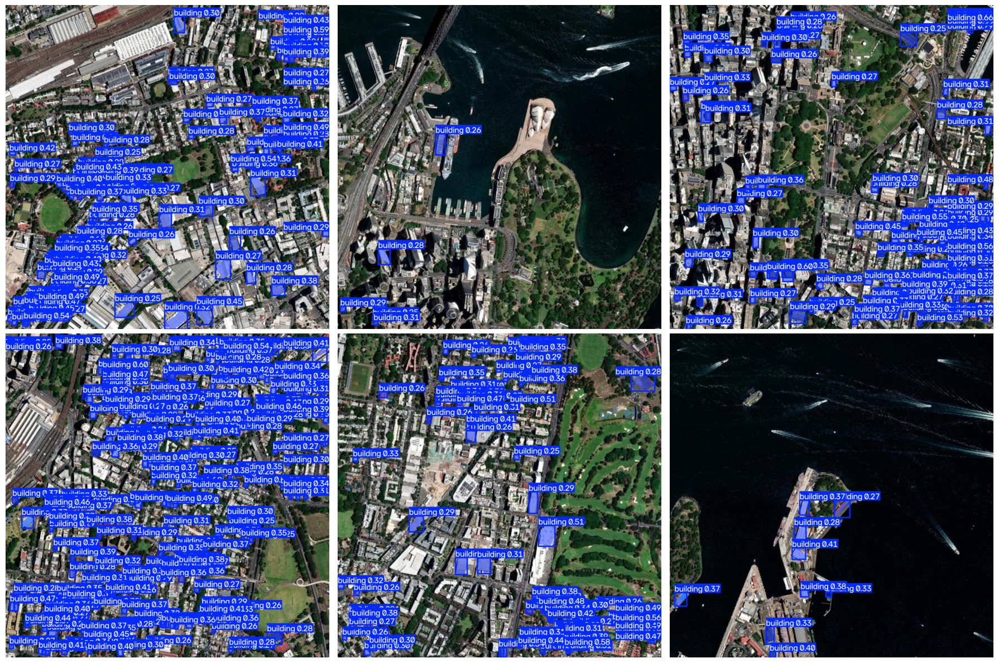

saved: /content/drive/MyDrive/aus_seg/runs/sydney_dense/test_predictions.png


In [17]:
# CELL 13 - visualize predictions on the test split
import glob
import matplotlib.pyplot as plt

test_imgs = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "test", "*.jpg")))[:6]
if test_imgs:
    preds = trained.predict(test_imgs, imgsz=yolo_imgsz, conf=0.25, device=device)
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    for ax, res in zip(axes.ravel(), preds):
        plotted = res.plot()[..., ::-1]  # BGR -> RGB
        ax.imshow(plotted)
        ax.axis("off")
    plt.tight_layout()
    out_png = os.path.join(RUNS_DIR, "test_predictions.png")
    plt.savefig(out_png, dpi=120, bbox_inches="tight")
    plt.show()
    print("saved:", out_png)

In [18]:
# CELL 14 - ONNX EXPORT (FP32)
# ----------------------------------------------------------------------------
# Export the trained best.pt to a floating-point ONNX model. This is NOT
# quantization - it is the source graph that gets quantized in CELL 16.
# ONNX EXPORT
import shutil
import onnx
import onnxruntime as ort
from collections import Counter

ONNX_IMGSZ = onnx_imgsz or yolo_imgsz


def export_fp32_onnx(weights_path, out_path, imgsz, opset):
    """Ultralytics YOLOv8-seg -> ONNX. simplify=True gives a cleaner graph that
    quantizes better; we retry without it if the simplifier is unavailable."""
    m = YOLO(weights_path)
    common = dict(format="onnx", imgsz=imgsz, opset=opset, dynamic=False,
                  half=False, device="cpu")
    try:
        exported = m.export(simplify=True, **common)
    except Exception as e:
        print(f"[export] simplify=True failed ({e}); retrying simplify=False")
        exported = m.export(simplify=False, **common)
    shutil.copy(str(exported), out_path)
    return out_path


def make_ort_session(path, cpu_only=True):
    so = ort.SessionOptions()
    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL
    providers = ["CPUExecutionProvider"] if cpu_only else ort.get_available_providers()
    return ort.InferenceSession(path, sess_options=so, providers=providers)


_EXPORT_META = os.path.join(ONNX_DIR, "_export_meta.json")


def _export_is_current():
    if not os.path.exists(ONNX_FP32) or not os.path.exists(_EXPORT_META):
        return False
    try:
        meta = json.load(open(_EXPORT_META))
    except Exception:
        return False
    return (os.path.exists(BEST_PT)
            and meta.get("opset") == onnx_opset and meta.get("imgsz") == ONNX_IMGSZ
            and meta.get("weights_mtime") == os.path.getmtime(BEST_PT))


def _onnx_runs(path):
    """Load + execute the graph on CPU with a dummy input; True if usable."""
    try:
        s = make_ort_session(path)
        x = np.zeros((1, 3, ONNX_IMGSZ, ONNX_IMGSZ), np.float32)
        s.run(None, {s.get_inputs()[0].name: x})
        return True
    except Exception as e:
        log(f"[WARN] ONNX validation failed for {os.path.basename(path)}: {e}")
        return False


if quantization_enabled:
    if resume and _export_is_current() and _onnx_runs(ONNX_FP32):
        log("[CHECK] FP32 ONNX already valid and matches best.pt -> SKIP export")
    else:
        log("[EXPORT] exporting best.pt -> best_fp32.onnx (FP32, NOT quantized)")
        export_fp32_onnx(BEST_PT, ONNX_FP32, ONNX_IMGSZ, onnx_opset)
        json.dump({"opset": onnx_opset, "imgsz": ONNX_IMGSZ,
                   "weights_mtime": os.path.getmtime(BEST_PT)}, open(_EXPORT_META, "w"))
        if not _onnx_runs(ONNX_FP32):
            raise RuntimeError("exported FP32 ONNX does not run on CPU; export failed")
    set_stage("onnx_export", "complete")
    log(f"[CHECK] FP32 ONNX: {ONNX_FP32} ({os.path.getsize(ONNX_FP32)/1e6:.2f} MB) "
        f"(opset={onnx_opset}, imgsz={ONNX_IMGSZ})")

    _fp32_sess = make_ort_session(ONNX_FP32)
    FP32_INPUT_NAME = _fp32_sess.get_inputs()[0].name
    log(f"[CHECK] ONNX input : {[(i.name, i.shape, i.type) for i in _fp32_sess.get_inputs()]}")
    log(f"[CHECK] ONNX output: {[(o.name, o.shape, o.type) for o in _fp32_sess.get_outputs()]}")
else:
    log("[CHECK] quantization_enabled=False -> skipping the ONNX / INT8 stage")

[EXPORT] exporting best.pt -> best_fp32.onnx (FP32, NOT quantized)
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.163 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
YOLOv8n-seg summary (fused): 85 layers, 3,258,259 parameters, 0 gradients, 11.3 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/aus_seg/runs/sydney_dense/aus_buildings_seg/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 37, 8400), (1, 32, 160, 160)) (6.5 MB)

ONNX: starting export with onnx 1.23.0 opset 13...
ONNX: slimming with onnxslim 0.1.96...
ONNX: export success ✅ 2.1s, saved as '/content/drive/MyDrive/aus_seg/runs/sydney_dense/aus_buildings_seg/weights/best.onnx' (12.7 MB)

Export complete (4.0s)
Results saved to /content/drive/MyDrive/aus_seg/runs/sydney_dense/aus_buildings_seg/weights/best.onnx
Predict:         yolo predict task=segment model=/content/drive/MyDrive/aus_seg/runs/sydney_dense/aus_bu

In [19]:
# CELL 15 - INT8 CALIBRATION
# ----------------------------------------------------------------------------
# Calibration MUST use training images (never the test split). Preprocessing is
# identical to what the exported YOLOv8 ONNX graph expects: BGR read, letterbox
# to imgsz, BGR->RGB, CHW, /255, float32, NCHW.
# INT8 CALIBRATION
import cv2
from onnxruntime.quantization import (quantize_static, QuantFormat, QuantType,
                                      CalibrationMethod, CalibrationDataReader)


def letterbox(im, new_shape=(640, 640), color=(114, 114, 114)):
    """Resize + pad keeping aspect ratio (same as Ultralytics)."""
    shape = im.shape[:2]
    r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
    new_unpad = (int(round(shape[1] * r)), int(round(shape[0] * r)))
    dw = (new_shape[1] - new_unpad[0]) / 2.0
    dh = (new_shape[0] - new_unpad[1]) / 2.0
    im = cv2.resize(im, new_unpad, interpolation=cv2.INTER_LINEAR)
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    return cv2.copyMakeBorder(im, top, bottom, left, right,
                              cv2.BORDER_CONSTANT, value=color)


def preprocess_onnx(img_path, imgsz):
    """Return NCHW float32 RGB tensor in [0,1] with batch dim (1,3,H,W)."""
    im = cv2.imread(str(img_path))
    if im is None:
        raise FileNotFoundError(img_path)
    im = letterbox(im, (imgsz, imgsz))
    im = im[:, :, ::-1]                                   # BGR -> RGB
    im = np.ascontiguousarray(im.transpose(2, 0, 1), dtype=np.float32) / 255.0
    return im[None]


class YoloCalibReader(CalibrationDataReader):
    """Feeds calibration images to onnxruntime.quantization."""

    def __init__(self, paths, imgsz, input_name):
        self.input_name = input_name
        self._data = [{input_name: preprocess_onnx(p, imgsz)} for p in paths]
        self._iter = iter(self._data)

    def get_next(self):
        return next(self._iter, None)

    def rewind(self):
        self._iter = iter(self._data)


def calibration_paths(n):
    """Training images only; fall back to val (never test) if train is empty."""
    train = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "train", "*.jpg")))
    if not train:
        train = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "val", "*.jpg")))
        print("[calib] no train images found, using val split for calibration")
    if not train:
        raise RuntimeError("no images available for calibration")
    return train[:n]


# persist the calibration set so it is identical on every restart (train only)
if quantization_enabled:
    _reuse_calib = False
    if resume and os.path.exists(CALIB_JSON):
        try:
            _saved = json.load(open(CALIB_JSON))
            if (_saved.get("imgsz") == ONNX_IMGSZ
                    and _saved.get("n") == quant_calib_samples
                    and _saved.get("paths")
                    and all(os.path.exists(p) for p in _saved["paths"])):
                CALIB_PATHS = _saved["paths"]
                _reuse_calib = True
        except Exception:
            _reuse_calib = False
    if not _reuse_calib:
        CALIB_PATHS = calibration_paths(quant_calib_samples)
        tmp = CALIB_JSON + ".tmp"
        with open(tmp, "w", encoding="utf-8") as f:
            json.dump({"imgsz": ONNX_IMGSZ, "n": quant_calib_samples,
                       "paths": CALIB_PATHS}, f, indent=2)
        os.replace(tmp, CALIB_JSON)
    log(f"[CHECK] calibration set: {len(CALIB_PATHS)} train images "
        f"({'reused' if _reuse_calib else 'created'})")
else:
    CALIB_PATHS = []

[CHECK] calibration set: 24 train images (created)


In [20]:
# CELL 16 - INT8 QUANTIZATION + VERIFY
# ----------------------------------------------------------------------------
# Static (QDQ) post-training quantization with ONNX Runtime. QOperator is used
# only as a fallback. Operators that ORT cannot quantize safely stay in FP32 -
# that is reported honestly below; we never rename an FP32 model as INT8.
# INT8 QUANTIZATION
_ACT = {"uint8": QuantType.QUInt8, "int8": QuantType.QInt8}[quant_activation_type]
_WGT = {"int8": QuantType.QInt8, "uint8": QuantType.QUInt8}[quant_weight_type]


def analyze_onnx_graph(path):
    """Inspect an ONNX graph and report the real quantization content."""
    g = onnx.load(path).graph
    op_hist = Counter(n.op_type for n in g.node)
    init_dtype = {t.name: t.data_type for t in g.initializer}
    int8_w = [t.name for t in g.initializer if t.data_type == onnx.TensorProto.INT8]
    uint8_w = [t.name for t in g.initializer if t.data_type == onnx.TensorProto.UINT8]
    float_w = [t.name for t in g.initializer if t.data_type == onnx.TensorProto.FLOAT]
    producer = {o: n for n in g.node for o in n.output}

    def weight_is_int8(weight_name):
        """True if a weight input resolves (directly or via DequantizeLinear)
        to an INT8 initializer."""
        if init_dtype.get(weight_name) == onnx.TensorProto.INT8:
            return True
        p = producer.get(weight_name)
        if p is not None and p.op_type == "DequantizeLinear" and p.input:
            return init_dtype.get(p.input[0]) == onnx.TensorProto.INT8
        return False

    conv_total = op_hist.get("Conv", 0)
    conv_int8 = sum(1 for n in g.node
                    if n.op_type == "Conv" and len(n.input) > 1
                    and weight_is_int8(n.input[1]))
    matmul_total = op_hist.get("MatMul", 0) + op_hist.get("Gemm", 0)
    matmul_int8 = sum(1 for n in g.node
                      if n.op_type in ("MatMul", "Gemm") and len(n.input) > 1
                      and weight_is_int8(n.input[1]))
    # op types that are genuinely left in FP32 (excludes compute ops that ORT
    # quantizes by wrapping them with Q/DQ pairs)
    qdq_and_compute = {"QuantizeLinear", "DequantizeLinear", "QLinearConv",
                       "QLinearMatMul", "ConvInteger", "MatMulInteger",
                       "DynamicQuantizeLinear", "Conv", "MatMul", "Gemm"}
    fp32_ops = sorted({op for op in op_hist if op not in qdq_and_compute})
    return dict(
        quantize_linear_nodes=op_hist.get("QuantizeLinear", 0),
        dequantize_linear_nodes=op_hist.get("DequantizeLinear", 0),
        int8_weight_initializers=len(int8_w),
        uint8_initializers=len(uint8_w),
        float_weight_initializers=len(float_w),
        conv_nodes=conv_total,
        conv_nodes_with_int8_weights=conv_int8,
        matmul_nodes=matmul_total,
        matmul_nodes_with_int8_weights=matmul_int8,
        op_type_histogram=dict(sorted(op_hist.items(), key=lambda kv: -kv[1])),
        fp32_remaining_op_types=fp32_ops,
    )


def output_producer_names(path):
    """Names of the nodes that directly produce the graph outputs."""
    g = onnx.load(path).graph
    prod = {o: n.name for n in g.node for o in n.output}
    return [prod[o.name] for o in g.output if o.name in prod]


def quantize_onnx(src, dst, calib_reader, nodes_to_exclude):
    """Static PTQ. Returns the QuantFormat string that succeeded."""
    common = dict(calibrate_method=CalibrationMethod.MinMax,
                  per_channel=quant_per_channel,
                  activation_type=_ACT, weight_type=_WGT,
                  nodes_to_exclude=nodes_to_exclude or None,
                  extra_options={"ActivationSymmetric": False,
                                 "WeightSymmetric": True})
    try:
        calib_reader.rewind()
        quantize_static(src, dst, calib_reader, quant_format=QuantFormat.QDQ, **common)
        return "QDQ"
    except Exception as e:
        print(f"[quant] QDQ failed: {e}\n[quant] falling back to QOperator")
        calib_reader.rewind()
        quantize_static(src, dst, calib_reader, quant_format=QuantFormat.QOperator, **common)
        return "QOperator"


quant_status = {"attempted": False, "succeeded": False, "format": None}
quant_report = None


def _int8_is_current():
    """True if best_int8.onnx exists, was built from THIS best_fp32.onnx and
    THIS calibration set, and its meta is readable."""
    if not (os.path.exists(ONNX_INT8) and os.path.exists(QUANT_META)):
        return False
    try:
        m = json.load(open(QUANT_META))
    except Exception:
        return False
    return (m.get("fp32_mtime") == os.path.getmtime(ONNX_FP32)
            and m.get("calib") == CALIB_PATHS
            and m.get("opset") == onnx_opset
            and m.get("per_channel") == quant_per_channel)


if quantization_enabled:
    quant_status["attempted"] = True
    if resume and _int8_is_current() and _onnx_runs(ONNX_INT8):
        _meta = json.load(open(QUANT_META))
        used_format = _meta.get("format", "QDQ")
        excluded_nodes = _meta.get("excluded_nodes", [])
        quant_report = analyze_onnx_graph(ONNX_INT8)
        quant_report["excluded_output_nodes"] = excluded_nodes
        _int8_sess = make_ort_session(ONNX_INT8)
        quant_status["succeeded"] = True
        quant_status["format"] = used_format
        log(f"[CHECK] INT8 model already valid -> SKIP quantization "
            f"({os.path.getsize(ONNX_INT8)/1e6:.2f} MB, format={used_format})")
        set_stage("quantization", "complete")
    else:
        log("[QUANTIZE] INT8 model not found/valid -> starting static quantization")
        # optional graph pre-processing (shape inference + symbolic shape fix)
        _pre = os.path.join(ONNX_DIR, "_best_fp32_pre.onnx")
        try:
            from onnxruntime.quantization.shape_inference import quant_pre_process
            quant_pre_process(ONNX_FP32, _pre, skip_symbolic_shape=False)
            _quant_src = _pre
            log("[QUANTIZE] quant_pre_process OK")
        except Exception as e:
            log(f"[QUANTIZE] quant_pre_process skipped ({e}); using raw FP32 graph")
            _quant_src = ONNX_FP32

        # the nodes that produce the graph outputs stay FP32 (see config comment)
        excluded_nodes = output_producer_names(_quant_src) if quant_exclude_output_nodes else []
        log(f"[QUANTIZE] keeping {len(excluded_nodes)} output node(s) in FP32: {excluded_nodes}")

        calib = YoloCalibReader(CALIB_PATHS, ONNX_IMGSZ, FP32_INPUT_NAME)
        used_format = quantize_onnx(_quant_src, ONNX_INT8, calib, excluded_nodes)

        quant_report = analyze_onnx_graph(ONNX_INT8)
        quant_report["excluded_output_nodes"] = excluded_nodes
        log("quantized graph report: " + json.dumps(
            {k: v for k, v in quant_report.items() if k != "op_type_histogram"}))
        log("quantized op histogram: " + json.dumps(
            {k: v for k, v in quant_report["op_type_histogram"].items()
             if k in ("QuantizeLinear", "DequantizeLinear", "Conv", "MatMul", "Sigmoid",
                      "Resize", "Concat", "Mul", "Split", "MaxPool", "Add")}))

        # HARD verification: real INT8 ops must exist, and it must run on CPU
        if quant_report["quantize_linear_nodes"] == 0 or quant_report["int8_weight_initializers"] == 0:
            raise RuntimeError(
                "INT8 quantization did NOT produce a quantized graph "
                "(no QuantizeLinear / int8 weights). Refusing to label it INT8.")
        try:
            _int8_sess = make_ort_session(ONNX_INT8)
            _probe = preprocess_onnx(CALIB_PATHS[0], ONNX_IMGSZ)
            _oi = _int8_sess.run(None, {FP32_INPUT_NAME: _probe})
        except Exception as e:
            raise RuntimeError(
                "Quantized ONNX is present but NOT runnable, so it is NOT usable INT8.\n"
                f"  reason: {e}\n"
                "  hints: use onnx_opset>=13 (needed for QDQ per-channel bias 'axis'),\n"
                "         or set quant_per_channel=False, or retry with QOperator."
            ) from e

        # sanity: the INT8 head must not collapse (class scores must survive)
        _of = _fp32_sess.run(None, {FP32_INPUT_NAME: _probe})
        _o0f, _o0i = np.asarray(_of[0])[0], np.asarray(_oi[0])[0]
        _nc = _o0f.shape[0] - 4 - 32
        if _nc >= 1 and _o0f[4:4 + _nc].max() > 1e-3 and _o0i[4:4 + _nc].max() < 1e-4:
            raise RuntimeError(
                "INT8 collapsed the class-score channels to 0. Keep "
                "quant_exclude_output_nodes=True (or exclude the head in FP32).")

        # publish the quant meta atomically so the next run can skip
        tmp = QUANT_META + ".tmp"
        with open(tmp, "w", encoding="utf-8") as f:
            json.dump({"fp32_mtime": os.path.getmtime(ONNX_FP32),
                       "calib": CALIB_PATHS, "opset": onnx_opset,
                       "per_channel": quant_per_channel, "format": used_format,
                       "excluded_nodes": excluded_nodes}, f, indent=2)
        os.replace(tmp, QUANT_META)

        quant_status["succeeded"] = True
        quant_status["format"] = used_format
        log(f"[QUANTIZE] INT8 ONNX: {ONNX_INT8} ({os.path.getsize(ONNX_INT8)/1e6:.2f} MB) "
            f"format={used_format} -> runs on CPUExecutionProvider OK")
        set_stage("quantization", "complete")

[QUANTIZE] INT8 model not found/valid -> starting static quantization
[QUANTIZE] quant_pre_process OK
[QUANTIZE] keeping 2 output node(s) in FP32: ['/model.22/Concat_4', '/model.22/proto/cv3/act/Mul']
quantized graph report: {"quantize_linear_nodes": 275, "dequantize_linear_nodes": 430, "int8_weight_initializers": 154, "uint8_initializers": 244, "float_weight_initializers": 398, "conv_nodes": 76, "conv_nodes_with_int8_weights": 76, "matmul_nodes": 0, "matmul_nodes_with_int8_weights": 0, "fp32_remaining_op_types": ["Add", "Concat", "ConvTranspose", "Div", "MaxPool", "Mul", "Reshape", "Resize", "Sigmoid", "Slice", "Softmax", "Split", "Sub", "Transpose"], "excluded_output_nodes": ["/model.22/Concat_4", "/model.22/proto/cv3/act/Mul"]}
quantized op histogram: {"DequantizeLinear": 430, "QuantizeLinear": 275, "Conv": 76, "Sigmoid": 67, "Mul": 67, "Concat": 18, "Split": 8, "Add": 8, "MaxPool": 3, "Resize": 2}
[QUANTIZE] INT8 ONNX: /content/drive/MyDrive/aus_seg/onnx/best_int8.onnx (3.75 MB) fo

In [21]:
# CELL 17 - CPU INFERENCE TEST (onnxruntime, CPUExecutionProvider)
# ----------------------------------------------------------------------------
# Raw onnxruntime inference plus a numpy re-implementation of the YOLOv8-seg
# post-processing so the INT8 model is usable on its own (no GPU, no PyTorch).
# CPU INFERENCE TEST
def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def _nms_np(boxes, scores, iou_thres):
    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    areas = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    order = scores.argsort()[::-1]
    keep = []
    while order.size > 0:
        i = order[0]
        keep.append(i)
        if order.size == 1:
            break
        xx1 = np.maximum(x1[i], x1[order[1:]])
        yy1 = np.maximum(y1[i], y1[order[1:]])
        xx2 = np.minimum(x2[i], x2[order[1:]])
        yy2 = np.minimum(y2[i], y2[order[1:]])
        inter = np.maximum(0.0, xx2 - xx1) * np.maximum(0.0, yy2 - yy1)
        iou = inter / np.maximum(areas[i] + areas[order[1:]] - inter, 1e-9)
        order = order[1:][iou <= iou_thres]
    return np.array(keep, dtype=np.int64)


def _crop_mask(masks, boxes):
    n, h, w = masks.shape
    ys = np.arange(h)[None, :, None]
    xs = np.arange(w)[None, None, :]
    x1, y1, x2, y2 = (boxes[:, k][:, None, None] for k in range(4))
    return masks * ((xs >= x1) & (xs < x2) & (ys >= y1) & (ys < y2))


def postprocess_yolov8_seg(outputs, imgsz, conf_thres=0.25, iou_thres=0.45,
                           nc=1, nm=32):
    """Decode raw YOLOv8-seg ONNX outputs -> boxes/scores/classes/masks."""
    pred = proto = None
    for o in outputs:
        o = np.asarray(o)
        if o.ndim == 3 and o.shape[1] == 4 + nc + nm:
            pred = o[0]
        elif o.ndim == 4 and o.shape[1] == nm:
            proto = o[0]
    if pred is None or proto is None:
        raise ValueError(f"unexpected ONNX output shapes: {[np.asarray(o).shape for o in outputs]}")

    box = pred[:4].T                      # (N,4) cx,cy,w,h in input px
    cls_scores = pred[4:4 + nc].T         # (N,nc)
    coeffs = pred[4 + nc:].T              # (N,nm)
    conf = cls_scores.max(1)
    cls = cls_scores.argmax(1)
    m = conf >= conf_thres
    box, coeffs, conf, cls = box[m], coeffs[m], conf[m], cls[m]

    empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0),
                 classes=np.zeros(0, dtype=int), masks=np.zeros((0, imgsz, imgsz)))
    if box.shape[0] == 0:
        return empty

    xyxy = np.empty_like(box)
    xyxy[:, 0] = box[:, 0] - box[:, 2] / 2
    xyxy[:, 1] = box[:, 1] - box[:, 3] / 2
    xyxy[:, 2] = box[:, 0] + box[:, 2] / 2
    xyxy[:, 3] = box[:, 1] + box[:, 3] / 2
    k = _nms_np(xyxy, conf, iou_thres)
    xyxy, coeffs, conf, cls = xyxy[k], coeffs[k], conf[k], cls[k]

    c, mh, mw = proto.shape
    masks = _sigmoid(coeffs @ proto.reshape(c, -1)).reshape(-1, mh, mw)
    masks = _crop_mask(masks, xyxy / (imgsz / mh))
    up = np.stack([cv2.resize(mm, (imgsz, imgsz), interpolation=cv2.INTER_LINEAR)
                   for mm in masks]) if len(masks) else np.zeros((0, imgsz, imgsz))
    return dict(boxes=xyxy, scores=conf, classes=cls, masks=up)


def run_onnx_cpu(session, input_name, img_path, imgsz):
    x = preprocess_onnx(img_path, imgsz)
    return session.run(None, {input_name: x}), x


if quantization_enabled and cpu_inference_enabled:
    INT8_INPUT_NAME = _int8_sess.get_inputs()[0].name
    test_imgs_cpu = CALIB_PATHS[:min(4, len(CALIB_PATHS))]
    n_ok = 0
    for p in test_imgs_cpu:
        outs, _ = run_onnx_cpu(_int8_sess, INT8_INPUT_NAME, p, ONNX_IMGSZ)
        det = postprocess_yolov8_seg(outs, ONNX_IMGSZ)
        finite = all(np.isfinite(np.asarray(o)).all() for o in outs)
        if finite:
            n_ok += 1
            try:  # save a segmentation overlay (no GPU, no PyTorch needed)
                im = cv2.imread(str(p))
                h, w = im.shape[:2]
                for m in det["masks"]:
                    mb = cv2.resize((m > 0.5).astype(np.uint8), (w, h),
                                    interpolation=cv2.INTER_NEAREST)
                    im[mb > 0] = (0.5 * im[mb > 0] + 0.5 * np.array([0, 0, 255])).astype(np.uint8)
                cv2.imwrite(os.path.join(PRED_DIR, "int8_" + os.path.basename(p)), im)
            except Exception as e:
                log(f"[WARN] could not render prediction for {os.path.basename(p)}: {e}")
        log(f"[CPU] INT8 {os.path.basename(p)}: outputs={[np.asarray(o).shape for o in outs]} "
            f"finite={finite} detections={len(det['scores'])}")
    log(f"[CPU] INT8 inference test passed on {n_ok}/{len(test_imgs_cpu)} images "
        f"-> overlays in {PRED_DIR}")
    set_stage("cpu_inference", "complete")

[CPU] INT8 20089_13101.jpg: outputs=[(1, 37, 8400), (1, 32, 160, 160)] finite=True detections=137
[CPU] INT8 20089_13102.jpg: outputs=[(1, 37, 8400), (1, 32, 160, 160)] finite=True detections=340
[CPU] INT8 20089_13103.jpg: outputs=[(1, 37, 8400), (1, 32, 160, 160)] finite=True detections=300
[CPU] INT8 20089_13104.jpg: outputs=[(1, 37, 8400), (1, 32, 160, 160)] finite=True detections=133
[CPU] INT8 inference test passed on 4/4 images -> overlays in /content/drive/MyDrive/aus_seg/predictions
[STATE] cpu_inference = complete


In [22]:
# CELL 18 - FP32 VS INT8 COMPARISON + SIZE + CPU BENCHMARK + METRICS
# FP32 VS INT8 COMPARISON
def mask_iou(a, b):
    inter = np.logical_and(a, b).sum()
    union = np.logical_or(a, b).sum()
    return float(inter / union) if union else 0.0


def best_match_iou(masks_a, masks_b, thresh=0.5):
    """Greedy best-match mean IoU between two mask sets (binary at `thresh`)."""
    if len(masks_a) == 0 or len(masks_b) == 0:
        return 0.0, 0
    A = masks_a > thresh
    B = masks_b > thresh
    ious = []
    for a in A:
        ious.append(max(mask_iou(a, b) for b in B))
    return float(np.mean(ious)), len(ious)


def compare_fp32_int8(n_samples):
    val_imgs = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "val", "*.jpg")))
    if not val_imgs:
        val_imgs = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "test", "*.jpg")))
    imgs = val_imgs[:n_samples]
    if not imgs:
        return None
    fp32_sess = make_ort_session(ONNX_FP32)
    int8_sess = make_ort_session(ONNX_INT8)
    fi, ii = fp32_sess.get_inputs()[0].name, int8_sess.get_inputs()[0].name

    abs_errs, max_err, det_fp32, det_int8, ious, n = [], 0.0, 0, 0, [], 0
    for p in tqdm(imgs, desc="compare FP32 vs INT8", unit="img"):
        of = fp32_sess.run(None, {fi: preprocess_onnx(p, ONNX_IMGSZ)})
        oi = int8_sess.run(None, {ii: preprocess_onnx(p, ONNX_IMGSZ)})
        for a, b in zip(of, oi):
            a, b = np.asarray(a, np.float32), np.asarray(b, np.float32)
            if a.shape != b.shape:
                continue
            d = np.abs(a - b)
            abs_errs.append(float(d.mean()))
            max_err = max(max_err, float(d.max()))
        df = postprocess_yolov8_seg(of, ONNX_IMGSZ)
        di = postprocess_yolov8_seg(oi, ONNX_IMGSZ)
        det_fp32 += len(df["scores"])
        det_int8 += len(di["scores"])
        miou, matched = best_match_iou(df["masks"], di["masks"])
        if matched:
            ious.append(miou)
        n += 1
    return dict(
        compared_samples=n,
        mean_absolute_error=float(np.mean(abs_errs)) if abs_errs else 0.0,
        max_absolute_error=float(max_err),
        detections_fp32=det_fp32,
        detections_int8=det_int8,
        mean_best_match_mask_iou=float(np.mean(ious)) if ious else 0.0,
    )

In [23]:
# MODEL SIZE / COMPRESSION + CPU BENCHMARK + METRICS FILE
def cpu_benchmark(n_runs, n_warmup):
    fp32_sess = make_ort_session(ONNX_FP32)
    int8_sess = make_ort_session(ONNX_INT8)
    paths = CALIB_PATHS[:min(4, len(CALIB_PATHS))]
    xs = [preprocess_onnx(p, ONNX_IMGSZ) for p in paths]
    fi, ii = fp32_sess.get_inputs()[0].name, int8_sess.get_inputs()[0].name

    def timeit(sess, name):
        for i in range(n_warmup):
            sess.run(None, {name: xs[i % len(xs)]})
        t0 = time.perf_counter()
        for i in range(n_runs):
            sess.run(None, {name: xs[i % len(xs)]})
        return (time.perf_counter() - t0) / n_runs * 1000.0

    return timeit(fp32_sess, fi), timeit(int8_sess, ii)


if quantization_enabled and quant_status["succeeded"]:
    metrics = {
        "quantization_bits": quant_bits,
        "quantization_type": "static",
        "quantization_format": quant_status["format"],
        "weights_dtype": quant_weight_type,
        "activation_dtype": quant_activation_type,
        "per_channel": quant_per_channel,
        "calibration_samples": len(CALIB_PATHS),
        "calibration_source": "train split",
        "source_model_path": BEST_PT,
        "float_model_path": ONNX_FP32,
        "quantized_model_path": ONNX_INT8,
        "float_model_size_mb": round(os.path.getsize(ONNX_FP32) / 1e6, 4),
        "quantized_model_size_mb": round(os.path.getsize(ONNX_INT8) / 1e6, 4),
        "compression_ratio": round(os.path.getsize(ONNX_FP32) /
                                   os.path.getsize(ONNX_INT8), 4),
        "quantize_linear_nodes": quant_report["quantize_linear_nodes"],
        "dequantize_linear_nodes": quant_report["dequantize_linear_nodes"],
        "int8_weight_initializers": quant_report["int8_weight_initializers"],
        "uint8_initializers": quant_report["uint8_initializers"],
        "float_weight_initializers": quant_report["float_weight_initializers"],
        "conv_nodes": quant_report["conv_nodes"],
        "conv_nodes_with_int8_weights": quant_report["conv_nodes_with_int8_weights"],
        "matmul_nodes": quant_report["matmul_nodes"],
        "matmul_nodes_with_int8_weights": quant_report["matmul_nodes_with_int8_weights"],
        "excluded_output_nodes_fp32": quant_report["excluded_output_nodes"],
        "fp32_remaining_op_types": quant_report["fp32_remaining_op_types"],
        "cpu_inference_success": True,
    }

    cmp_res = compare_fp32_int8(onnx_compare_samples)
    if cmp_res:
        metrics.update(cmp_res)

    if cpu_inference_enabled:
        t_fp32, t_int8 = cpu_benchmark(onnx_bench_runs, onnx_bench_warmup)
        metrics.update(
            fp32_inference_ms=round(t_fp32, 2),
            int8_inference_ms=round(t_int8, 2),
            cpu_speedup=round(t_fp32 / t_int8, 3) if t_int8 else None,
            benchmark_runs=onnx_bench_runs,
        )
        print(f"CPU benchmark: FP32 {t_fp32:.2f} ms/img | INT8 {t_int8:.2f} ms/img "
              f"| speedup {t_fp32 / t_int8:.2f}x")

    with open(QUANT_METRICS_PATH, "w") as f:
        json.dump(metrics, f, indent=2)
    print("quantization metrics ->", QUANT_METRICS_PATH)
    print(json.dumps({k: v for k, v in metrics.items()
                      if k != "fp32_remaining_op_types"}, indent=2))
else:
    print("quantization not completed -> no quantization_metrics.json written")

compare FP32 vs INT8:   0%|          | 0/16 [00:00<?, ?img/s]

CPU benchmark: FP32 122.64 ms/img | INT8 104.01 ms/img | speedup 1.18x
quantization metrics -> /content/drive/MyDrive/aus_seg/onnx/quantization_metrics.json
{
  "quantization_bits": 8,
  "quantization_type": "static",
  "quantization_format": "QDQ",
  "weights_dtype": "int8",
  "activation_dtype": "uint8",
  "per_channel": true,
  "calibration_samples": 24,
  "calibration_source": "train split",
  "source_model_path": "/content/drive/MyDrive/aus_seg/runs/sydney_dense/aus_buildings_seg/weights/best.pt",
  "float_model_path": "/content/drive/MyDrive/aus_seg/onnx/best_fp32.onnx",
  "quantized_model_path": "/content/drive/MyDrive/aus_seg/onnx/best_int8.onnx",
  "float_model_size_mb": 13.2879,
  "quantized_model_size_mb": 3.7497,
  "compression_ratio": 3.5437,
  "quantize_linear_nodes": 275,
  "dequantize_linear_nodes": 430,
  "int8_weight_initializers": 154,
  "uint8_initializers": 244,
  "float_weight_initializers": 398,
  "conv_nodes": 76,
  "conv_nodes_with_int8_weights": 76,
  "matmul_

In [24]:
# CELL 19 - save a run summary
summary = dict(
    profile=PROFILE,
    config=CONFIG,
    patches_total=len(all_patches),
    built=built,
    skipped=dict(skipped),
    split_blocks={k: len(v) for k, v in (("train", tr_b), ("val", va_b), ("test", te_b))},
    buildings_indexed=int(cnt_all.sum()),
    artifacts=dict(work_dir=work_dir, best_pt=BEST_PT, fp32_onnx=ONNX_FP32,
                   int8_onnx=ONNX_INT8, metrics=QUANT_METRICS_PATH,
                   manifest=MANIFEST_PATH, state=STATE_PATH, splits=SPLITS_DIR,
                   predictions=PRED_DIR, checkpoints=CHECKPOINT_DIR),
)
with open(os.path.join(work_dir, "run_summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
log("[SUMMARY] " + json.dumps({k: v for k, v in summary.items()
                               if k not in ("config", "artifacts")}))
log(f"[DONE] all artifacts in {work_dir}")

[SUMMARY] {"profile": "custom", "patches_total": 206, "built": {"train": 168, "val": 19, "test": 19}, "skipped": {"blank": 0, "no_polygons": 0, "skipped": 0, "failed": 0}, "split_blocks": {"train": 168, "val": 19, "test": 19}, "buildings_indexed": 302454}
[DONE] all artifacts in /content/drive/MyDrive/aus_seg


In [25]:
# CELL 20 - inference-only helpers: run the trained model on ANY area
# ----------------------------------------------------------------------------
# This does not need the Kaggle data at all. Give it a lon/lat bbox and it will
# download imagery, predict and save overlays + a GeoJSON of building polygons.
# Great for checking how the Australia-trained model behaves on other cities
# (domain gap), e.g. Tehran.
def pixel_to_lonlat(X, Y, z, ox, oy):
    return tile_to_lonlat(ox + X / 256.0, oy + Y / 256.0, z)


def _load_seg_model(weights=None):
    from ultralytics import YOLO
    weights = weights or os.path.join(RUNS_DIR, "aus_buildings_seg", "weights", "best.pt")
    assert os.path.exists(weights), f"weights not found: {weights} (train first, or pass weights=...)"
    return YOLO(weights)


def predict_bbox(bbox, out_dir, weights=None, conf=0.25, imgsz=None, save_geojson=True):
    """bbox = (xmin, ymin, xmax, ymax) in lon/lat. Downloads imagery for every
    patch covering the bbox, predicts, and saves annotated patches + GeoJSON."""
    imgsz = imgsz or yolo_imgsz
    model = _load_seg_model(weights)
    xmin, ymin, xmax, ymax = bbox
    tx0, ty0 = lonlat_to_tile_f(xmin, ymax, zoom)   # top-left
    tx1, ty1 = lonlat_to_tile_f(xmax, ymin, zoom)   # bottom-right
    px0, py0 = int(tx0) // patch_tiles, int(ty0) // patch_tiles
    px1, py1 = int(tx1) // patch_tiles, int(ty1) // patch_tiles
    os.makedirs(out_dir, exist_ok=True)
    patches = [(px, py) for py in range(py0, py1 + 1) for px in range(px0, px1 + 1)]
    feats, n_patches, n_polys = [], 0, 0
    for px, py in tqdm(patches, desc="inference", unit="patch"):
        ox, oy = px * patch_tiles, py * patch_tiles
        needed = [(zoom, ox + dx, oy + dy)
                  for dy in range(patch_tiles) for dx in range(patch_tiles)]
        with cf.ThreadPoolExecutor(max_workers=download_workers) as ex:
            list(ex.map(lambda t: fetch_tile(*t), needed))
        img = stitch_patch(px, py)
        if img is None:
            continue
        res = model.predict(img, imgsz=imgsz, conf=conf, device=device, verbose=False)[0]
        if res.masks is None or len(res.masks) == 0:
            continue
        n_patches += 1
        Image.fromarray(res.plot()[..., ::-1]).save(
            os.path.join(out_dir, f"pred_{px}_{py}.jpg"), quality=jpeg_quality)
        for poly in res.masks.xy:
            ring = [list(pixel_to_lonlat(float(X), float(Y), zoom, ox, oy)) for X, Y in poly]
            if len(ring) >= 3:
                feats.append({"type": "Feature",
                              "properties": {"patch": f"{px}_{py}"},
                              "geometry": {"type": "Polygon", "coordinates": [ring]}})
                n_polys += 1
    if save_geojson:
        with open(os.path.join(out_dir, "predictions.geojson"), "w") as f:
            json.dump({"type": "FeatureCollection", "features": feats}, f)
    print(f"inference done: {n_patches} patches with buildings, "
          f"{n_polys} polygons -> {out_dir}")
    return feats


def predict_images(paths, out_dir, weights=None, conf=0.25, imgsz=None):
    """Run the trained model on local image files and save the overlays."""
    imgsz = imgsz or yolo_imgsz
    model = _load_seg_model(weights)
    os.makedirs(out_dir, exist_ok=True)
    for p in tqdm(paths, desc="inference", unit="img"):
        res = model.predict(p, imgsz=imgsz, conf=conf, device=device, verbose=False)[0]
        Image.fromarray(res.plot()[..., ::-1]).save(os.path.join(out_dir, os.path.basename(p)))
    print(f"inference done: {len(paths)} images -> {out_dir}")


# --- examples (uncomment and run after training) ----------------------------
# a small area of central Tehran:
# predict_bbox((51.38, 35.68, 51.43, 35.72),
#              out_dir=os.path.join(work_dir, "infer_tehran"), conf=0.25)
#
# or run on local images:
# predict_images(glob.glob("/content/my_images/*.jpg"),
#                out_dir=os.path.join(work_dir, "infer_local"))

evaluating 10 images


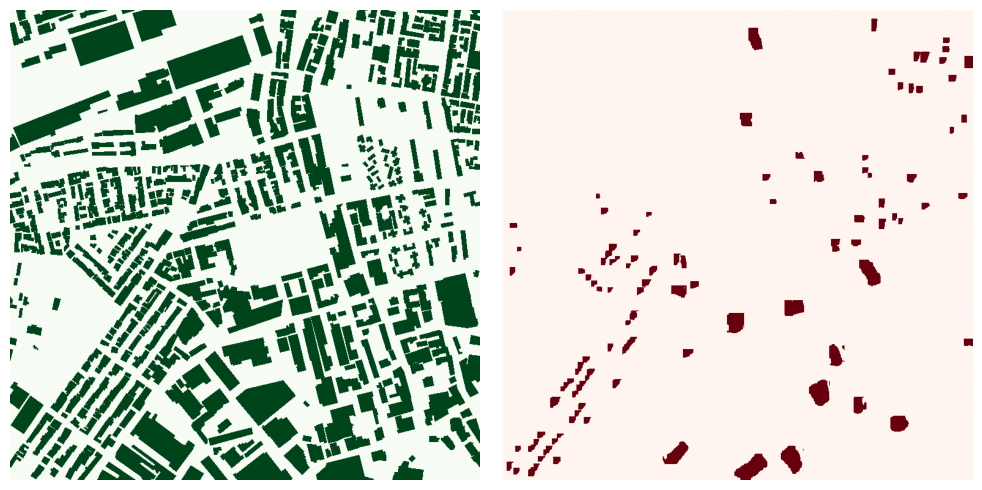

[01] 20097_13111.jpg
      real area      = 877,282 m2
      detected area  = 81,314 m2
      IoU (accuracy) = 0.077


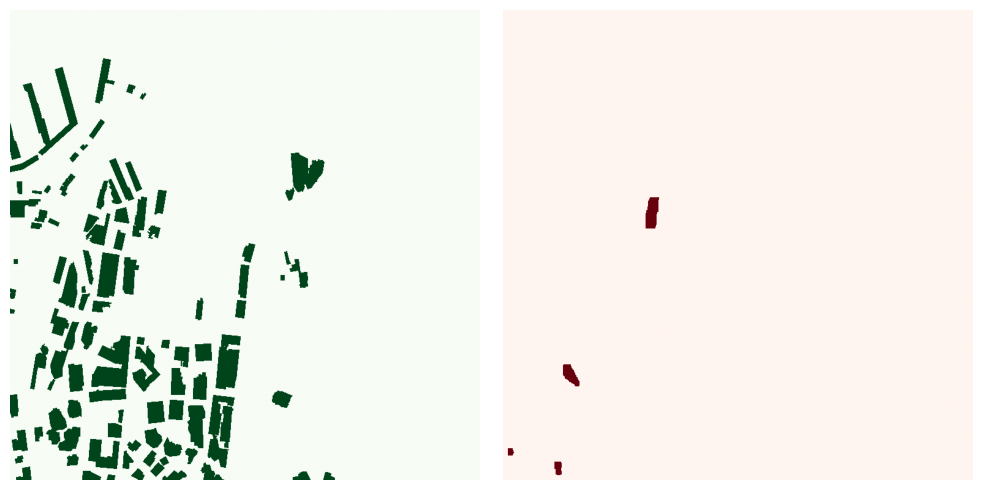

[02] 20098_13108.jpg
      real area      = 244,333 m2
      detected area  = 7,114 m2
      IoU (accuracy) = 0.015


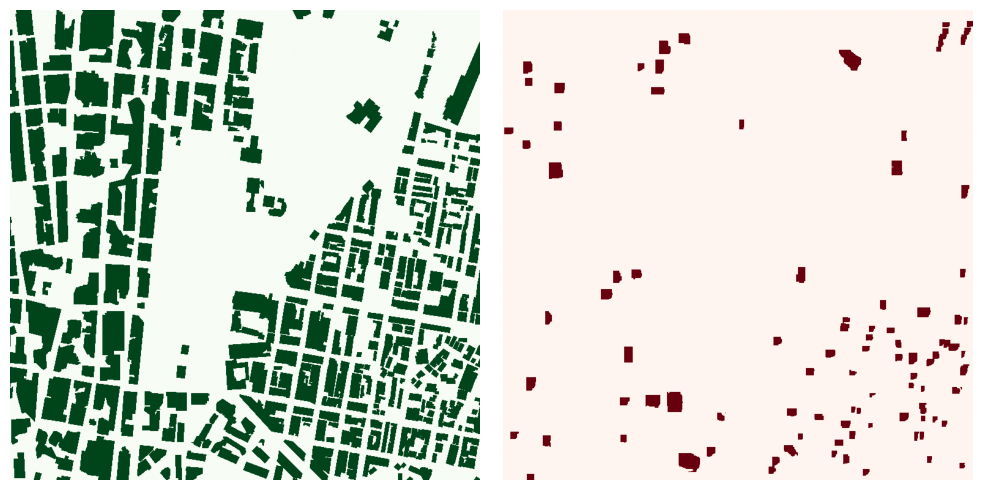

[03] 20098_13109.jpg
      real area      = 843,418 m2
      detected area  = 69,690 m2
      IoU (accuracy) = 0.056


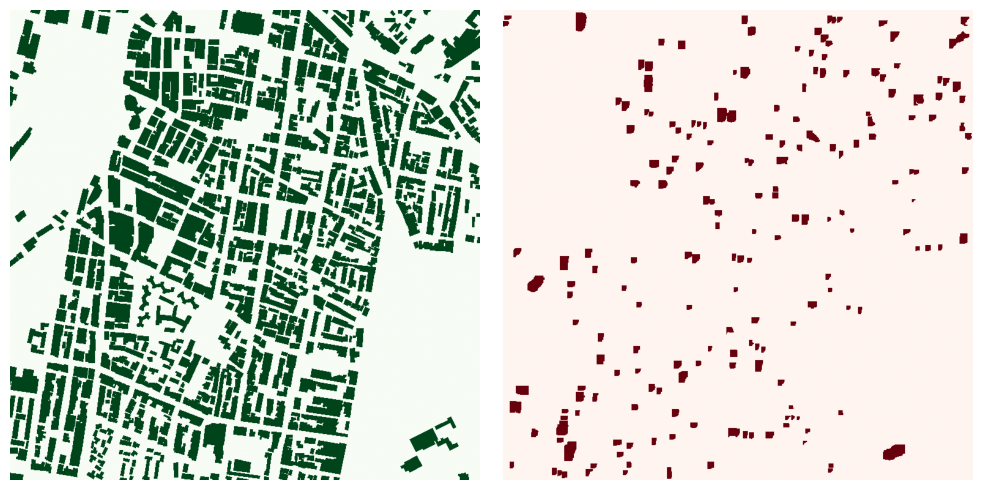

[04] 20098_13110.jpg
      real area      = 809,086 m2
      detected area  = 93,773 m2
      IoU (accuracy) = 0.081


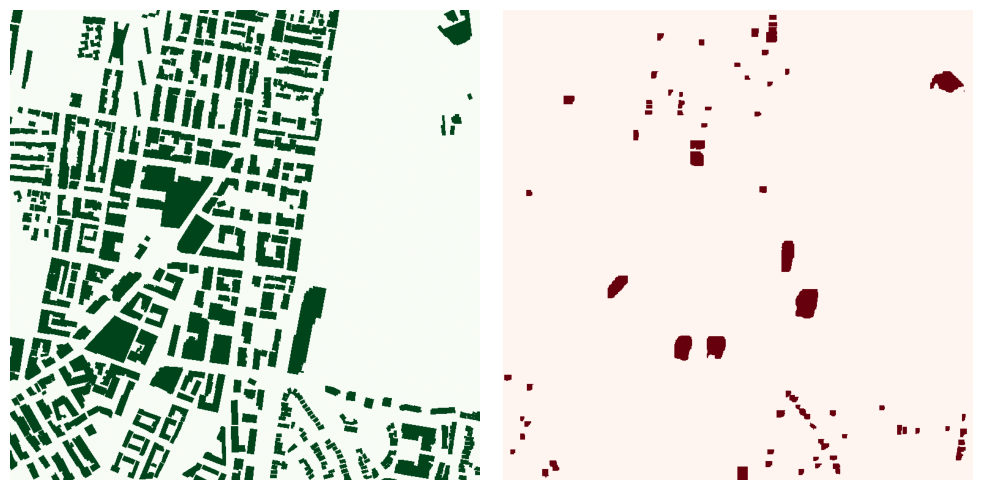

[05] 20098_13111.jpg
      real area      = 630,739 m2
      detected area  = 53,527 m2
      IoU (accuracy) = 0.065


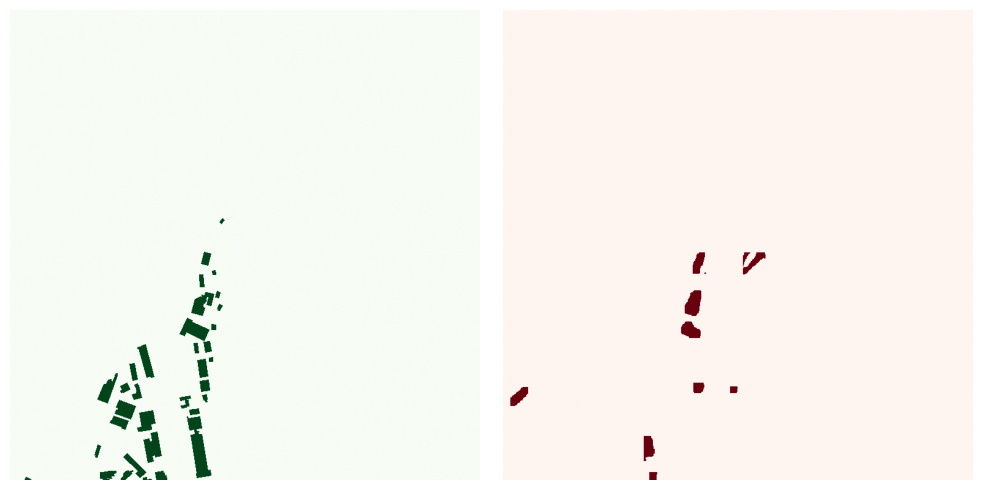

[06] 20099_13108.jpg
      real area      = 47,148 m2
      detected area  = 16,328 m2
      IoU (accuracy) = 0.167


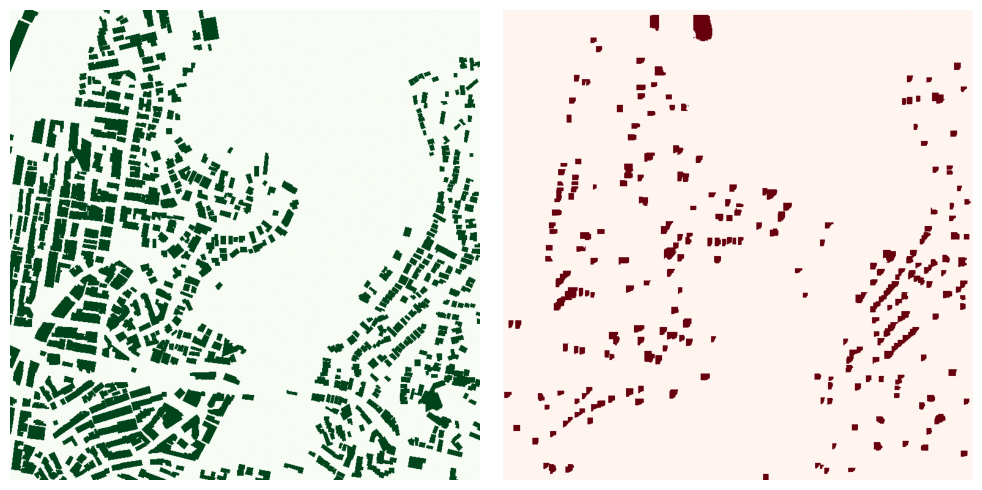

[07] 20099_13109.jpg
      real area      = 538,189 m2
      detected area  = 113,314 m2
      IoU (accuracy) = 0.134


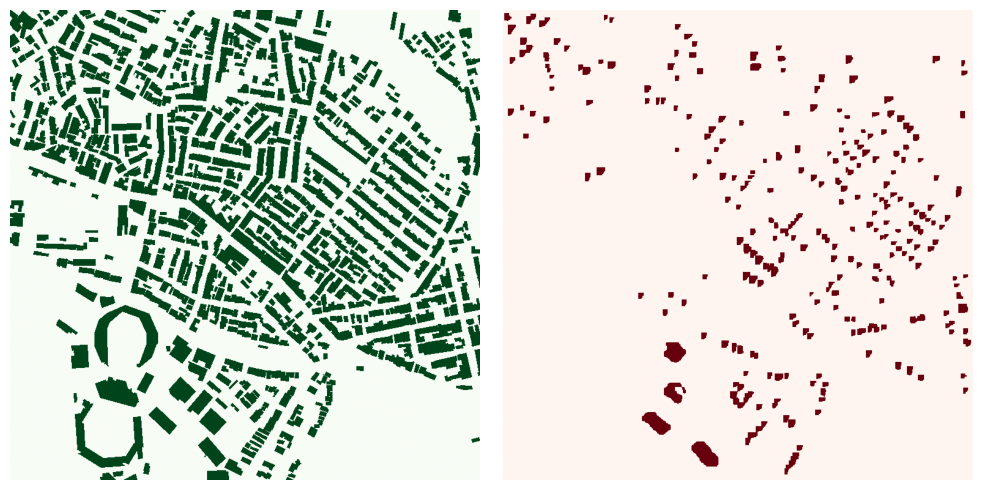

[08] 20099_13110.jpg
      real area      = 693,594 m2
      detected area  = 103,640 m2
      IoU (accuracy) = 0.107


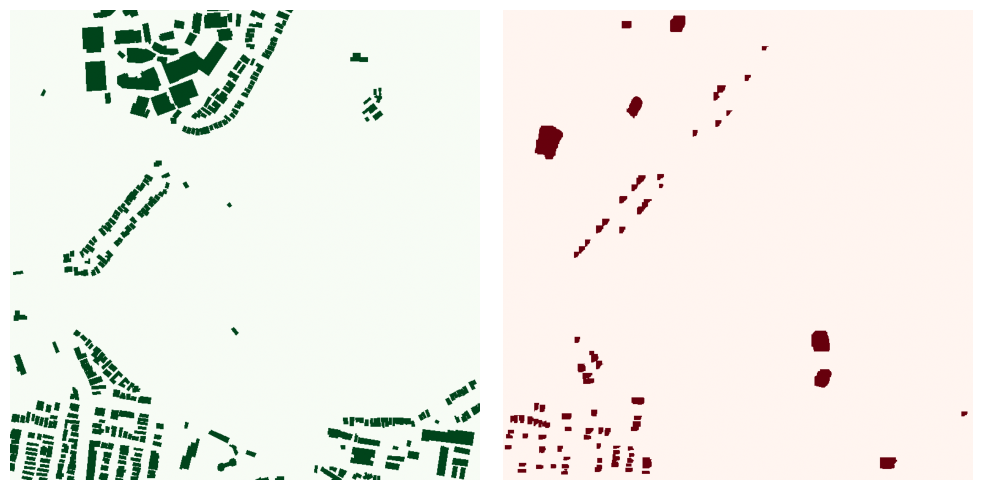

[09] 20099_13111.jpg
      real area      = 215,404 m2
      detected area  = 48,619 m2
      IoU (accuracy) = 0.112


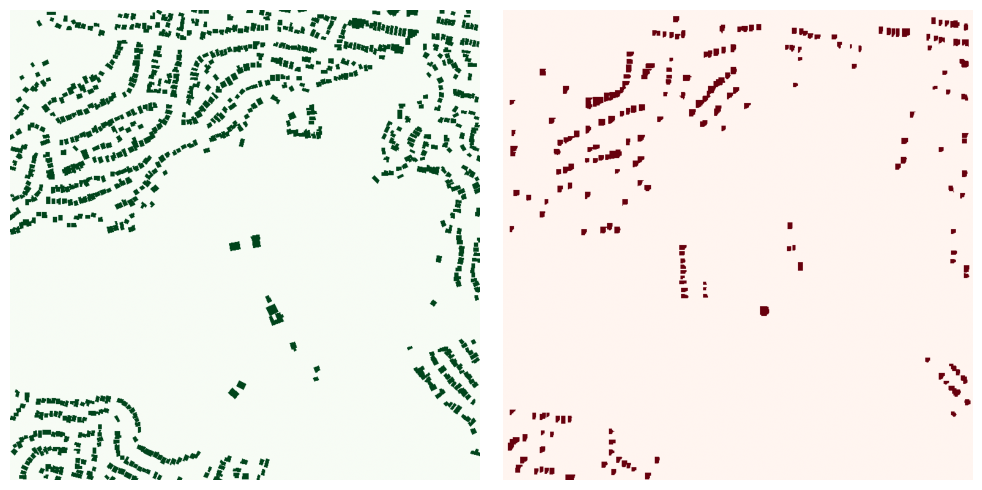

[10] 20100_13104.jpg
      real area      = 236,515 m2
      detected area  = 67,979 m2
      IoU (accuracy) = 0.173
mean IoU over 10 images = 0.099


In [26]:
# ============================================================================
# CELL 21 - دقت سگمنت‌سازی ساختمان روی ۱۰ عکس (مساحت + IoU)
# ----------------------------------------------------------------------------
# برای ۱۰ عکس تست: ماسک پیش‌بینی‌شده رو با برچسب واقعی مقایسه می‌کنه و دو تا
# ماسک تمیز (واقعی vs پیش‌بینی) رو بدون هیچ متنی روی عکس نشون می‌ده. زیر هر
# جفت، مساحت واقعی، مساحت تشخیص‌داده‌شده و IoU (نسبت دقت) رو چاپ می‌کنه.
# ============================================================================
import math
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

EVAL_N = 10          # تعداد عکس‌ها
EVAL_CONF = 0.25     # آستانه اطمینان


# متر بر پیکسل در رزولوشن اصلی پچ (zoom 16) برای عرض جغرافیایی میانی شهر
_lat = (city_bbox[1] + city_bbox[3]) / 2.0
_mpp = 156543.03 * math.cos(math.radians(_lat)) / (2.0 ** zoom)


def _load_gt_mask(img_path, size):
    """پلیگون‌های واقعی YOLO-seg رو به ماسک باینری تبدیل می‌کنه."""
    lbl = img_path.replace(os.path.join(YOLO_DIR, "images"),
                           os.path.join(YOLO_DIR, "labels"))
    lbl = os.path.splitext(lbl)[0] + ".txt"
    mask = np.zeros((size[1], size[0]), np.uint8)
    if not os.path.exists(lbl):
        return mask
    with open(lbl, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.split()
            if len(parts) < 7:
                continue
            pts = (np.asarray(parts[1:], dtype=np.float32).reshape(-1, 2)
                   * np.asarray(size, dtype=np.float32)).astype(np.int32)
            cv2.fillPoly(mask, [pts], 1)
    return mask


def _pred_mask(res, size):
    """اجتماع ماسک‌های پیش‌بینی‌شده در رزولوشن `size`."""
    if res.masks is None or len(res.masks.data) == 0:
        return np.zeros((size[1], size[0]), np.uint8)
    m = (res.masks.data.detach().cpu().numpy() > 0.5).max(axis=0).astype(np.uint8)
    if m.shape[:2] != (size[1], size[0]):
        m = cv2.resize(m, size, interpolation=cv2.INTER_NEAREST)
    return m


test_imgs = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "test", "*.jpg")))
if len(test_imgs) < EVAL_N:
    test_imgs = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "val", "*.jpg")))
test_imgs = test_imgs[:EVAL_N]
print(f"evaluating {len(test_imgs)} images")

ious = []
for i, img_path in enumerate(test_imgs):
    im = cv2.imread(img_path)
    size = (im.shape[1], im.shape[0])          # (W, H)

    gt = _load_gt_mask(img_path, size)
    res = trained.predict(img_path, imgsz=yolo_imgsz, conf=EVAL_CONF,
                          device=device, verbose=False)[0]
    pr = _pred_mask(res, size)

    inter = np.logical_and(gt, pr).sum()
    union = np.logical_or(gt, pr).sum()
    iou = float(inter / union) if union else 0.0
    ious.append(iou)

    gt_area = float(gt.sum()) * _mpp * _mpp
    pr_area = float(pr.sum()) * _mpp * _mpp

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(gt, cmap="Greens", vmin=0, vmax=1)   # واقعی
    axes[1].imshow(pr, cmap="Reds", vmin=0, vmax=1)     # پیش‌بینی
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    print(f"[{i+1:02d}] {os.path.basename(img_path)}")
    print(f"      real area      = {gt_area:,.0f} m2")
    print(f"      detected area  = {pr_area:,.0f} m2")
    print(f"      IoU (accuracy) = {iou:.3f}")

mean_iou = float(np.mean(ious)) if ious else 0.0
print("=" * 40)
print(f"mean IoU over {len(ious)} images = {mean_iou:.3f}")

evaluating 19 images


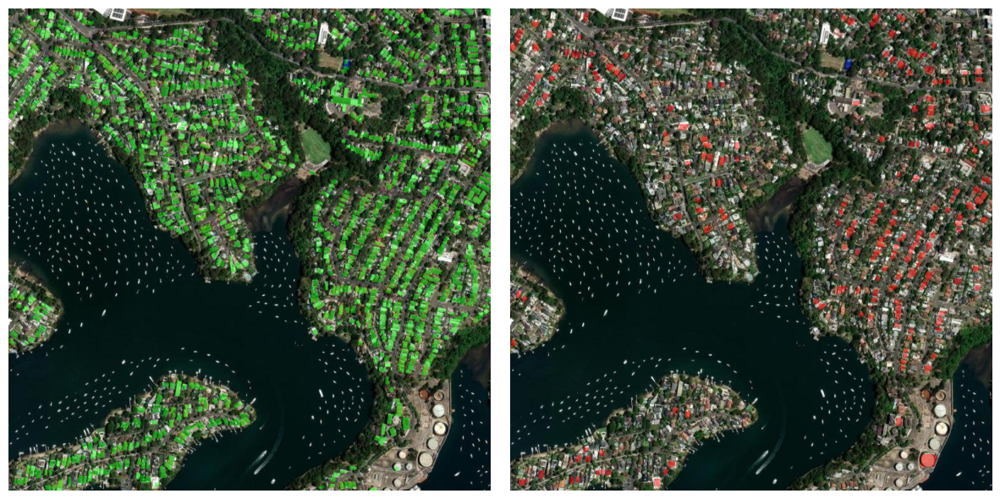

[01] 20096_13106.jpg
      real area      = 299,590 m2
      detected area  = 59,312 m2
      IoU (accuracy) = 0.133


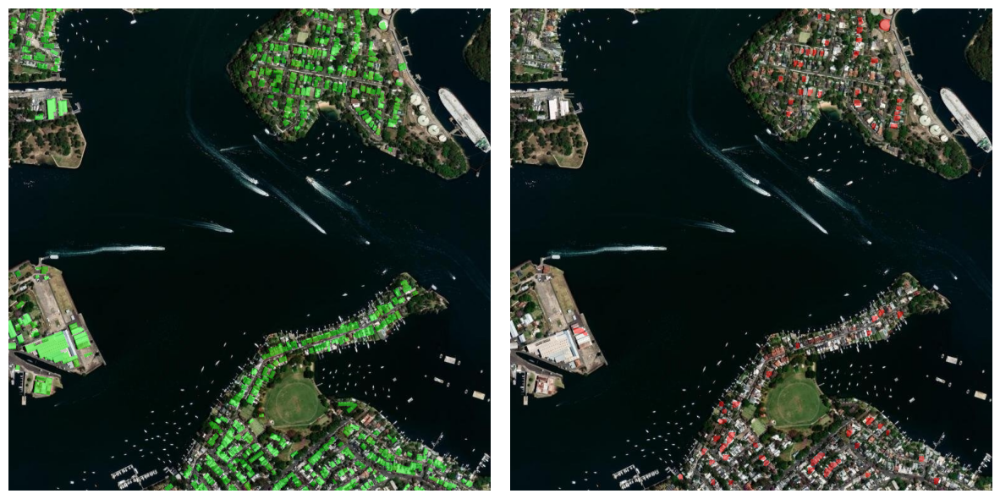

[02] 20096_13107.jpg
      real area      = 138,526 m2
      detected area  = 19,451 m2
      IoU (accuracy) = 0.089


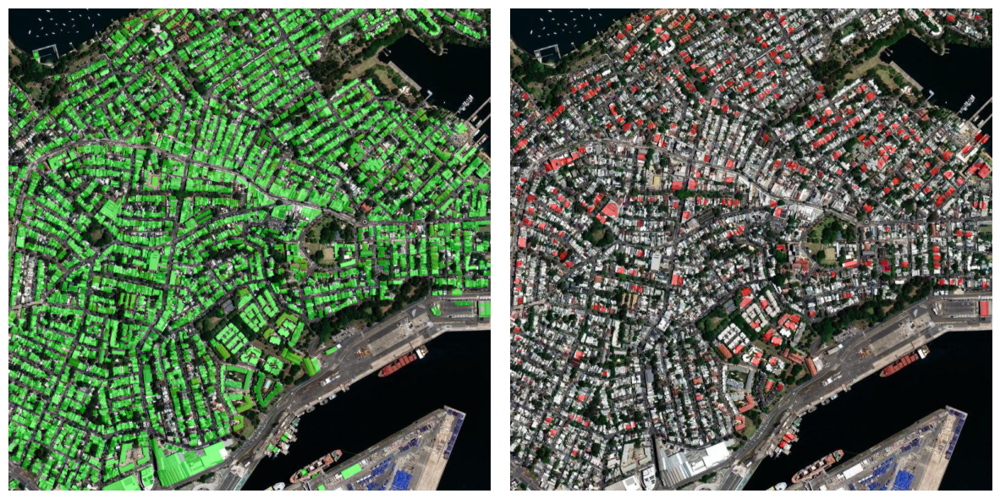

[03] 20096_13108.jpg
      real area      = 697,436 m2
      detected area  = 90,824 m2
      IoU (accuracy) = 0.093


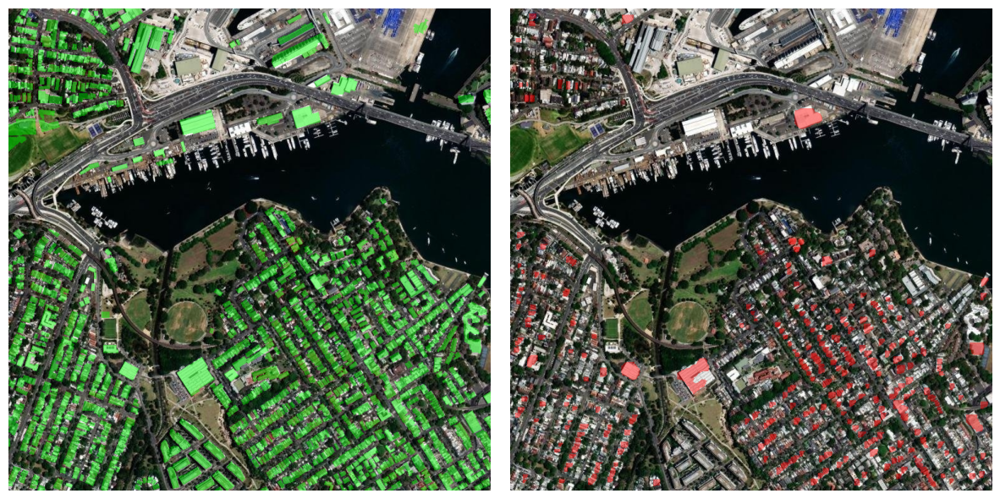

[04] 20096_13109.jpg
      real area      = 458,782 m2
      detected area  = 95,444 m2
      IoU (accuracy) = 0.160


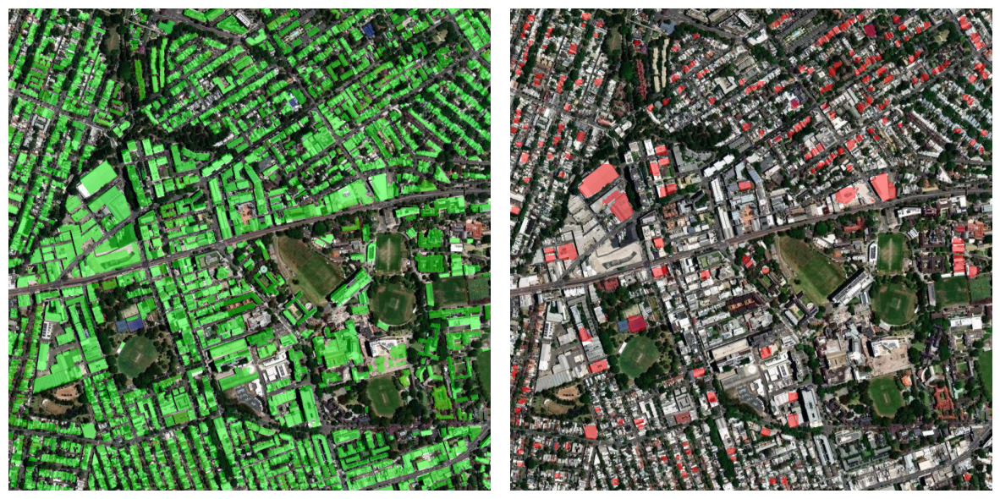

[05] 20096_13110.jpg
      real area      = 839,749 m2
      detected area  = 111,261 m2
      IoU (accuracy) = 0.098


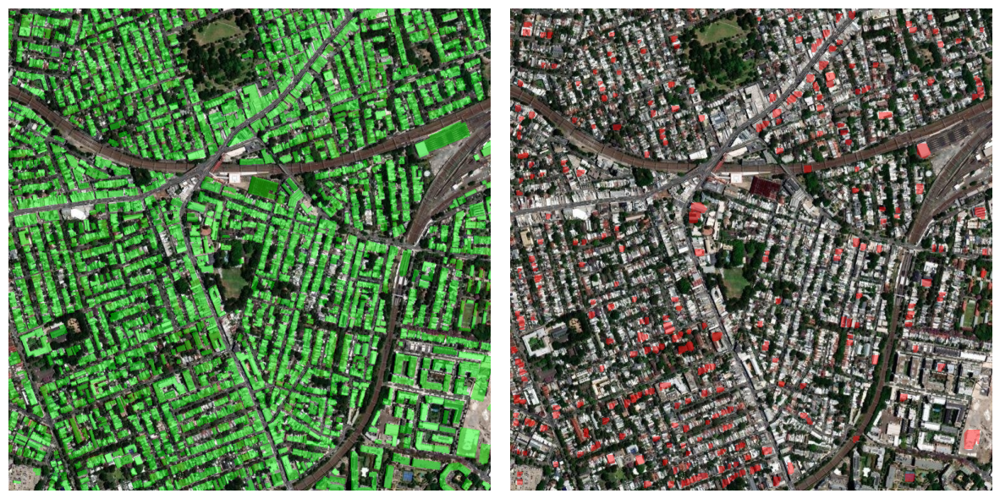

[06] 20096_13111.jpg
      real area      = 919,746 m2
      detected area  = 98,374 m2
      IoU (accuracy) = 0.082


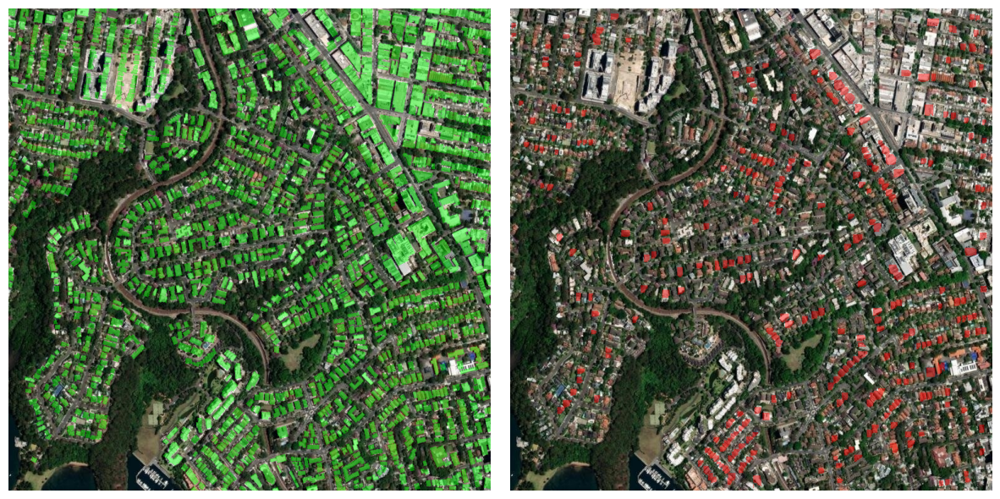

[07] 20097_13106.jpg
      real area      = 629,787 m2
      detected area  = 105,480 m2
      IoU (accuracy) = 0.128


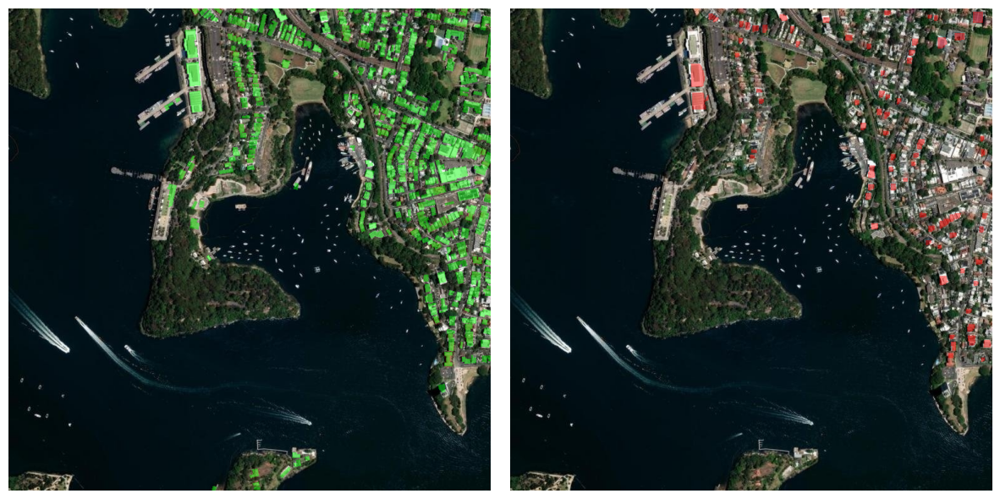

[08] 20097_13107.jpg
      real area      = 160,301 m2
      detected area  = 29,089 m2
      IoU (accuracy) = 0.127


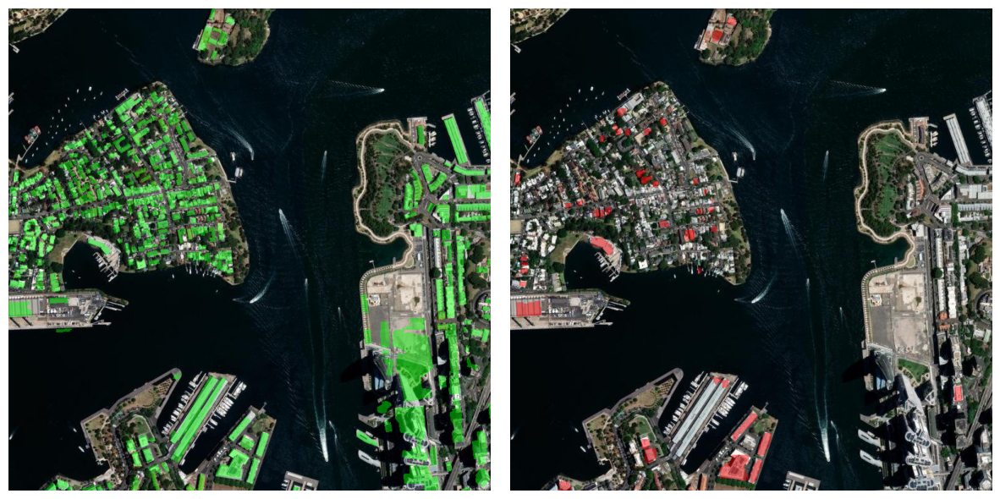

[09] 20097_13108.jpg
      real area      = 254,703 m2
      detected area  = 33,789 m2
      IoU (accuracy) = 0.086


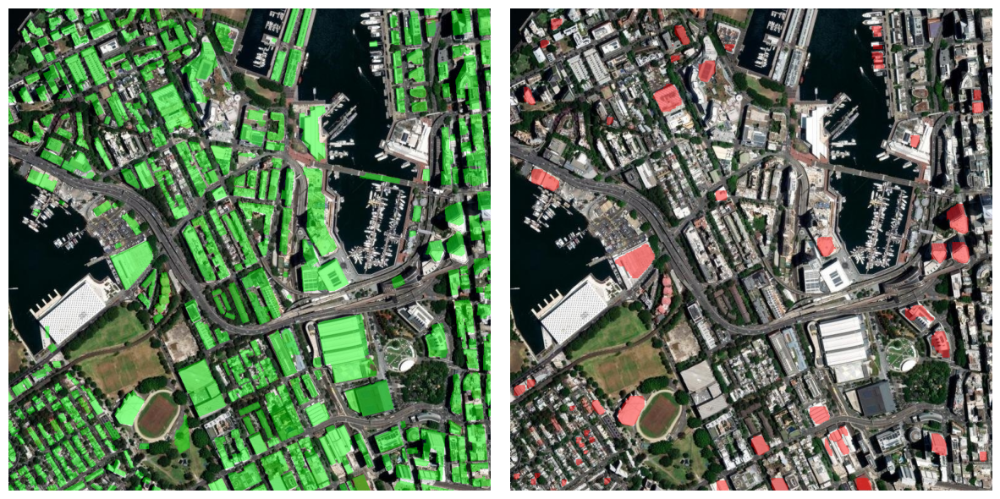

[10] 20097_13109.jpg
      real area      = 657,811 m2
      detected area  = 81,291 m2
      IoU (accuracy) = 0.096


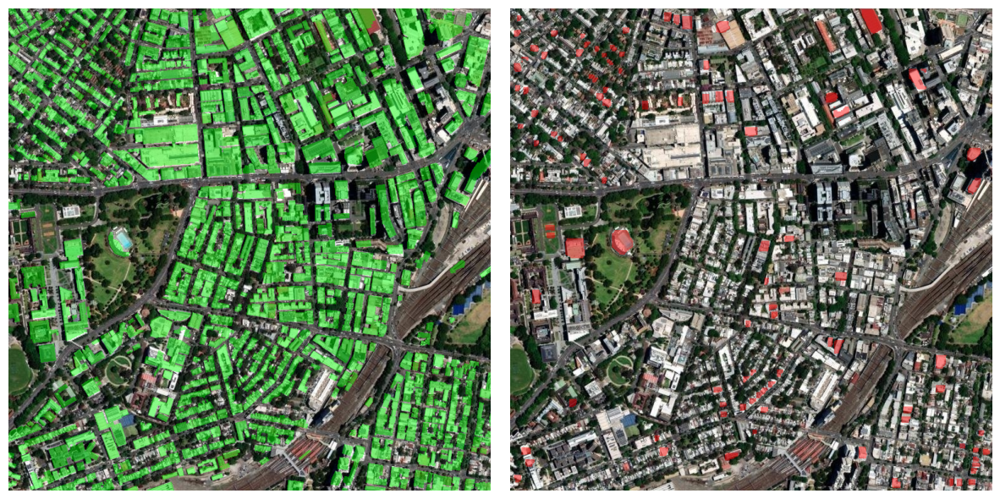

[11] 20097_13110.jpg
      real area      = 856,738 m2
      detected area  = 61,341 m2
      IoU (accuracy) = 0.049


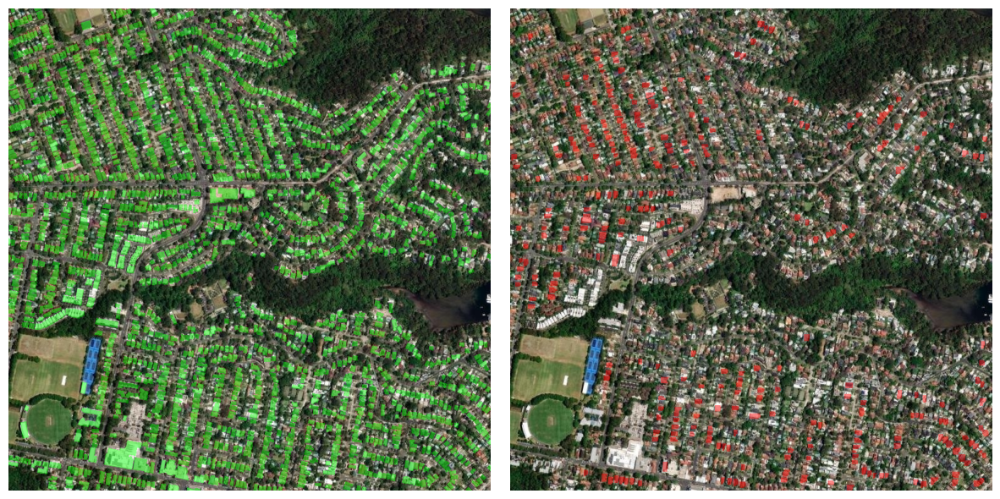

[12] 20098_13104.jpg
      real area      = 519,124 m2
      detected area  = 83,253 m2
      IoU (accuracy) = 0.121


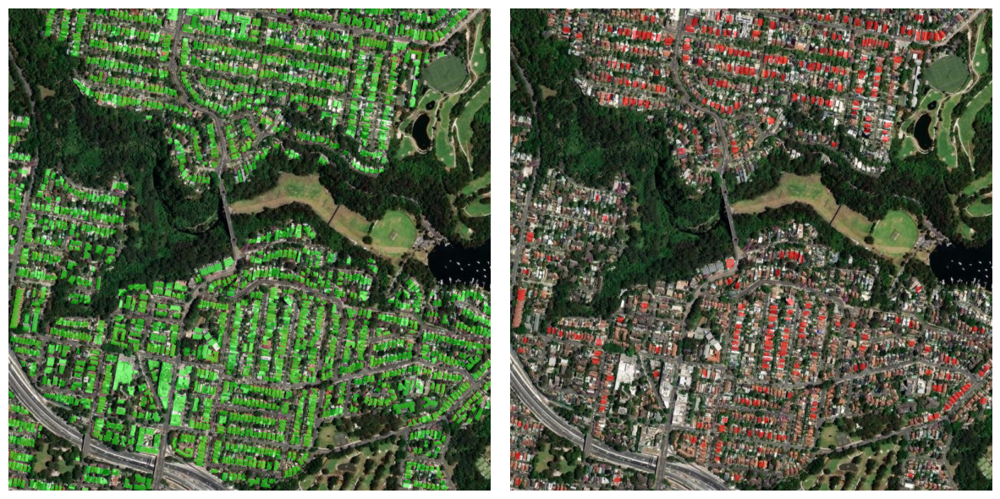

[13] 20098_13105.jpg
      real area      = 471,582 m2
      detected area  = 76,926 m2
      IoU (accuracy) = 0.126


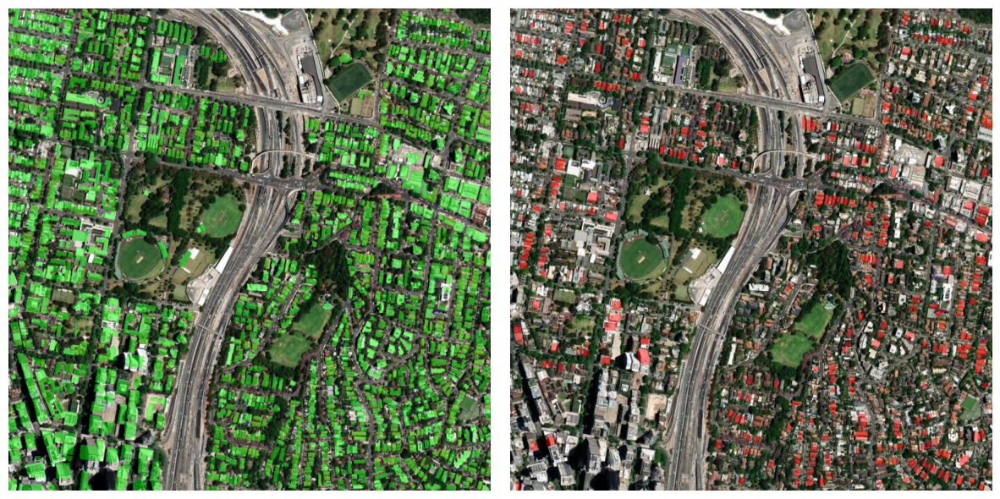

[14] 20098_13106.jpg
      real area      = 610,863 m2
      detected area  = 96,396 m2
      IoU (accuracy) = 0.116


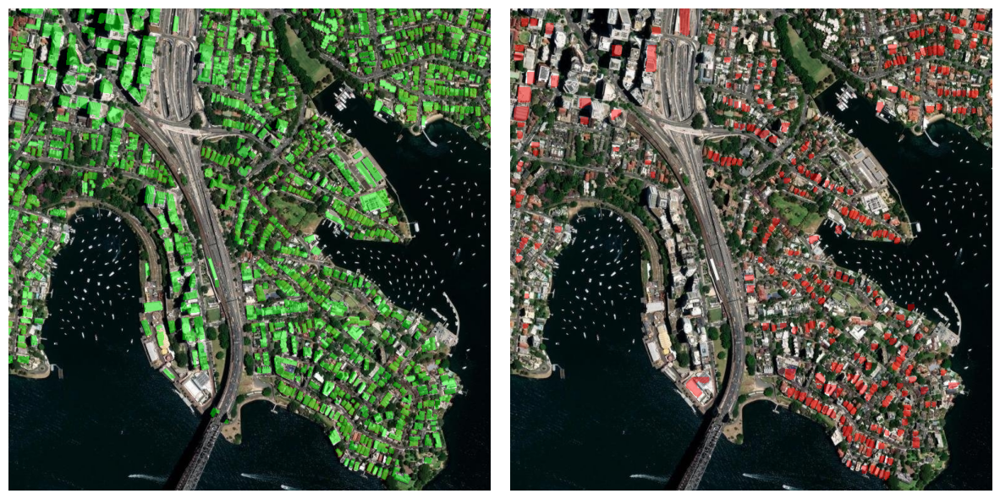

[15] 20098_13107.jpg
      real area      = 402,903 m2
      detected area  = 108,280 m2
      IoU (accuracy) = 0.163


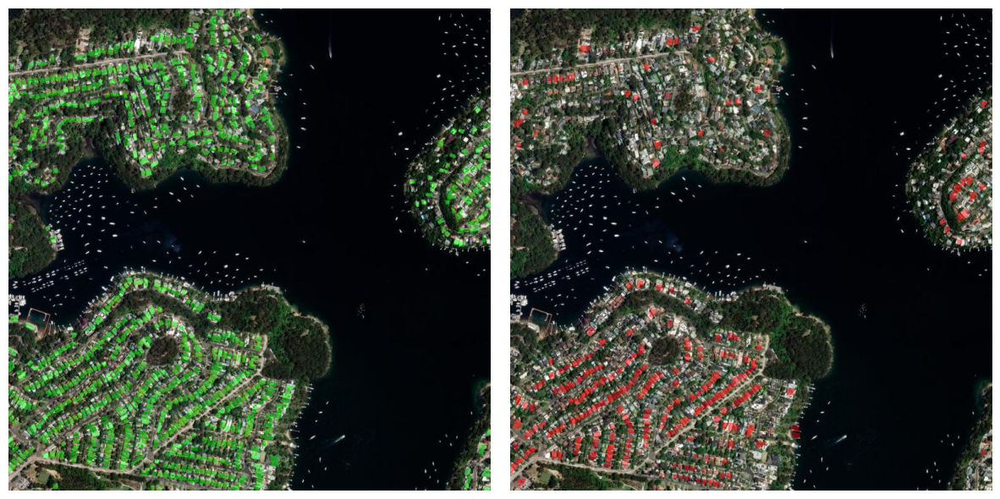

[16] 20099_13104.jpg
      real area      = 206,949 m2
      detected area  = 72,297 m2
      IoU (accuracy) = 0.221


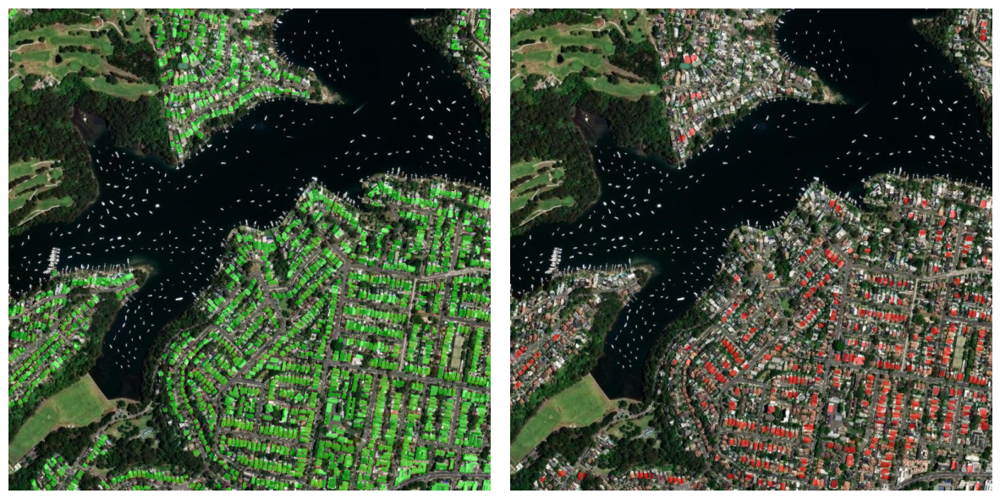

[17] 20099_13105.jpg
      real area      = 345,338 m2
      detected area  = 74,114 m2
      IoU (accuracy) = 0.167


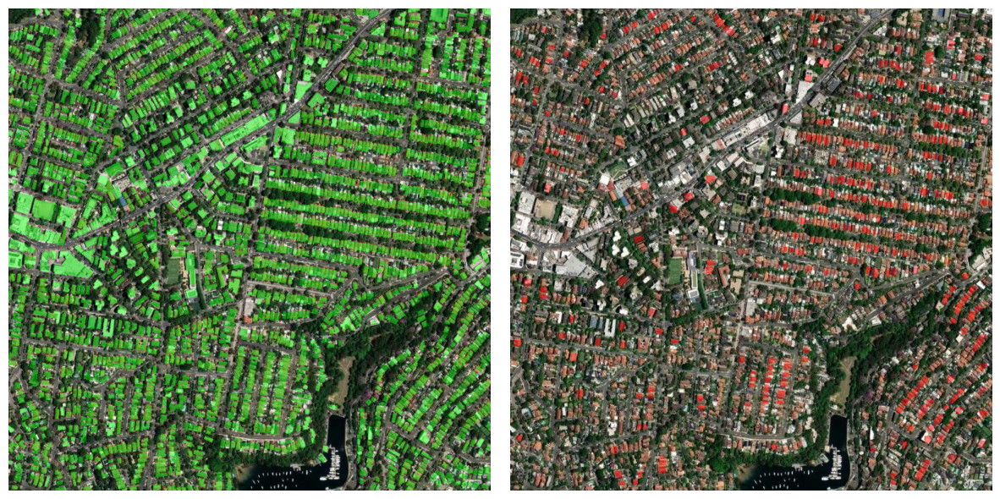

[18] 20099_13106.jpg
      real area      = 746,967 m2
      detected area  = 84,024 m2
      IoU (accuracy) = 0.095


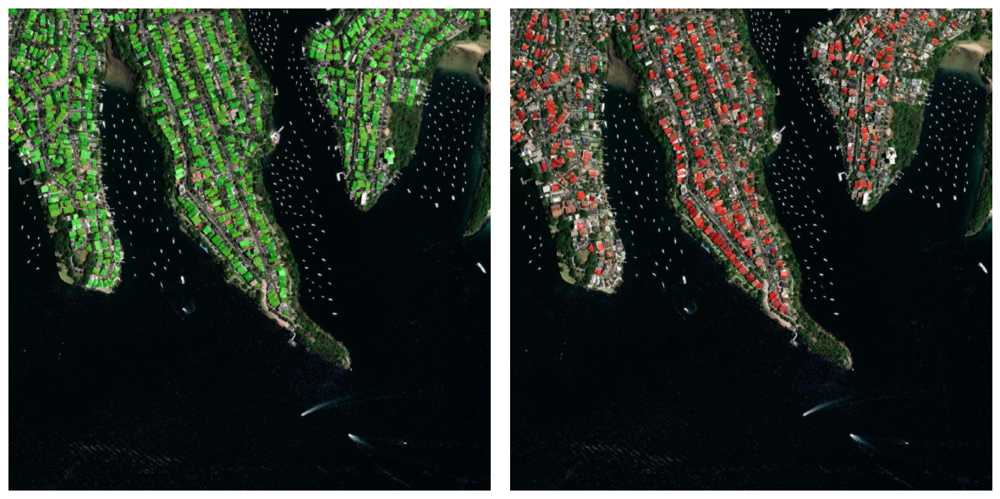

[19] 20099_13107.jpg
      real area      = 202,797 m2
      detected area  = 75,970 m2
      IoU (accuracy) = 0.258
mean IoU over 19 images = 0.127


In [31]:
# ============================================================================
# CELL 21 - دقت سگمنت‌سازی ساختمان روی ۱۰ عکس (مساحت + IoU روی عکس واقعی)
# ----------------------------------------------------------------------------
# برای ۱۰ عکس تست: ماسک پیش‌بینی‌شده رو با برچسب واقعی مقایسه می‌کنه و روی خودِ
# عکس ماهواره‌ای (ESRI) سوار می‌کنه. زیر هر جفت، مساحت واقعی، مساحت تشخیصی و
# IoU رو چاپ می‌کنه. روی عکس هیچ متنی نوشته نمی‌شه.
# ============================================================================
import math
import glob
import cv2
import numpy as np
import matplotlib.pyplot as plt

EVAL_N = 30
          # تعداد عکس‌ها
EVAL_CONF = 0.25     # آستانه اطمینان


# متر بر پیکسل در رزولوشن اصلی پچ (zoom 16) برای عرض جغرافیایی میانی شهر
_lat = (city_bbox[1] + city_bbox[3]) / 2.0
_mpp = 156543.03 * math.cos(math.radians(_lat)) / (2.0 ** zoom)


def _load_gt_mask(img_path, size):
    """پلیگون‌های واقعی YOLO-seg رو به ماسک باینری تبدیل می‌کنه."""
    lbl = img_path.replace(os.path.join(YOLO_DIR, "images"),
                           os.path.join(YOLO_DIR, "labels"))
    lbl = os.path.splitext(lbl)[0] + ".txt"
    mask = np.zeros((size[1], size[0]), np.uint8)
    if not os.path.exists(lbl):
        return mask
    with open(lbl, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.split()
            if len(parts) < 7:
                continue
            pts = (np.asarray(parts[1:], dtype=np.float32).reshape(-1, 2)
                   * np.asarray(size, dtype=np.float32)).astype(np.int32)
            cv2.fillPoly(mask, [pts], 1)
    return mask


def _pred_mask(res, size):
    """اجتماع ماسک‌های پیش‌بینی‌شده در رزولوشن `size`."""
    if res.masks is None or len(res.masks.data) == 0:
        return np.zeros((size[1], size[0]), np.uint8)
    m = (res.masks.data.detach().cpu().numpy() > 0.5).max(axis=0).astype(np.uint8)
    if m.shape[:2] != (size[1], size[0]):
        m = cv2.resize(m, size, interpolation=cv2.INTER_NEAREST)
    return m


def _overlay(img_rgb, mask, color, alpha=0.45):
    """ماسک رو نیمه‌شفاف روی عکس RGB می‌ذاره (بدون هیچ متنی)."""
    m = mask[..., None].astype(np.float32)          # (H, W, 1)
    c = np.asarray(color, dtype=np.float32)         # (3,)
    out = img_rgb.astype(np.float32) * (1.0 - alpha * m) + c * (alpha * m)
    return np.clip(out, 0, 255).astype(np.uint8)


test_imgs = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "test", "*.jpg")))
if len(test_imgs) < EVAL_N:
    test_imgs = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "val", "*.jpg")))
test_imgs = test_imgs[:EVAL_N]
print(f"evaluating {len(test_imgs)} images")

ious = []
for i, img_path in enumerate(test_imgs):
    im = cv2.imread(img_path)                   # BGR
    img_rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    size = (im.shape[1], im.shape[0])           # (W, H)

    gt = _load_gt_mask(img_path, size)
    res = trained.predict(img_path, imgsz=yolo_imgsz, conf=EVAL_CONF,
                          device=device, verbose=False)[0]
    pr = _pred_mask(res, size)

    inter = np.logical_and(gt, pr).sum()
    union = np.logical_or(gt, pr).sum()
    iou = float(inter / union) if union else 0.0
    ious.append(iou)

    gt_area = float(gt.sum()) * _mpp * _mpp
    pr_area = float(pr.sum()) * _mpp * _mpp

    # دو عکس: واقعی (سبز) و پیش‌بینی (قرمز)، هر دو روی خودِ عکس ماهواره‌ای
    show_gt = _overlay(img_rgb, gt, color=(0, 255, 0), alpha=0.45)
    show_pr = _overlay(img_rgb, pr, color=(255, 0, 0), alpha=0.45)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(show_gt)
    axes[1].imshow(show_pr)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    print(f"[{i+1:02d}] {os.path.basename(img_path)}")
    print(f"      real area      = {gt_area:,.0f} m2")
    print(f"      detected area  = {pr_area:,.0f} m2")
    print(f"      IoU (accuracy) = {iou:.3f}")

mean_iou = float(np.mean(ious)) if ious else 0.0
print("=" * 40)
print(f"mean IoU over {len(ious)} images = {mean_iou:.3f}")

evaluating 10 images


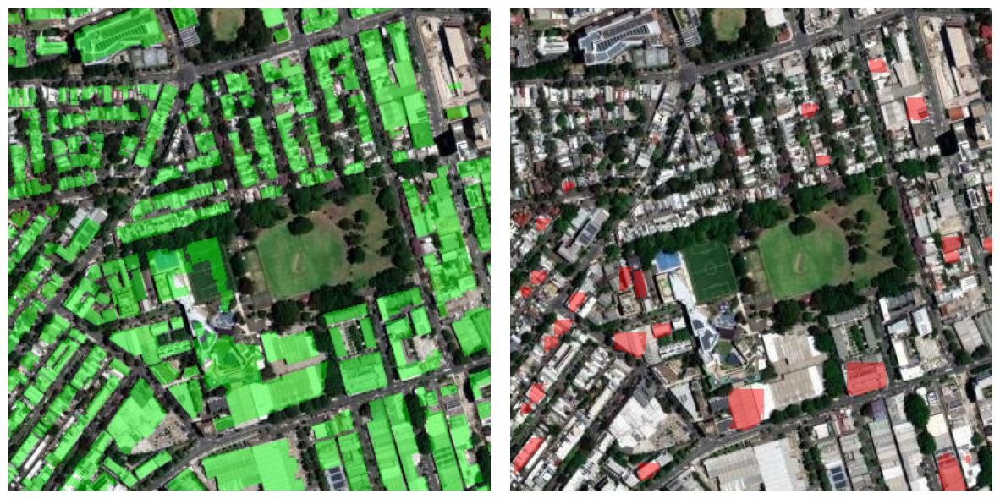

[01] 20097_13111.jpg
      real area      = 877,282 m2
      detected area  = 81,314 m2
      IoU (accuracy) = 0.077


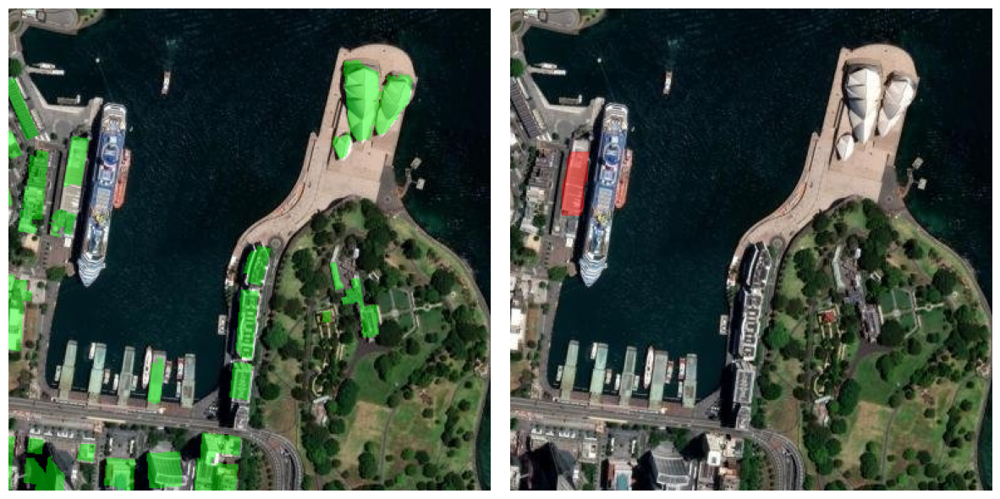

[02] 20098_13108.jpg
      real area      = 244,333 m2
      detected area  = 7,114 m2
      IoU (accuracy) = 0.015


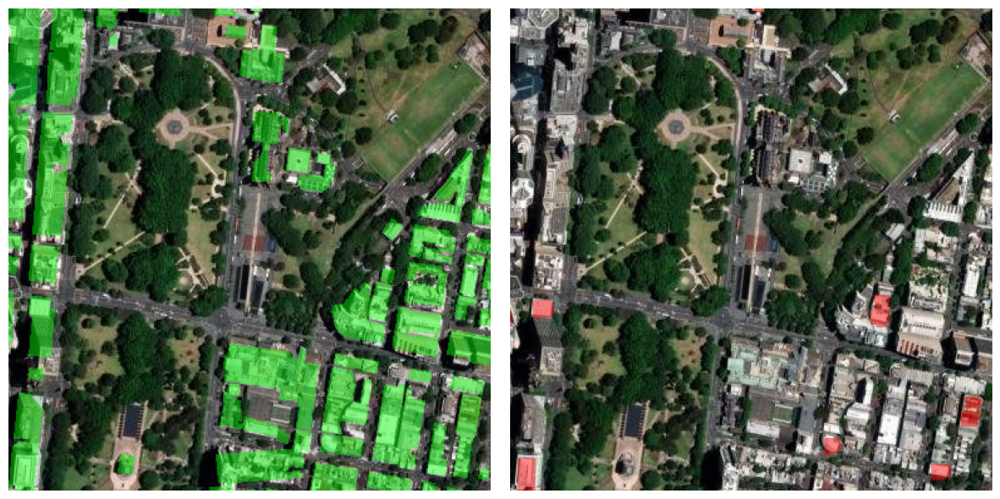

[03] 20098_13109.jpg
      real area      = 843,418 m2
      detected area  = 69,690 m2
      IoU (accuracy) = 0.056


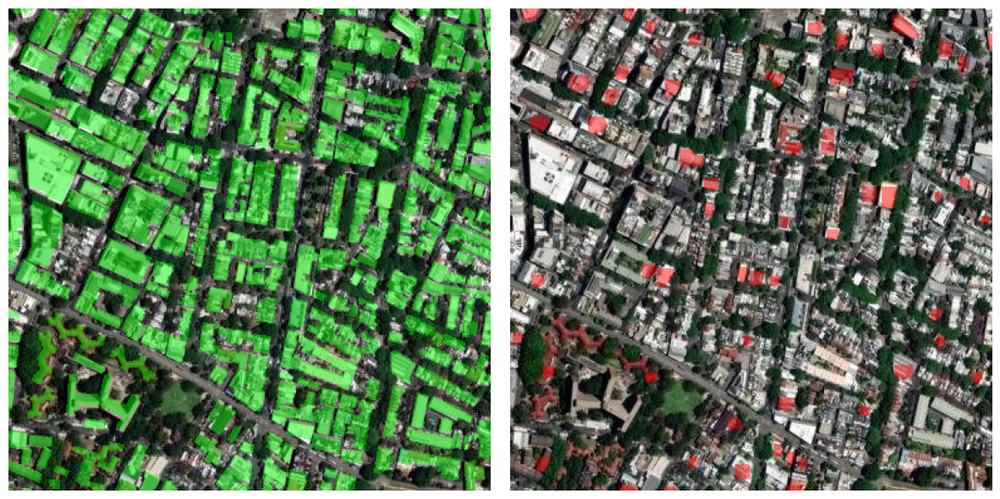

[04] 20098_13110.jpg
      real area      = 809,086 m2
      detected area  = 93,773 m2
      IoU (accuracy) = 0.081


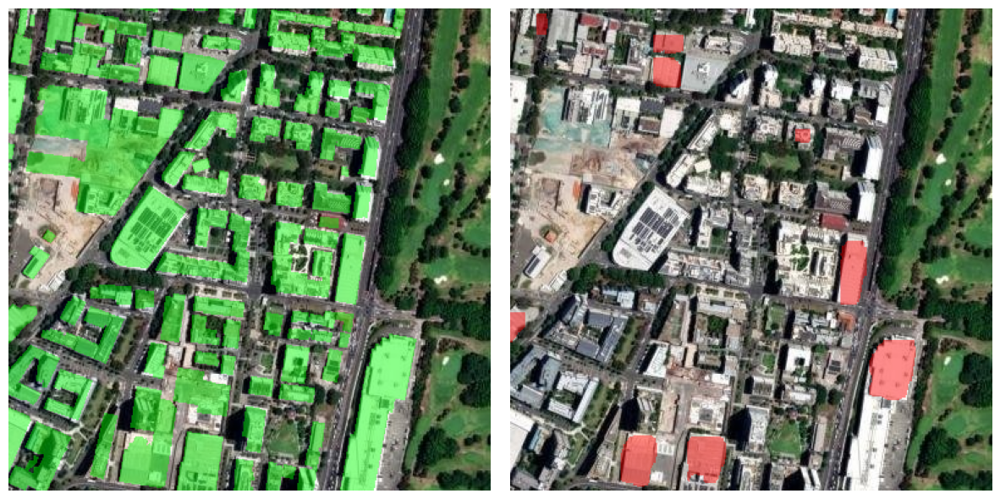

[05] 20098_13111.jpg
      real area      = 630,739 m2
      detected area  = 53,527 m2
      IoU (accuracy) = 0.065


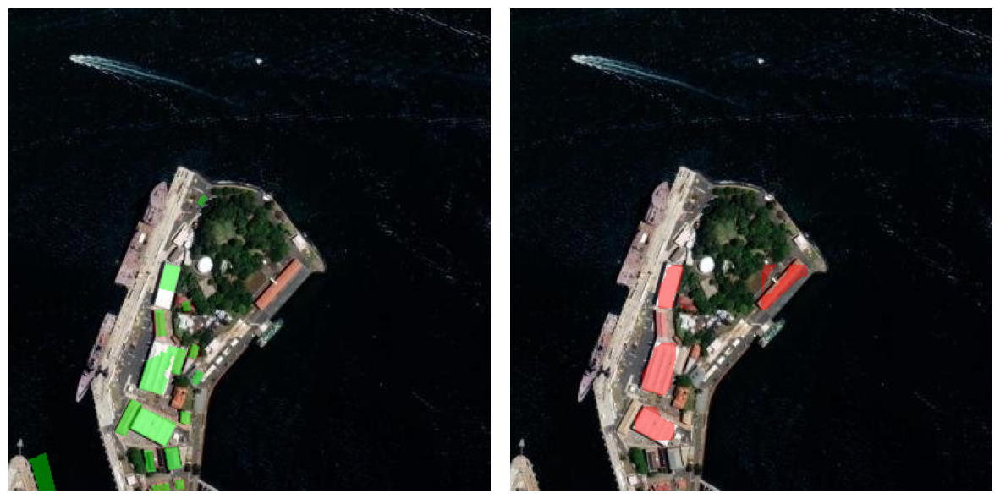

[06] 20099_13108.jpg
      real area      = 47,148 m2
      detected area  = 16,328 m2
      IoU (accuracy) = 0.167


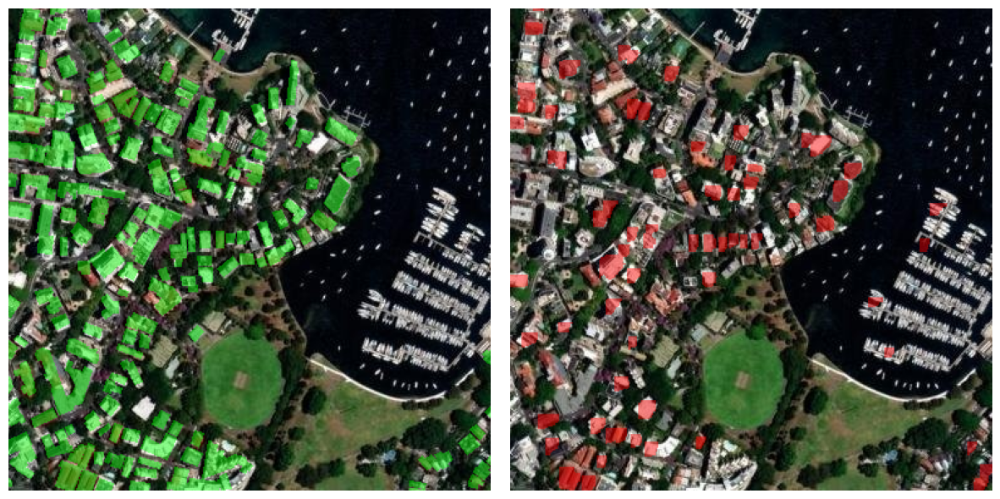

[07] 20099_13109.jpg
      real area      = 538,189 m2
      detected area  = 113,314 m2
      IoU (accuracy) = 0.134


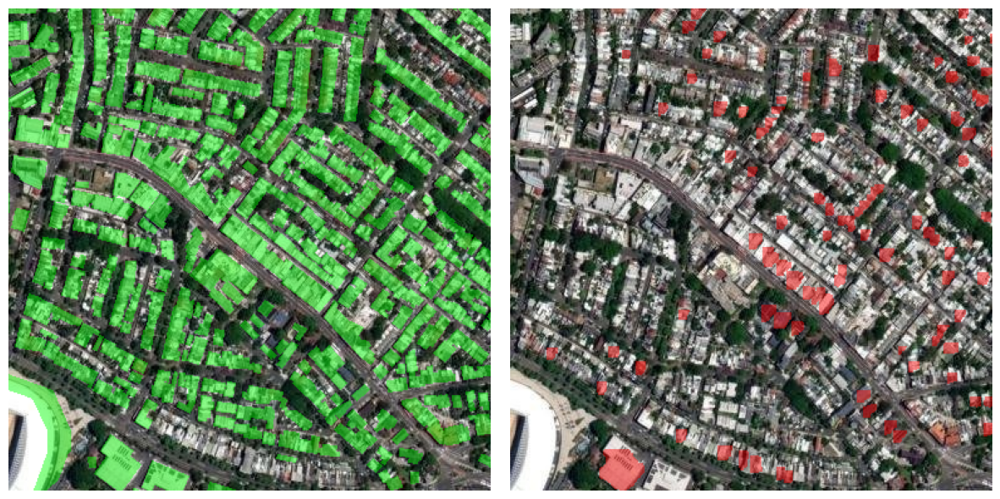

[08] 20099_13110.jpg
      real area      = 693,594 m2
      detected area  = 103,640 m2
      IoU (accuracy) = 0.107


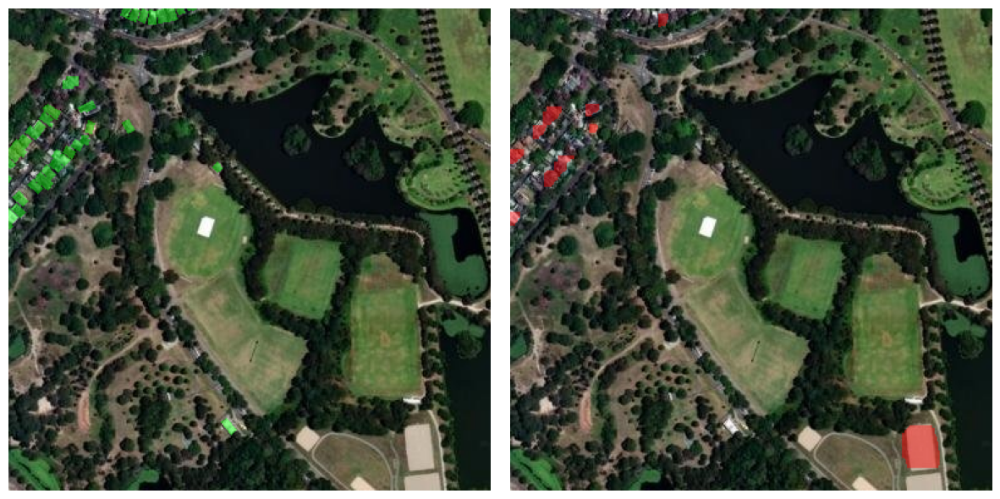

[09] 20099_13111.jpg
      real area      = 215,404 m2
      detected area  = 48,619 m2
      IoU (accuracy) = 0.112


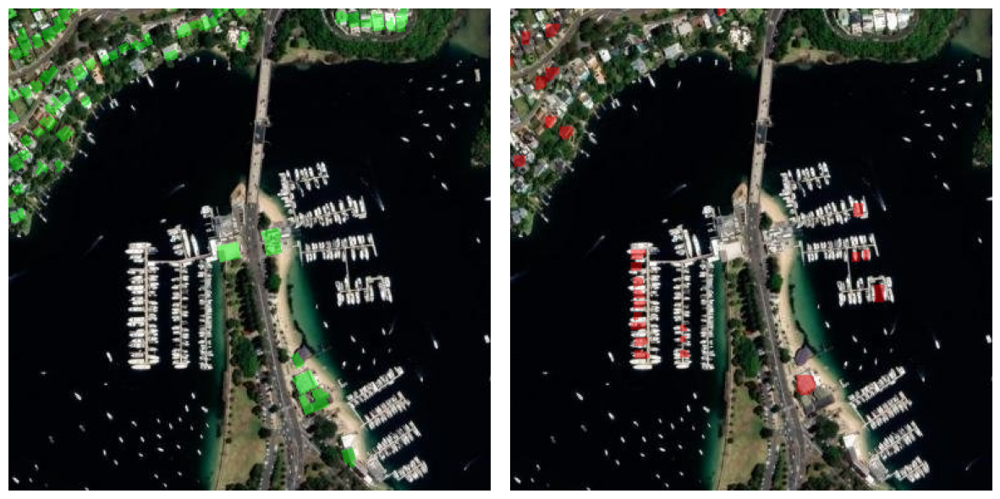

[10] 20100_13104.jpg
      real area      = 236,515 m2
      detected area  = 67,979 m2
      IoU (accuracy) = 0.173
mean IoU over 10 images = 0.099


In [32]:
# ============================================================================
# CELL 21 - دقت سگمنت‌سازی ساختمان روی ۱۰ عکس (روی عکس واقعی + زوم‌شده)
# ----------------------------------------------------------------------------
# برای ۱۰ عکس تست: ماسک پیش‌بینی رو با برچسب واقعی مقایسه می‌کنه و روی خودِ
# عکس ماهواره‌ای (ESRI) نشون می‌ده. با CROP زوم می‌شه تا ساختمان‌ها درشت‌تر
# دیده بشن. زیر هر جفت، مساحت واقعی، مساحت تشخیصی و IoU چاپ می‌شه.
# ============================================================================
import math
import glob
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

EVAL_N = 10          # تعداد عکس‌ها
EVAL_CONF = 0.25     # آستانه اطمینان
CROP = 384           # ضلع برش نمایش (پیکسل). کمتر = ساختمان‌ها بزرگ‌تر


# متر بر پیکسل در رزولوشن اصلی پچ (zoom 16) برای عرض جغرافیایی میانی شهر
_lat = (city_bbox[1] + city_bbox[3]) / 2.0
_mpp = 156543.03 * math.cos(math.radians(_lat)) / (2.0 ** zoom)


def _load_gt_mask(img_path, size):
    """پلیگون‌های واقعی YOLO-seg رو به ماسک باینری تبدیل می‌کنه."""
    lbl = img_path.replace(os.path.join(YOLO_DIR, "images"),
                           os.path.join(YOLO_DIR, "labels"))
    lbl = os.path.splitext(lbl)[0] + ".txt"
    mask = np.zeros((size[1], size[0]), np.uint8)
    if not os.path.exists(lbl):
        return mask
    with open(lbl, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.split()
            if len(parts) < 7:
                continue
            pts = (np.asarray(parts[1:], dtype=np.float32).reshape(-1, 2)
                   * np.asarray(size, dtype=np.float32)).astype(np.int32)
            cv2.fillPoly(mask, [pts], 1)
    return mask


def _pred_mask(res, size):
    """اجتماع ماسک‌های پیش‌بینی‌شده در رزولوشن `size`."""
    if res.masks is None or len(res.masks.data) == 0:
        return np.zeros((size[1], size[0]), np.uint8)
    m = (res.masks.data.detach().cpu().numpy() > 0.5).max(axis=0).astype(np.uint8)
    if m.shape[:2] != (size[1], size[0]):
        m = cv2.resize(m, size, interpolation=cv2.INTER_NEAREST)
    return m


def _overlay(img_rgb, mask, color, alpha=0.45):
    """ماسک رو نیمه‌شفاف روی عکس RGB می‌ذاره (بدون هیچ متنی)."""
    m = mask[..., None].astype(np.float32)          # (H, W, 1)
    c = np.asarray(color, dtype=np.float32)         # (3,)
    out = img_rgb.astype(np.float32) * (1.0 - alpha * m) + c * (alpha * m)
    return np.clip(out, 0, 255).astype(np.uint8)


test_imgs = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "test", "*.jpg")))
if len(test_imgs) < EVAL_N:
    test_imgs = sorted(glob.glob(os.path.join(YOLO_DIR, "images", "val", "*.jpg")))
test_imgs = test_imgs[:EVAL_N]
print(f"evaluating {len(test_imgs)} images")

ious = []
for i, img_path in enumerate(test_imgs):
    im = cv2.imread(img_path)                   # BGR
    img_rgb = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
    size = (im.shape[1], im.shape[0])           # (W, H)

    gt = _load_gt_mask(img_path, size)
    res = trained.predict(img_path, imgsz=yolo_imgsz, conf=EVAL_CONF,
                          device=device, verbose=False)[0]
    pr = _pred_mask(res, size)

    inter = np.logical_and(gt, pr).sum()
    union = np.logical_or(gt, pr).sum()
    iou = float(inter / union) if union else 0.0
    ious.append(iou)

    gt_area = float(gt.sum()) * _mpp * _mpp
    pr_area = float(pr.sum()) * _mpp * _mpp

    # برشِ زوم‌شده برای نمایش (مساحت و IoU همچنان روی کل عکس حساب می‌شن)
    H, W = size[1], size[0]
    if CROP and CROP < min(H, W):
        y0, x0 = (H - CROP) // 2, (W - CROP) // 2
        img_c = img_rgb[y0:y0 + CROP, x0:x0 + CROP]
        gt_c  = gt[y0:y0 + CROP, x0:x0 + CROP]
        pr_c  = pr[y0:y0 + CROP, x0:x0 + CROP]
    else:
        img_c, gt_c, pr_c = img_rgb, gt, pr

    show_gt = _overlay(img_c, gt_c, color=(0, 255, 0), alpha=0.45)
    show_pr = _overlay(img_c, pr_c, color=(255, 0, 0), alpha=0.45)

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    axes[0].imshow(show_gt)
    axes[1].imshow(show_pr)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    print(f"[{i+1:02d}] {os.path.basename(img_path)}")
    print(f"      real area      = {gt_area:,.0f} m2")
    print(f"      detected area  = {pr_area:,.0f} m2")
    print(f"      IoU (accuracy) = {iou:.3f}")

mean_iou = float(np.mean(ious)) if ious else 0.0
print("=" * 40)
print(f"mean IoU over {len(ious)} images = {mean_iou:.3f}")